In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
#part1
import os
import sys
import gc
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
import torch

main_folder = "../.."
sys.path.insert(0, os.path.join(main_folder))

from src.config import EXP_CONFIGS
from src.inference_feedback import (
    extract_aux_oof_to_csv,
    sweep_thresholds, uncertainty_band, assign_reliability,
    load_model,
    run_batch,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

TARGET     = "Pawpularity"
IMG_FOLDER = os.path.join(main_folder, "data", "train")
CSV_PATH   = os.path.join(main_folder, "data", "train.csv")
df         = pd.read_csv(CSV_PATH)
AUX_TASKS  = ["Eyes","Face","Occlusion", "Blur",
                             "Subject Focus","Action","Accessory",
                             "Near", "Group","Collage","Human", "Info"]
SWIN_GRID  = (12, 12)

# exp19: standard BCE aux heads
out_dir_exp19 = os.path.join(main_folder, "outputs", "extra",
                             "exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion")

cfg_exp19 = EXP_CONFIGS["exp15_aux_brisque"].copy()
cfg_exp19["img_size"] = 384
cfg_exp19["name"] = "exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion"
cfg_exp19["loss"] = "mse"
cfg_exp19["head_type"] = "mlp"
cfg_exp19["aux_tasks"] = []
cfg_exp19["binary_aux_tasks"]   = ["Eyes","Face","Occlusion", "Blur",
                             "Subject Focus","Action","Accessory",
                             "Near", "Group","Collage","Human", "Info"]  # all 12 binary aux tasks
cfg_exp19["aux_loss_weights"]   = {
    "Face":      0.1,
    "Eyes":      0.1,
    "Occlusion": 0.1,
    "Blur":      0.1,
    "Subject Focus": 0.1,
    "Action": 0.1,
    "Accessory": 0.1,
    "Group": 0.1,
    "Collage": 0.1,
    "Human": 0.1,
    "Info": 0.1,
    "Near": 0.1
}
cfg_exp19["use_saliency"] = False

ACTIVE_CFG = cfg_exp19
ACTIVE_DIR = out_dir_exp19


/home/ghias/miniconda3/envs/rapids-env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


In [3]:
#part2
# To create the aux head with the probabilities for each record and each aux head and save it to a CSV file
aux_df = extract_aux_oof_to_csv(
    out_dir=ACTIVE_DIR,
    df=df,
    img_folder=IMG_FOLDER,
    cfg=ACTIVE_CFG,
    device=device,
)

Loading existing: ../../outputs/extra/exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion/oof_detail_aux.csv


In [5]:
#part3
aux_df.head()

,Id,fold,ytrue,Eyes_true,Eyes_prob,Eyes_pred_05,Face_true,Face_prob,Face_pred_05,Occlusion_true,...,Group_pred_05,Collage_true,Collage_prob,Collage_pred_05,Human_true,Human_prob,Human_pred_05,Info_true,Info_prob,Info_pred_05
0,0007de18844b0dbbb5e1f607da0606e0,1,63.0,1,0.800557,1,1,0.923141,1,0,...,0,0,0.067400,0,0,0.272856,0,0,0.081145,0
1,0018df346ac9c1d8413cfcc888ca8246,1,15.0,1,0.735342,1,1,0.900173,1,0,...,0,0,0.045323,0,0,0.210455,0,0,0.062315,0
2,0042bc5bada6d1cf8951f8f9f0d399fa,1,53.0,1,0.750277,1,1,0.911344,1,0,...,0,0,0.042449,0,0,0.157305,0,0,0.058219,0
3,005017716086b8d5e118dd9fe26459b1,1,28.0,1,0.858519,1,1,0.952724,1,0,...,0,0,0.030480,0,0,0.152466,0,0,0.044842,0
4,00630b1262efe301cb15a3b2022ba744,1,18.0,1,0.771668,1,1,0.912375,1,0,...,0,0,0.039415,0,0,0.117797,0,0,0.047521,0


Raw OOF calibration summary for all 12 auxiliary heads:


,task,n,n_positive,n_negative,positive_rate,raw_prob_min,raw_prob_max,raw_brier,raw_ece
0,Eyes,9912,7658,2254,0.7726,0.3084,0.9246,0.1577,0.0683
1,Near,9912,8540,1372,0.8616,0.2667,0.9805,0.1019,0.0641
2,Face,9912,8960,952,0.9040,0.5008,0.9733,0.0785,0.0559
3,Occlusion,9912,1705,8207,0.1720,0.0638,0.4775,0.1279,0.0557
4,Human,9912,1648,8264,0.1663,0.0513,0.5021,0.1228,0.0472
5,Group,9912,1282,8630,0.1293,0.0403,0.6485,0.1015,0.0450
6,Info,9912,607,9305,0.0612,0.0222,0.3674,0.0538,0.0232
7,Accessory,9912,672,9240,0.0678,0.0327,0.1572,0.0620,0.0143
8,Blur,9912,698,9214,0.0704,0.0287,0.1250,0.0651,0.0092
9,Collage,9912,492,9420,0.0496,0.0181,0.2523,0.0444,0.0088


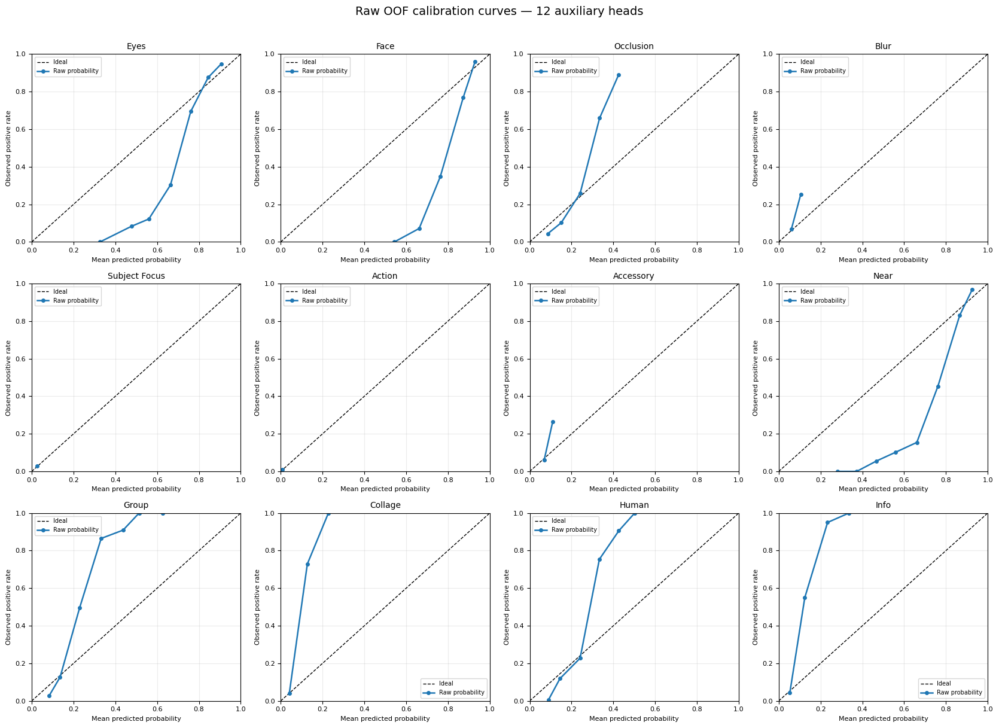

In [6]:
# =====================part4=======================================
# SECTION 2 — STEP 2A: Raw probability calibration diagnosis
#
#  
# "Evaluate the calibration status of each label using:
#  1. Calibration curve
#  2. Brier score
#  3. Expected Calibration Error (ECE)"
#
# Uses:
# - all 12 auxiliary heads
# - all pooled OOF records
# 
#
# ============================================================

from src.aux_calibration import (
    diagnose_raw_oof_calibration,
    plot_calibration_curves,
)

# All 12 heads are analysed first.
# We will decide later which labels are usable for user-facing feedback.
CALIBRATION_TASKS = AUX_TASKS.copy()

raw_calibration_summary, raw_bin_tables = (
    diagnose_raw_oof_calibration(
        aux_df=aux_df,
        aux_tasks=CALIBRATION_TASKS,
        n_bins=10,
    )
)

# Sort worst-to-best by raw ECE only for inspection.
# This is not a final decision rule because ECE can be unstable for
# extremely rare labels; the calibration curve and Brier score matter too.
raw_calibration_summary = raw_calibration_summary.sort_values(
    "raw_ece",
    ascending=False,
).reset_index(drop=True)

print("Raw OOF calibration summary for all 12 auxiliary heads:")
display(raw_calibration_summary.round(4))

plot_calibration_curves(
    bin_tables=raw_bin_tables,
    aux_tasks=CALIBRATION_TASKS,
    title="Raw OOF calibration curves — 12 auxiliary heads",
    n_cols=4,
    method_label="Raw probability",
)

The raw reliability diagrams show that the auxiliary-head probabilities are not uniformly calibrated: some labels overestimate the positive rate while others underestimate it.

Each plotted point represents a probability bin with mean predicted probability on the x-axis and observed positive rate on the y-axis; perfect calibration lies on the dashed diagonal line.

In [16]:
# ===================== part 5 =====================================
# SECTION 2 — STEP 2B
# Split-aware calibration method selection
#
# Folds 1,2,3:
#   - choose raw / Platt / isotonic per auxiliary head
#   - produce cross-fitted selected probabilities for threshold search
#
# Folds 4,5:
#   - do NOT influence method selection
#   - receive probabilities from calibrators fitted only on folds 1,2,3
#
# No selective thresholds are chosen in this part.
# ================================================================

from src.aux_calibration import (
    crossfit_calibration_all_tasks,
    select_calibration_methods_all_tasks,
    fit_platt_calibrator,
    fit_isotonic_calibrator,
    apply_calibrator,
)

# ------------------------------------------------------------
# 0. Define the selection/evaluation split BEFORE method choice
# ------------------------------------------------------------

THRESHOLD_SELECTION_FOLDS = [1, 2, 3]
THRESHOLD_EVALUATION_FOLDS = [4, 5]

calibration_selection_aux_df = aux_df[
    aux_df["fold"].isin(THRESHOLD_SELECTION_FOLDS)
].copy()

calibration_evaluation_aux_df = aux_df[
    aux_df["fold"].isin(THRESHOLD_EVALUATION_FOLDS)
].copy()

print("Calibration-method selection samples:", len(calibration_selection_aux_df))
print("Final-evaluation samples:", len(calibration_evaluation_aux_df))


# ------------------------------------------------------------
# 1. Cross-fit calibration ONLY inside folds 1,2,3
# ------------------------------------------------------------

(
    calibration_probability_selection_df,
    calibration_results,
    bin_tables_by_task,
) = crossfit_calibration_all_tasks(
    aux_df=calibration_selection_aux_df,
    aux_tasks=CALIBRATION_TASKS,
    fold_col="fold",
    n_bins=10,
)

print(
    "\nCalibration comparison on selection folds only "
    "(raw / Platt / isotonic):"
)
display(calibration_results.round(6))


# ------------------------------------------------------------
# 2. Select one probability method per task using folds 1,2,3 only
# ------------------------------------------------------------

calibration_selection_df = select_calibration_methods_all_tasks(
    comparison_df=calibration_results,
    aux_tasks=CALIBRATION_TASKS,
    min_brier_improvement=0.0,
    min_ece_improvement=0.0,
)

print("\nSelected probability method per auxiliary head:")
display(calibration_selection_df.round(6))

SELECTED_METHODS = dict(
    zip(
        calibration_selection_df["task"],
        calibration_selection_df["selected_method"],
    )
)

print("\nSelected methods:")
print(SELECTED_METHODS)


# ------------------------------------------------------------
# 3. Build selected probabilities for folds 1,2,3
#
# These are cross-fitted within the selection folds.
# ------------------------------------------------------------

threshold_selection_df = calibration_probability_selection_df[
    ["Id", "fold"]
].copy()

for task in CALIBRATION_TASKS:
    threshold_selection_df[f"{task}_true"] = (
        calibration_probability_selection_df[f"{task}_true"]
    )

    method = SELECTED_METHODS[task]

    if method == "raw":
        source_col = f"{task}_prob_raw"
    elif method == "platt":
        source_col = f"{task}_prob_platt_cf"
    elif method == "isotonic":
        source_col = f"{task}_prob_isotonic_cf"
    else:
        raise ValueError(f"Unknown method for {task}: {method}")

    threshold_selection_df[f"{task}_prob_selected"] = (
        calibration_probability_selection_df[source_col]
    )


# ------------------------------------------------------------
# 4. Build selected probabilities for folds 4,5
#
# Fit final calibrators on folds 1,2,3 only.
# Apply them to folds 4,5.
# ------------------------------------------------------------

threshold_evaluation_df = calibration_evaluation_aux_df[
    ["Id", "fold"]
].copy()

for task in CALIBRATION_TASKS:
    true_col = f"{task}_true"
    prob_col = f"{task}_prob"

    threshold_evaluation_df[f"{task}_true"] = (
        calibration_evaluation_aux_df[true_col].to_numpy(dtype=int)
    )

    method = SELECTED_METHODS[task]

    y_fit = calibration_selection_aux_df[true_col].to_numpy(dtype=int)
    p_fit = calibration_selection_aux_df[prob_col].to_numpy(dtype=float)
    p_eval = calibration_evaluation_aux_df[prob_col].to_numpy(dtype=float)

    if method == "raw":
        selected_eval_prob = p_eval

    elif method == "platt":
        p_fit_clipped = np.clip(p_fit, 1e-7, 1 - 1e-7)
        p_eval_clipped = np.clip(p_eval, 1e-7, 1 - 1e-7)

        score_fit = np.log(p_fit_clipped / (1.0 - p_fit_clipped))
        score_eval = np.log(p_eval_clipped / (1.0 - p_eval_clipped))

        platt_model = fit_platt_calibrator(
            y_score_fit=score_fit,
            y_true_fit=y_fit,
        )

        selected_eval_prob = apply_calibrator(
            y_prob=score_eval,
            method="platt",
            calibrator=platt_model,
        )

    elif method == "isotonic":
        isotonic_model = fit_isotonic_calibrator(
            y_prob_fit=p_fit,
            y_true_fit=y_fit,
        )

        selected_eval_prob = apply_calibrator(
            y_prob=p_eval,
            method="isotonic",
            calibrator=isotonic_model,
        )

    else:
        raise ValueError(f"Unknown method for {task}: {method}")

    threshold_evaluation_df[f"{task}_prob_selected"] = selected_eval_prob


# ------------------------------------------------------------
# 5. Combine back into one dataframe for later parts
# ------------------------------------------------------------

aux_selected_df = pd.concat(
    [threshold_selection_df, threshold_evaluation_df],
    axis=0,
    ignore_index=True,
)

aux_selected_df = aux_selected_df.sort_values(["fold", "Id"]).reset_index(drop=True)

print("\nBuilt split-clean aux_selected_df.")
print("Threshold-selection samples:", len(threshold_selection_df))
print("Final-evaluation samples:", len(threshold_evaluation_df))
print("Total samples:", len(aux_selected_df))
display(aux_selected_df.head())

Calibration-method selection samples: 5948
Final-evaluation samples: 3964

Calibration comparison on selection folds only (raw / Platt / isotonic):


,task,method,n,positive_rate,brier,ece
0,Eyes,platt,5948,0.772360,0.146659,0.021474
1,Eyes,isotonic,5948,0.772360,0.149021,0.028619
2,Eyes,raw,5948,0.772360,0.158234,0.068026
3,Face,platt,5948,0.905010,0.068983,0.008712
4,Face,isotonic,5948,0.905010,0.069520,0.016726
5,Face,raw,5948,0.905010,0.076865,0.058107
6,Occlusion,isotonic,5948,0.172495,0.115877,0.015094
7,Occlusion,platt,5948,0.172495,0.118490,0.040870
8,Occlusion,raw,5948,0.172495,0.128459,0.054460
9,Blur,raw,5948,0.071284,0.066081,0.014441



Selected probability method per auxiliary head:


,task,selected_method,raw_brier,raw_ece,selected_brier,selected_ece,brier_improvement,ece_improvement
0,Eyes,platt,0.158234,0.068026,0.146659,0.021474,0.011576,0.046552
1,Face,platt,0.076865,0.058107,0.068983,0.008712,0.007882,0.049395
2,Occlusion,isotonic,0.128459,0.054460,0.115877,0.015094,0.012582,0.039366
3,Blur,raw,0.066081,0.014441,0.066081,0.014441,0.000000,0.000000
4,Subject Focus,raw,0.026336,0.003201,0.026336,0.003201,0.000000,0.000000
5,Action,platt,0.010324,0.001018,0.010316,0.000012,0.000008,0.001006
6,Accessory,raw,0.061262,0.020091,0.061262,0.020091,0.000000,0.000000
7,Near,platt,0.107336,0.081346,0.087402,0.010740,0.019934,0.070606
8,Group,platt,0.102850,0.044240,0.092452,0.011033,0.010398,0.033207
9,Collage,platt,0.047813,0.010428,0.043702,0.006013,0.004111,0.004415



Selected methods:
{'Eyes': 'platt', 'Face': 'platt', 'Occlusion': 'isotonic', 'Blur': 'raw', 'Subject Focus': 'raw', 'Action': 'platt', 'Accessory': 'raw', 'Near': 'platt', 'Group': 'platt', 'Collage': 'platt', 'Human': 'isotonic', 'Info': 'isotonic'}

Built split-clean aux_selected_df.
Threshold-selection samples: 5948
Final-evaluation samples: 3964
Total samples: 9912


,Id,fold,Eyes_true,Eyes_prob_selected,Face_true,Face_prob_selected,Occlusion_true,Occlusion_prob_selected,Blur_true,Blur_prob_selected,...,Near_true,Near_prob_selected,Group_true,Group_prob_selected,Collage_true,Collage_prob_selected,Human_true,Human_prob_selected,Info_true,Info_prob_selected
0,0007de18844b0dbbb5e1f607da0606e0,1,1,0.702406,1,0.951219,0,0.228477,0,0.066545,...,1,0.851416,1,0.068033,0,0.184331,0,0.362500,0,0.184615
1,0018df346ac9c1d8413cfcc888ca8246,1,1,0.453247,1,0.894473,0,0.228387,0,0.076648,...,1,0.916140,0,0.038009,0,0.053164,0,0.226500,0,0.056517
2,0042bc5bada6d1cf8951f8f9f0d399fa,1,1,0.508708,1,0.925396,0,0.094787,0,0.079685,...,1,0.902243,0,0.058878,0,0.042826,0,0.107527,0,0.041916
3,005017716086b8d5e118dd9fe26459b1,1,1,0.884340,1,0.988732,0,0.162055,0,0.060729,...,1,0.975346,0,0.029396,0,0.014125,0,0.100503,0,0.034586
4,00630b1262efe301cb15a3b2022ba744,1,1,0.591340,1,0.927929,0,0.035785,0,0.078894,...,1,0.636436,0,0.149696,0,0.033472,0,0.046338,0,0.034586


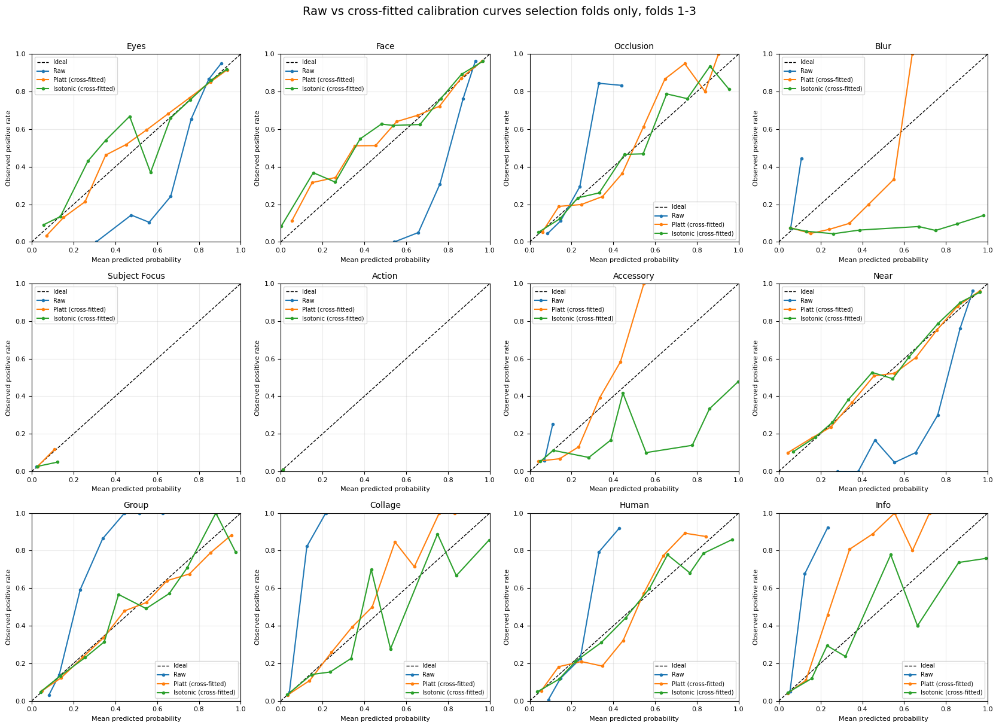

In [17]:
# ===================== part 6 =====================================
# SECTION 2 — STEP 2C
# Visual comparison of raw vs cross-fitted calibration

# - Compare raw, Platt, and isotonic reliability curves.
# - Curves are computed on the calibration-method selection folds only.
# - Folds 4 and 5 are not used in this diagnostic.
# ================================================================

from src.aux_calibration import (
    plot_calibration_comparison,
)

plot_calibration_comparison(
    bin_tables_by_task=bin_tables_by_task,
    aux_tasks=CALIBRATION_TASKS,
    title=(
        "Raw vs cross-fitted calibration curves "
        "selection folds only, folds 1-3"
    ),
    n_cols=4,
)

In [18]:
# ===================== part 7 =====================================
# SECTION 3 — STEP 3A
# Verify fixed threshold-selection / evaluation split
# ================================================================

assert set(threshold_selection_df["fold"].unique()) == set(THRESHOLD_SELECTION_FOLDS)
assert set(threshold_evaluation_df["fold"].unique()) == set(THRESHOLD_EVALUATION_FOLDS)

assert len(threshold_selection_df) + len(threshold_evaluation_df) == len(aux_selected_df)

print("Threshold-selection samples:", len(threshold_selection_df))
print("Final-evaluation samples:", len(threshold_evaluation_df))

print(
    "\nThreshold-selection folds:",
    sorted(threshold_selection_df["fold"].unique().tolist()),
)

print(
    "Final-evaluation folds:",
    sorted(threshold_evaluation_df["fold"].unique().tolist()),
)

print("\nTotal samples:", len(threshold_selection_df) + len(threshold_evaluation_df))
print("Original samples:", len(aux_selected_df))

Threshold-selection samples: 5948
Final-evaluation samples: 3964

Threshold-selection folds: [1, 2, 3]
Final-evaluation folds: [4, 5]

Total samples: 9912
Original samples: 9912


In [19]:
# ===================== part 8 =====================================
# SECTION 4 — STEP 4A
# selective-prediction threshold-pair sweep
#
# Uses ONLY threshold-selection folds 1, 2, 3 records.
#
# Three regions:
#
#   p <= t_neg
#       -> negative feedback
#
#   t_neg < p < t_pos
#       -> abstain / no feedback
#
#   p >= t_pos
#       -> positive feedback
#
# Metrics:
#   PPV = reliability of displayed positive feedback
#   NPV = reliability of displayed negative feedback
#   selective_accuracy = correctness among all displayed feedback
#   coverage = fraction of samples receiving feedback
#
# No threshold is selected yet.
# ================================================================

import numpy as np
import pandas as pd


DISPLAY_THRESHOLD_GRID = np.round(
    np.arange(0.01, 1.00, 0.01),
    2,
)


selective_rows = []


for task in CALIBRATION_TASKS:

    y_true = threshold_selection_df[
        f"{task}_true"
    ].to_numpy(dtype=int)

    y_prob = threshold_selection_df[
        f"{task}_prob_selected"
    ].to_numpy(dtype=float)

    probability_method = SELECTED_METHODS[task]

    n_total = len(y_true)


    for negative_threshold in DISPLAY_THRESHOLD_GRID:

        for positive_threshold in DISPLAY_THRESHOLD_GRID:

            # Valid abstention interval requires:
            # t_neg < t_pos
            if negative_threshold >= positive_threshold:
                continue


            # ------------------------------------------------
            # Three selective-prediction regions
            # ------------------------------------------------

            negative_mask = (
                y_prob <= negative_threshold
            )

            positive_mask = (
                y_prob >= positive_threshold
            )

            displayed_mask = (
                negative_mask | positive_mask
            )

            abstain_mask = ~displayed_mask


            # ------------------------------------------------
            # Confusion counts for displayed feedback
            # ------------------------------------------------

            TN = int(
                (
                    negative_mask
                    & (y_true == 0)
                ).sum()
            )

            FN = int(
                (
                    negative_mask
                    & (y_true == 1)
                ).sum()
            )

            TP = int(
                (
                    positive_mask
                    & (y_true == 1)
                ).sum()
            )

            FP = int(
                (
                    positive_mask
                    & (y_true == 0)
                ).sum()
            )


            # ------------------------------------------------
            # Display counts
            # ------------------------------------------------

            n_negative_displayed = int(
                negative_mask.sum()
            )

            n_positive_displayed = int(
                positive_mask.sum()
            )

            n_displayed = int(
                displayed_mask.sum()
            )

            n_abstained = int(
                abstain_mask.sum()
            )


            # ------------------------------------------------
            # PPV
            #
            # Among displayed POSITIVE feedback:
            # how often is the label actually positive?
            # ------------------------------------------------

            PPV = (
                TP / (TP + FP)
                if (TP + FP) > 0
                else np.nan
            )


            # ------------------------------------------------
            # NPV
            #
            # Among displayed NEGATIVE feedback:
            # how often is the label actually negative?
            # ------------------------------------------------

            NPV = (
                TN / (TN + FN)
                if (TN + FN) > 0
                else np.nan
            )


            # ------------------------------------------------
            # Selective accuracy
            #
            # Correct feedback among all non-abstained cases
            # ------------------------------------------------

            selective_accuracy = (
                (TP + TN) / n_displayed
                if n_displayed > 0
                else np.nan
            )


            # ------------------------------------------------
            # Coverage
            # ------------------------------------------------

            negative_coverage = (
                n_negative_displayed / n_total
            )

            positive_coverage = (
                n_positive_displayed / n_total
            )

            coverage = (
                n_displayed / n_total
            )

            abstention_rate = (
                n_abstained / n_total
            )


            selective_rows.append({

                "task":
                    task,

                "probability_method":
                    probability_method,

                "negative_threshold":
                    negative_threshold,

                "positive_threshold":
                    positive_threshold,

                "n_total":
                    n_total,

                "n_negative_displayed":
                    n_negative_displayed,

                "n_positive_displayed":
                    n_positive_displayed,

                "n_displayed":
                    n_displayed,

                "n_abstained":
                    n_abstained,

                "negative_coverage":
                    negative_coverage,

                "positive_coverage":
                    positive_coverage,

                "coverage":
                    coverage,

                "abstention_rate":
                    abstention_rate,

                "PPV":
                    PPV,

                "NPV":
                    NPV,

                "selective_accuracy":
                    selective_accuracy,

                "TP":
                    TP,

                "FP":
                    FP,

                "TN":
                    TN,

                "FN":
                    FN,
            })


selective_threshold_sweep_df = (
    pd.DataFrame(selective_rows)
    .sort_values(
        [
            "task",
            "negative_threshold",
            "positive_threshold",
        ]
    )
    .reset_index(drop=True)
)


print(
    "Candidate threshold pairs:",
    len(selective_threshold_sweep_df),
)

display(
    selective_threshold_sweep_df.head()
)



Candidate threshold pairs: 58212


,task,probability_method,negative_threshold,positive_threshold,n_total,n_negative_displayed,n_positive_displayed,n_displayed,n_abstained,negative_coverage,positive_coverage,coverage,abstention_rate,PPV,NPV,selective_accuracy,TP,FP,TN,FN
0,Accessory,raw,0.01,0.02,5948,0,5948,5948,0,0.0,1.000000,1.000000,0.000000,0.066913,NaN,0.066913,398,5550,0,0
1,Accessory,raw,0.01,0.03,5948,0,5948,5948,0,0.0,1.000000,1.000000,0.000000,0.066913,NaN,0.066913,398,5550,0,0
2,Accessory,raw,0.01,0.04,5948,0,5939,5939,9,0.0,0.998487,0.998487,0.001513,0.067015,NaN,0.067015,398,5541,0,0
3,Accessory,raw,0.01,0.05,5948,0,5467,5467,481,0.0,0.919132,0.919132,0.080868,0.071337,NaN,0.071337,390,5077,0,0
4,Accessory,raw,0.01,0.06,5948,0,4145,4145,1803,0.0,0.696873,0.696873,0.303127,0.082509,NaN,0.082509,342,3803,0,0


In [20]:
# ===================== part 9 =====================================
# SECTION 4 — STEP 4B
# Direction-specific operating-point selection on folds 1–3
#
# For each threshold pair:
# - allow positive direction if PPV >= reliability target
# - allow negative direction if NPV >= reliability target
# - require minimum support separately for each direction
#
# The selected policy is frozen before folds 4–5.
# ================================================================

RELIABILITY_TARGETS = [0.80, 0.85, 0.90, 0.95]

MIN_POSITIVE_SUPPORT = 50
MIN_NEGATIVE_SUPPORT = 50

operating_point_rows = []

for task in CALIBRATION_TASKS:

    task_pairs = selective_threshold_sweep_df[
        selective_threshold_sweep_df["task"] == task
    ].copy()

    probability_method = SELECTED_METHODS[task]

    for reliability_target in RELIABILITY_TARGETS:

        pairs = task_pairs.copy()

        pairs["allow_positive"] = (
            (pairs["PPV"] >= reliability_target)
            & (pairs["n_positive_displayed"] >= MIN_POSITIVE_SUPPORT)
        )

        pairs["allow_negative"] = (
            (pairs["NPV"] >= reliability_target)
            & (pairs["n_negative_displayed"] >= MIN_NEGATIVE_SUPPORT)
        )

        valid = pairs[
            pairs["allow_positive"] | pairs["allow_negative"]
        ].copy()

        if len(valid) == 0:
            operating_point_rows.append({
                "task": task,
                "probability_method": probability_method,
                "reliability_target": reliability_target,
                "selection_feasible": False,
                "allow_positive": False,
                "allow_negative": False,
                "negative_threshold": np.nan,
                "positive_threshold": np.nan,
                "n_total": len(threshold_selection_df),
                "n_negative_displayed": 0,
                "n_positive_displayed": 0,
                "n_displayed": 0,
                "n_abstained": len(threshold_selection_df),
                "negative_coverage": 0.0,
                "positive_coverage": 0.0,
                "coverage": 0.0,
                "abstention_rate": 1.0,
                "PPV": np.nan,
                "NPV": np.nan,
                "selective_accuracy": np.nan,
                "TP": 0,
                "FP": 0,
                "TN": 0,
                "FN": 0,
            })
            continue

        valid["allowed_positive_count"] = np.where(
            valid["allow_positive"],
            valid["n_positive_displayed"],
            0,
        )

        valid["allowed_negative_count"] = np.where(
            valid["allow_negative"],
            valid["n_negative_displayed"],
            0,
        )

        valid["allowed_displayed_count"] = (
            valid["allowed_positive_count"]
            + valid["allowed_negative_count"]
        )

        valid["allowed_coverage"] = (
            valid["allowed_displayed_count"]
            / valid["n_total"]
        )

        valid["allowed_correct_count"] = (
            np.where(valid["allow_positive"], valid["TP"], 0)
            + np.where(valid["allow_negative"], valid["TN"], 0)
        )

        valid["allowed_selective_accuracy"] = (
            valid["allowed_correct_count"]
            / valid["allowed_displayed_count"]
        )

        chosen = (
            valid
            .sort_values(
                ["allowed_coverage", "allowed_selective_accuracy"],
                ascending=[False, False],
            )
            .iloc[0]
        )

        allow_positive = bool(chosen["allow_positive"])
        allow_negative = bool(chosen["allow_negative"])

        TP = int(chosen["TP"]) if allow_positive else 0
        FP = int(chosen["FP"]) if allow_positive else 0
        TN = int(chosen["TN"]) if allow_negative else 0
        FN = int(chosen["FN"]) if allow_negative else 0

        n_positive = int(chosen["n_positive_displayed"]) if allow_positive else 0
        n_negative = int(chosen["n_negative_displayed"]) if allow_negative else 0
        n_displayed = n_positive + n_negative
        n_total = int(chosen["n_total"])
        n_abstained = n_total - n_displayed

        PPV = TP / (TP + FP) if (TP + FP) > 0 else np.nan
        NPV = TN / (TN + FN) if (TN + FN) > 0 else np.nan
        selective_accuracy = (TP + TN) / n_displayed if n_displayed > 0 else np.nan

        operating_point_rows.append({
            "task": task,
            "probability_method": probability_method,
            "reliability_target": reliability_target,
            "selection_feasible": True,
            "allow_positive": allow_positive,
            "allow_negative": allow_negative,
            "negative_threshold": chosen["negative_threshold"],
            "positive_threshold": chosen["positive_threshold"],
            "n_total": n_total,
            "n_negative_displayed": n_negative,
            "n_positive_displayed": n_positive,
            "n_displayed": n_displayed,
            "n_abstained": n_abstained,
            "negative_coverage": n_negative / n_total,
            "positive_coverage": n_positive / n_total,
            "coverage": n_displayed / n_total,
            "abstention_rate": n_abstained / n_total,
            "PPV": PPV,
            "NPV": NPV,
            "selective_accuracy": selective_accuracy,
            "TP": TP,
            "FP": FP,
            "TN": TN,
            "FN": FN,
        })

operating_points_df = (
    pd.DataFrame(operating_point_rows)
    .sort_values(["task", "reliability_target"])
    .reset_index(drop=True)
)

print("Candidate operating points selected using folds 1–3 only:")

display(
    operating_points_df[
        [
            "task",
            "probability_method",
            "reliability_target",
            "selection_feasible",
            "allow_positive",
            "allow_negative",
            "negative_threshold",
            "positive_threshold",
            "n_negative_displayed",
            "n_positive_displayed",
            "negative_coverage",
            "positive_coverage",
            "PPV",
            "NPV",
            "coverage",
            "abstention_rate",
            "selective_accuracy",
        ]
    ].round(4)
)

Candidate operating points selected using folds 1–3 only:


,task,probability_method,reliability_target,selection_feasible,allow_positive,allow_negative,negative_threshold,positive_threshold,n_negative_displayed,n_positive_displayed,negative_coverage,positive_coverage,PPV,NPV,coverage,abstention_rate,selective_accuracy
0,Accessory,raw,0.80,True,False,True,0.16,0.17,5948,0,1.0000,0.0000,NaN,0.9331,1.0000,0.0000,0.9331
1,Accessory,raw,0.85,True,False,True,0.16,0.17,5948,0,1.0000,0.0000,NaN,0.9331,1.0000,0.0000,0.9331
2,Accessory,raw,0.90,True,False,True,0.16,0.17,5948,0,1.0000,0.0000,NaN,0.9331,1.0000,0.0000,0.9331
3,Accessory,raw,0.95,True,False,True,0.09,0.10,5048,0,0.8487,0.0000,NaN,0.9505,0.8487,0.1513,0.9505
4,Action,platt,0.80,True,False,True,0.02,0.03,5948,0,1.0000,0.0000,NaN,0.9896,1.0000,0.0000,0.9896
5,Action,platt,0.85,True,False,True,0.02,0.03,5948,0,1.0000,0.0000,NaN,0.9896,1.0000,0.0000,0.9896
6,Action,platt,0.90,True,False,True,0.02,0.03,5948,0,1.0000,0.0000,NaN,0.9896,1.0000,0.0000,0.9896
7,Action,platt,0.95,True,False,True,0.02,0.03,5948,0,1.0000,0.0000,NaN,0.9896,1.0000,0.0000,0.9896
8,Blur,raw,0.80,True,False,True,0.13,0.14,5948,0,1.0000,0.0000,NaN,0.9287,1.0000,0.0000,0.9287
9,Blur,raw,0.85,True,False,True,0.13,0.14,5948,0,1.0000,0.0000,NaN,0.9287,1.0000,0.0000,0.9287


Reliability target vs PPV, NPV, and coverage (threshold-selection folds 1–3 only):


,reliability_target,n_tasks_feasible,mean_PPV,median_PPV,mean_NPV,median_NPV,mean_coverage,median_coverage
0,0.80,12,0.8298,0.8085,0.9099,0.9287,0.9997,1.0000
1,0.85,12,0.8727,0.8667,0.9140,0.9287,0.9781,0.9997
2,0.90,12,0.9145,0.9035,0.9345,0.9287,0.8740,0.9954
3,0.95,12,0.9516,0.9506,0.9602,0.9513,0.6554,0.7765


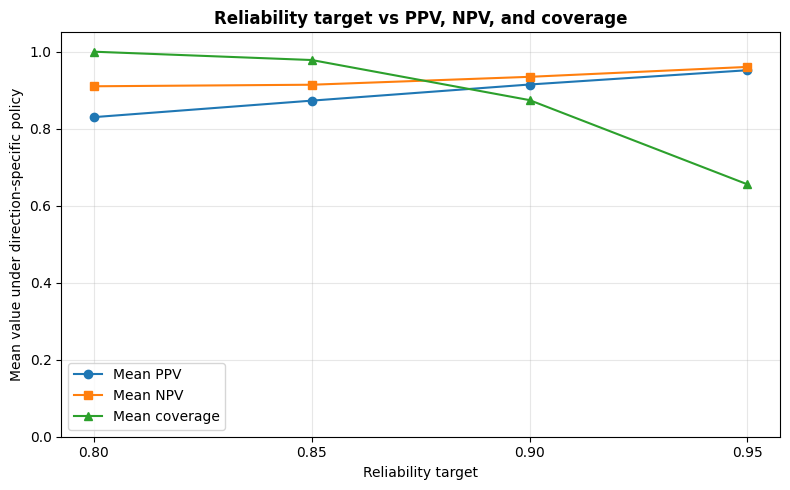

In [21]:
# ===================== part 9A====================================
# Reliability target vs direction-specific reliability and coverage
#
# - PPV summarizes allowed positive-feedback directions.
# - NPV summarizes allowed negative-feedback directions.
# - Coverage shows how often the frozen direction-specific policy gives feedback.
# - A task is feasible if at least one direction is allowed.
# ================================================================
import matplotlib.pyplot as plt

target_metric_rows = []

for target in sorted(
    operating_points_df["reliability_target"].unique()
):

    target_df = operating_points_df[
        operating_points_df["reliability_target"] == target
    ].copy()

    feasible_df = target_df[
        target_df["selection_feasible"]
    ].copy()

    target_metric_rows.append({

        "reliability_target":
            target,

        "n_tasks_feasible":
            int(feasible_df["task"].nunique()),

        "mean_PPV":
            feasible_df["PPV"].mean(),

        "median_PPV":
            feasible_df["PPV"].median(),

        "mean_NPV":
            feasible_df["NPV"].mean(),

        "median_NPV":
            feasible_df["NPV"].median(),

        "mean_coverage":
            feasible_df["coverage"].mean(),

        "median_coverage":
            feasible_df["coverage"].median(),
    })


target_metric_df = (
    pd.DataFrame(target_metric_rows)
    .sort_values("reliability_target")
    .reset_index(drop=True)
)

print(
    "Reliability target vs PPV, NPV, and coverage "
    "(threshold-selection folds 1–3 only):"
)

display(
    target_metric_df.round(4)
)


fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.plot(
    target_metric_df["reliability_target"],
    target_metric_df["mean_PPV"],
    marker="o",
    label="Mean PPV",
)

ax.plot(
    target_metric_df["reliability_target"],
    target_metric_df["mean_NPV"],
    marker="s",
    label="Mean NPV",
)

ax.plot(
    target_metric_df["reliability_target"],
    target_metric_df["mean_coverage"],
    marker="^",
    label="Mean coverage",
)


ax.set_title(
    "Reliability target vs PPV, NPV, and coverage",
    fontweight="bold",
)

ax.set_xlabel(
    "Reliability target"
)

ax.set_ylabel(
    "Mean value under direction-specific policy"
)

ax.set_xticks(
    target_metric_df["reliability_target"]
)

ax.set_ylim(
    0,
    1.05,
)

ax.grid(
    True,
    alpha=0.3,
)

ax.legend()

plt.tight_layout()
plt.show()

In [22]:
# ===================== part 10 ====================================
# SECTION 4 — STEP 4C
# Freeze the final reliability target and full operating policy
# ================================================================

FINAL_RELIABILITY_TARGET = 0.90

selected_operating_points_df = (
    operating_points_df[
        operating_points_df["reliability_target"] == FINAL_RELIABILITY_TARGET
    ]
    .copy()
    .sort_values("task")
    .reset_index(drop=True)
)

required_cols = {"allow_positive", "allow_negative"}
assert required_cols.issubset(selected_operating_points_df.columns)

print(
    "Frozen selective-feedback policy "
    f"for reliability target = {FINAL_RELIABILITY_TARGET:.2f}"
)

display(
    selected_operating_points_df[
        [
            "task",
            "probability_method",
            "selection_feasible",
            "allow_positive",
            "allow_negative",
            "negative_threshold",
            "positive_threshold",
            "n_negative_displayed",
            "n_positive_displayed",
            "negative_coverage",
            "positive_coverage",
            "PPV",
            "NPV",
            "coverage",
            "abstention_rate",
            "selective_accuracy",
        ]
    ].round(4)
)

Frozen selective-feedback policy for reliability target = 0.90


,task,probability_method,selection_feasible,allow_positive,allow_negative,negative_threshold,positive_threshold,n_negative_displayed,n_positive_displayed,negative_coverage,positive_coverage,PPV,NPV,coverage,abstention_rate,selective_accuracy
0,Accessory,raw,True,False,True,0.16,0.17,5948,0,1.0000,0.0000,NaN,0.9331,1.0000,0.0000,0.9331
1,Action,platt,True,False,True,0.02,0.03,5948,0,1.0000,0.0000,NaN,0.9896,1.0000,0.0000,0.9896
2,Blur,raw,True,False,True,0.13,0.14,5948,0,1.0000,0.0000,NaN,0.9287,1.0000,0.0000,0.9287
3,Collage,platt,True,False,True,0.86,0.87,5948,0,1.0000,0.0000,NaN,0.9474,1.0000,0.0000,0.9474
4,Eyes,platt,True,True,True,0.18,0.87,84,2263,0.0141,0.3805,0.9010,0.9286,0.3946,0.6054,0.9020
5,Face,platt,True,True,False,0.01,0.02,0,5944,0.0000,0.9993,0.9056,NaN,0.9993,0.0007,0.9056
6,Group,platt,True,False,True,0.41,0.42,5559,0,0.9346,0.0000,NaN,0.9007,0.9346,0.0654,0.9007
7,Human,isotonic,True,True,True,0.21,0.95,3741,60,0.6290,0.0101,0.9500,0.9147,0.6390,0.3610,0.9153
8,Info,isotonic,True,False,True,0.97,0.98,5897,0,0.9914,0.0000,NaN,0.9432,0.9914,0.0086,0.9432
9,Near,platt,True,True,True,0.13,0.54,80,5468,0.0134,0.9193,0.9014,0.9000,0.9328,0.0672,0.9014


Selection folds 1–3: labels and feedback correctness: 5,948 images.
Majority labels are fixed from folds 1–3. Selected probability methods and feedback rules are unchanged.


Head,Method,"Thresholds (neg, pos)",Allowed direction,True (+ / -),Majority (selection),Baseline accuracy (all),Displayed (+ / -),Withheld,PPV,NPV,Coverage,Abstention
Eyes,platt,"(0.18, 0.87)",Both,4594 / 1354,+,0.7724,2263 / 84,3601,0.9010,0.9286,0.3946,0.6054
Face,platt,"(0.01, 0.02)",Positive,5383 / 565,+,0.9050,5944 / 0,4,0.9056,—,0.9993,0.0007
Occlusion,isotonic,"(0.22, 0.23)",Negative,1026 / 4922,-,0.8275,0 / 3547,2401,—,0.9205,0.5963,0.4037
Blur,raw,"(0.13, 0.14)",Negative,424 / 5524,-,0.9287,0 / 5948,0,—,0.9287,1.0000,0.0000
Subject Focus,raw,"(0.06, 0.07)",Negative,162 / 5786,-,0.9728,0 / 5948,0,—,0.9728,1.0000,0.0000
Action,platt,"(0.02, 0.03)",Negative,62 / 5886,-,0.9896,0 / 5948,0,—,0.9896,1.0000,0.0000
Accessory,raw,"(0.16, 0.17)",Negative,398 / 5550,-,0.9331,0 / 5948,0,—,0.9331,1.0000,0.0000
Near,platt,"(0.13, 0.54)",Both,5090 / 858,+,0.8557,5468 / 80,400,0.9014,0.9000,0.9328,0.0672
Group,platt,"(0.41, 0.42)",Negative,785 / 5163,-,0.8680,0 / 5559,389,—,0.9007,0.9346,0.0654
Collage,platt,"(0.86, 0.87)",Negative,313 / 5635,-,0.9474,0 / 5948,0,—,0.9474,1.0000,0.0000


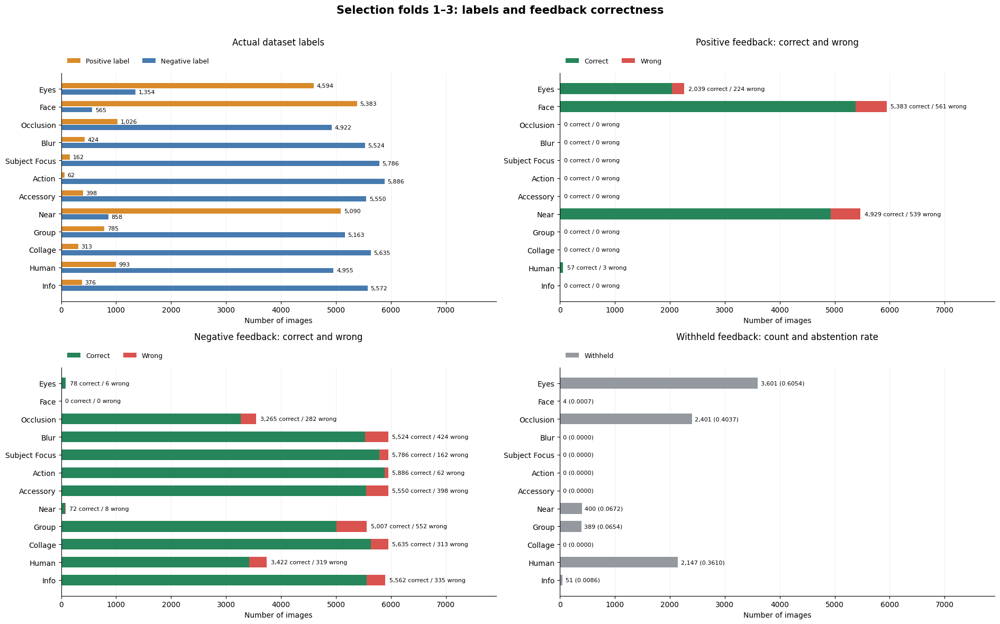


Green: displayed feedback matches the dataset label.
Red: displayed feedback disagrees with the dataset label.
Grey: no feedback was displayed; it is not counted as correct or wrong.
Positive correct + positive wrong + negative correct + negative wrong + withheld = total images for each head.
PPV = positive correct / all positive feedback.
NPV = negative correct / all negative feedback.
— means no feedback was displayed in that direction.
No files saved and no policy changes made.


In [55]:
# ======================== Part 10A ================================
# Class imbalance, feedback correctness, and abstention.
# Selection folds 1–3; shared analysis function for Part 10B.
# No files saved and no changes to calibration or the frozen policy.
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def analyse_feedback_distribution(
    data,
    selection_data,
    policy_data,
    tasks,
    expected_folds,
    title,
):
    """Evaluate the frozen policy and display label/decision counts."""

    # -------------------------------------------------------------
    # 1. Validate inputs
    # -------------------------------------------------------------

    for name, frame, folds in [
        ("Selection", selection_data, {1, 2, 3}),
        ("Analysis", data, set(expected_folds)),
    ]:
        if frame.empty:
            raise ValueError(f"{name} data is empty.")

        if (
            frame["fold"].isna().any()
            or set(frame["fold"].unique()) != folds
        ):
            raise ValueError(
                f"{name} data must contain folds {sorted(folds)}."
            )

        if frame["Id"].isna().any() or frame["Id"].duplicated().any():
            raise ValueError(f"Missing or duplicate IDs: {name}.")

    if set(expected_folds).isdisjoint({1, 2, 3}):
        if set(data["Id"]) & set(selection_data["Id"]):
            raise ValueError("Selection and evaluation IDs overlap.")

    if policy_data["task"].duplicated().any():
        raise ValueError("Duplicate heads in the frozen policy.")

    policy_lookup = policy_data.set_index("task")

    def read_labels(frame, task):
        values = frame[f"{task}_true"].to_numpy(dtype=float)

        if (
            not np.isfinite(values).all()
            or not np.isin(values, [0, 1]).all()
        ):
            raise ValueError(f"Invalid labels: {task}")

        return values.astype(int)

    def read_flag(value):
        if isinstance(value, (bool, np.bool_)):
            return bool(value)

        if isinstance(value, (int, np.integer)) and value in (0, 1):
            return bool(value)

        if isinstance(value, str):
            normalized = value.strip().lower()
            if normalized in ("true", "false"):
                return normalized == "true"

        raise ValueError(f"Invalid policy flag: {value!r}")

    # -------------------------------------------------------------
    # 2. Calculate labels, decisions, and correctness
    # -------------------------------------------------------------

    rows = []
    count_rows = []
    n_total = len(data)

    for task in tasks:
        if task not in policy_lookup.index:
            raise ValueError(f"Missing policy: {task}")

        labels = read_labels(data, task)
        selection_labels = read_labels(selection_data, task)

        probabilities = data[
            f"{task}_prob_selected"
        ].to_numpy(dtype=float)

        if (
            not np.isfinite(probabilities).all()
            or ((probabilities < 0) | (probabilities > 1)).any()
        ):
            raise ValueError(f"Invalid probabilities: {task}")

        # Baseline direction is determined using selection data only.
        # A tie is assigned to negative.
        majority_label = int(
            (selection_labels == 1).sum()
            > (selection_labels == 0).sum()
        )

        policy_row = policy_lookup.loc[task]
        feasible = read_flag(policy_row["selection_feasible"])

        allow_positive = (
            feasible and read_flag(policy_row["allow_positive"])
        )
        allow_negative = (
            feasible and read_flag(policy_row["allow_negative"])
        )

        positive_mask = np.zeros(n_total, dtype=bool)
        negative_mask = np.zeros(n_total, dtype=bool)
        threshold_text = "Not feasible"

        if feasible:
            negative_threshold = float(
                policy_row["negative_threshold"]
            )
            positive_threshold = float(
                policy_row["positive_threshold"]
            )

            if not (
                0 <= negative_threshold < positive_threshold <= 1
            ):
                raise ValueError(f"Invalid thresholds: {task}")

            threshold_text = (
                f"({negative_threshold:.2f}, "
                f"{positive_threshold:.2f})"
            )

            if allow_positive:
                positive_mask = probabilities >= positive_threshold

            if allow_negative:
                negative_mask = probabilities <= negative_threshold

        displayed_mask = positive_mask | negative_mask
        withheld_mask = ~displayed_mask

        # Correctness is measured against the dataset labels.
        positive_correct = int(
            (positive_mask & (labels == 1)).sum()
        )
        positive_wrong = int(
            (positive_mask & (labels == 0)).sum()
        )
        negative_correct = int(
            (negative_mask & (labels == 0)).sum()
        )
        negative_wrong = int(
            (negative_mask & (labels == 1)).sum()
        )

        positive_displayed = positive_correct + positive_wrong
        negative_displayed = negative_correct + negative_wrong
        withheld = int(withheld_mask.sum())

        assert (
            positive_displayed + negative_displayed + withheld
            == n_total
        )

        ppv = (
            positive_correct / positive_displayed
            if positive_displayed else np.nan
        )
        npv = (
            negative_correct / negative_displayed
            if negative_displayed else np.nan
        )

        if allow_positive and allow_negative:
            directions = "Both"
        elif allow_positive:
            directions = "Positive"
        elif allow_negative:
            directions = "Negative"
        else:
            directions = "None"

        true_positive = int((labels == 1).sum())
        true_negative = int((labels == 0).sum())

        rows.append({
            "Head": task,
            "Method": policy_row["probability_method"],
            "Thresholds (neg, pos)": threshold_text,
            "Allowed direction": directions,
            "True (+ / -)": f"{true_positive} / {true_negative}",
            "Majority (selection)": (
                "+" if majority_label == 1 else "-"
            ),
            "Baseline accuracy (all)": float(
                (labels == majority_label).mean()
            ),
            "Displayed (+ / -)": (
                f"{positive_displayed} / {negative_displayed}"
            ),
            "Withheld": withheld,
            "PPV": ppv,
            "NPV": npv,
            "Coverage": float(displayed_mask.mean()),
            "Abstention": float(withheld_mask.mean()),
        })

        count_rows.append({
            "Head": task,
            "True positive": true_positive,
            "True negative": true_negative,
            "Positive feedback": positive_displayed,
            "Negative feedback": negative_displayed,
            "Positive correct": positive_correct,
            "Positive wrong": positive_wrong,
            "Negative correct": negative_correct,
            "Negative wrong": negative_wrong,
            "Withheld": withheld,
            "Withheld true positive": int(
                (withheld_mask & (labels == 1)).sum()
            ),
            "Withheld true negative": int(
                (withheld_mask & (labels == 0)).sum()
            ),
        })

    summary = pd.DataFrame(rows)
    counts = pd.DataFrame(count_rows)

    # -------------------------------------------------------------
    # 3. Display the summary table
    # -------------------------------------------------------------

    print(f"{title}: {n_total:,} images.")
    print(
        "Majority labels are fixed from folds 1–3. "
        "Selected probability methods and feedback rules are unchanged."
    )

    display(
        summary.style.format(
            {
                "Baseline accuracy (all)": "{:.4f}",
                "PPV": "{:.4f}",
                "NPV": "{:.4f}",
                "Coverage": "{:.4f}",
                "Abstention": "{:.4f}",
            },
            na_rep="—",
        ).hide(axis="index")
    )

    # -------------------------------------------------------------
    # 4. Graph label counts and feedback correctness
    # -------------------------------------------------------------

    positions = np.arange(len(counts))
    panel_height = max(6, len(counts) * 0.48)

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(19, panel_height * 2),
    )

    correct_color = "#26855A"
    wrong_color = "#D9534F"
    positive_color = "#D98B2B"
    negative_color = "#477BB0"
    withheld_color = "#93999F"

    def configure_axis(ax, panel_title):
        ax.set_yticks(positions)
        ax.set_yticklabels(counts["Head"])
        ax.invert_yaxis()
        ax.set_xlim(0, n_total * 1.33)
        ax.set_xlabel("Number of images")
        ax.set_title(panel_title, pad=38)
        ax.grid(axis="x", alpha=0.18)
        ax.set_axisbelow(True)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.legend(
            loc="lower left",
            bbox_to_anchor=(0, 1.01),
            frameon=False,
            ncol=2,
            fontsize=9,
        )

    # Actual positive and negative labels.
    ax = axes[0, 0]

    for offset, column, label, color in [
        (-0.17, "True positive", "Positive label", positive_color),
        (0.17, "True negative", "Negative label", negative_color),
    ]:
        bars = ax.barh(
            positions + offset,
            counts[column],
            height=0.29,
            color=color,
            label=label,
        )
        ax.bar_label(
            bars,
            labels=[f"{value:,}" for value in counts[column]],
            padding=4,
            fontsize=8,
        )

    configure_axis(ax, "Actual dataset labels")

    # Positive and negative feedback correctness.
    for ax, direction in [
        (axes[0, 1], "Positive"),
        (axes[1, 0], "Negative"),
    ]:
        correct = counts[f"{direction} correct"].to_numpy()
        wrong = counts[f"{direction} wrong"].to_numpy()

        ax.barh(
            positions,
            correct,
            height=0.60,
            color=correct_color,
            label="Correct",
        )
        ax.barh(
            positions,
            wrong,
            left=correct,
            height=0.60,
            color=wrong_color,
            label="Wrong",
        )

        # Exact counts remain readable even for small red segments.
        for position, correct_count, wrong_count in zip(
            positions, correct, wrong
        ):
            ax.text(
                correct_count + wrong_count + n_total * 0.012,
                position,
                f"{correct_count:,} correct / {wrong_count:,} wrong",
                va="center",
                fontsize=8,
            )

        configure_axis(
            ax,
            f"{direction} feedback: correct and wrong",
        )

    # Abstention has no displayed prediction to mark correct or wrong.
    ax = axes[1, 1]
    withheld_values = counts["Withheld"].to_numpy()

    bars = ax.barh(
        positions,
        withheld_values,
        height=0.60,
        color=withheld_color,
        label="Withheld",
    )

    ax.bar_label(
        bars,
        labels=[
            f"{value:,} ({value / n_total:.4f})"
            for value in withheld_values
        ],
        padding=4,
        fontsize=8,
    )

    configure_axis(ax, "Withheld feedback: count and abstention rate")

    fig.suptitle(
        title,
        fontsize=15,
        fontweight="bold",
    )
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()
    plt.close(fig)

    print(
        "\nGreen: displayed feedback matches the dataset label."
        "\nRed: displayed feedback disagrees with the dataset label."
        "\nGrey: no feedback was displayed; it is not counted as correct or wrong."
        "\nPositive correct + positive wrong + negative correct "
        "+ negative wrong + withheld = total images for each head."
        "\nPPV = positive correct / all positive feedback."
        "\nNPV = negative correct / all negative feedback."
        "\n— means no feedback was displayed in that direction."
        "\nNo files saved and no policy changes made."
    )

    return summary, counts


# -------------------------------------------------------------
# 5. Run selection-data analysis
# -------------------------------------------------------------

required_10a = [
    "threshold_selection_df",
    "selected_operating_points_df",
    "CALIBRATION_TASKS",
]

missing_10a = [
    name for name in required_10a if name not in globals()
]

if missing_10a:
    raise RuntimeError(
        "Run the preceding Parts first. Missing variables:\n"
        + "\n".join(missing_10a)
    )

class_imbalance_audit_df, selection_feedback_counts_df = (
    analyse_feedback_distribution(
        data=threshold_selection_df,
        selection_data=threshold_selection_df,
        policy_data=selected_operating_points_df,
        tasks=CALIBRATION_TASKS,
        expected_folds={1, 2, 3},
        title="Selection folds 1–3: labels and feedback correctness",
    )
)

Held-out folds 4–5: labels and feedback decisions: 3,964 images.
Majority labels are fixed from folds 1–3. Selected probability methods and feedback rules are unchanged.


Head,Method,"Thresholds (neg, pos)",Allowed direction,True (+ / -),Majority (selection),Baseline accuracy (all),Displayed (+ / -),Withheld,PPV,NPV,Coverage,Abstention
Eyes,platt,"(0.18, 0.87)",Both,3064 / 900,+,0.7730,787 / 62,3115,0.9377,0.8710,0.2142,0.7858
Face,platt,"(0.01, 0.02)",Positive,3577 / 387,+,0.9024,3964 / 0,0,0.9024,—,1.0000,0.0000
Occlusion,isotonic,"(0.22, 0.23)",Negative,679 / 3285,-,0.8287,0 / 1560,2404,—,0.9564,0.3935,0.6065
Blur,raw,"(0.13, 0.14)",Negative,274 / 3690,-,0.9309,0 / 3964,0,—,0.9309,1.0000,0.0000
Subject Focus,raw,"(0.06, 0.07)",Negative,112 / 3852,-,0.9717,0 / 3947,17,—,0.9721,0.9957,0.0043
Action,platt,"(0.02, 0.03)",Negative,37 / 3927,-,0.9907,0 / 3964,0,—,0.9907,1.0000,0.0000
Accessory,raw,"(0.16, 0.17)",Negative,274 / 3690,-,0.9309,0 / 3964,0,—,0.9309,1.0000,0.0000
Near,platt,"(0.13, 0.54)",Both,3450 / 514,+,0.8703,3281 / 132,551,0.9393,0.8409,0.8610,0.1390
Group,platt,"(0.41, 0.42)",Negative,497 / 3467,-,0.8746,0 / 3520,444,—,0.9159,0.8880,0.1120
Collage,platt,"(0.86, 0.87)",Negative,179 / 3785,-,0.9548,0 / 3955,9,—,0.9570,0.9977,0.0023


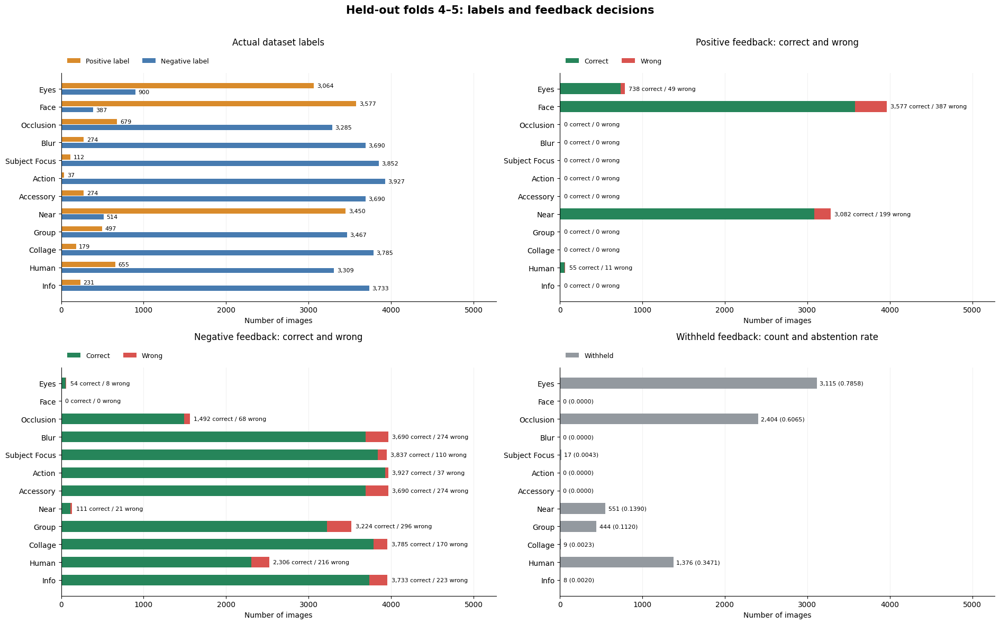


Green: displayed feedback matches the dataset label.
Red: displayed feedback disagrees with the dataset label.
Grey: no feedback was displayed; it is not counted as correct or wrong.
Positive correct + positive wrong + negative correct + negative wrong + withheld = total images for each head.
PPV = positive correct / all positive feedback.
NPV = negative correct / all negative feedback.
— means no feedback was displayed in that direction.
No files saved and no policy changes made.


In [56]:
# ======================== Part 10B ================================
# Class imbalance and majority baseline: evaluation folds 4–5.
# Calibration, thresholds, and allowed directions remain frozen.
# ================================================================

required_10b = [
    "analyse_feedback_distribution",
    "threshold_selection_df",
    "threshold_evaluation_df",
    "selected_operating_points_df",
    "CALIBRATION_TASKS",
]

missing_10b = [
    name for name in required_10b if name not in globals()
]

if missing_10b:
    raise RuntimeError(
        "Run Part 10A and the preceding Parts first. "
        "Missing variables:\n"
        + "\n".join(missing_10b)
    )

class_imbalance_evaluation_df, evaluation_feedback_counts_df = (
    analyse_feedback_distribution(
        data=threshold_evaluation_df,
        selection_data=threshold_selection_df,
        policy_data=selected_operating_points_df,
        tasks=CALIBRATION_TASKS,
        expected_folds={4, 5},
        title="Held-out folds 4–5: labels and feedback decisions",
    )
)

In [25]:
# ===================== part 11 ====================================
# SECTION 4 — STEP 4D
# Held-out evaluation of the frozen selective-feedback policy
# ================================================================

evaluation_rows = []

for row in selected_operating_points_df.itertuples(index=False):

    task = row.task
    method = row.probability_method
    feasible = bool(row.selection_feasible)
    allow_positive = bool(row.allow_positive)
    allow_negative = bool(row.allow_negative)

    if not feasible:
        evaluation_rows.append({
            "task": task,
            "probability_method": method,
            "selection_feasible": False,
            "allow_positive": False,
            "allow_negative": False,
            "negative_threshold": np.nan,
            "positive_threshold": np.nan,
            "n_total": len(threshold_evaluation_df),
            "n_negative_displayed": 0,
            "n_positive_displayed": 0,
            "n_displayed": 0,
            "n_abstained": len(threshold_evaluation_df),
            "negative_coverage": 0.0,
            "positive_coverage": 0.0,
            "coverage": 0.0,
            "abstention_rate": 1.0,
            "PPV": np.nan,
            "NPV": np.nan,
            "selective_accuracy": np.nan,
            "TP": 0,
            "FP": 0,
            "TN": 0,
            "FN": 0,
        })
        continue

    t_neg = float(row.negative_threshold)
    t_pos = float(row.positive_threshold)

    y_true = threshold_evaluation_df[f"{task}_true"].to_numpy(dtype=int)
    y_prob = threshold_evaluation_df[f"{task}_prob_selected"].to_numpy(dtype=float)

    raw_negative_mask = y_prob <= t_neg
    raw_positive_mask = y_prob >= t_pos

    negative_mask = raw_negative_mask if allow_negative else np.zeros_like(raw_negative_mask, dtype=bool)
    positive_mask = raw_positive_mask if allow_positive else np.zeros_like(raw_positive_mask, dtype=bool)

    displayed_mask = negative_mask | positive_mask
    abstain_mask = ~displayed_mask

    TN = int((negative_mask & (y_true == 0)).sum())
    FN = int((negative_mask & (y_true == 1)).sum())
    TP = int((positive_mask & (y_true == 1)).sum())
    FP = int((positive_mask & (y_true == 0)).sum())

    n_total = len(y_true)
    n_negative_displayed = int(negative_mask.sum())
    n_positive_displayed = int(positive_mask.sum())
    n_displayed = int(displayed_mask.sum())
    n_abstained = int(abstain_mask.sum())

    PPV = TP / (TP + FP) if (TP + FP) > 0 else np.nan
    NPV = TN / (TN + FN) if (TN + FN) > 0 else np.nan
    selective_accuracy = (TP + TN) / n_displayed if n_displayed > 0 else np.nan

    evaluation_rows.append({
        "task": task,
        "probability_method": method,
        "selection_feasible": True,
        "allow_positive": allow_positive,
        "allow_negative": allow_negative,
        "negative_threshold": t_neg,
        "positive_threshold": t_pos,
        "n_total": n_total,
        "n_negative_displayed": n_negative_displayed,
        "n_positive_displayed": n_positive_displayed,
        "n_displayed": n_displayed,
        "n_abstained": n_abstained,
        "negative_coverage": n_negative_displayed / n_total,
        "positive_coverage": n_positive_displayed / n_total,
        "coverage": n_displayed / n_total,
        "abstention_rate": n_abstained / n_total,
        "PPV": PPV,
        "NPV": NPV,
        "selective_accuracy": selective_accuracy,
        "TP": TP,
        "FP": FP,
        "TN": TN,
        "FN": FN,
    })

evaluation_df = (
    pd.DataFrame(evaluation_rows)
    .sort_values("task")
    .reset_index(drop=True)
)

print("Held-out evaluation of frozen policy on folds 4–5:")

display(
    evaluation_df[
        [
            "task",
            "probability_method",
            "selection_feasible",
            "allow_positive",
            "allow_negative",
            "negative_threshold",
            "positive_threshold",
            "n_positive_displayed",
            "PPV",
            "n_negative_displayed",
            "NPV",
            "positive_coverage",
            "negative_coverage",
            "coverage",
            "abstention_rate",
            "selective_accuracy",
            "TP",
            "FP",
            "TN",
            "FN",
        ]
    ].round(4)
)

Held-out evaluation of frozen policy on folds 4–5:


,task,probability_method,selection_feasible,allow_positive,allow_negative,negative_threshold,positive_threshold,n_positive_displayed,PPV,n_negative_displayed,NPV,positive_coverage,negative_coverage,coverage,abstention_rate,selective_accuracy,TP,FP,TN,FN
0,Accessory,raw,True,False,True,0.16,0.17,0,NaN,3964,0.9309,0.0000,1.0000,1.0000,0.0000,0.9309,0,0,3690,274
1,Action,platt,True,False,True,0.02,0.03,0,NaN,3964,0.9907,0.0000,1.0000,1.0000,0.0000,0.9907,0,0,3927,37
2,Blur,raw,True,False,True,0.13,0.14,0,NaN,3964,0.9309,0.0000,1.0000,1.0000,0.0000,0.9309,0,0,3690,274
3,Collage,platt,True,False,True,0.86,0.87,0,NaN,3955,0.9570,0.0000,0.9977,0.9977,0.0023,0.9570,0,0,3785,170
4,Eyes,platt,True,True,True,0.18,0.87,787,0.9377,62,0.8710,0.1985,0.0156,0.2142,0.7858,0.9329,738,49,54,8
5,Face,platt,True,True,False,0.01,0.02,3964,0.9024,0,NaN,1.0000,0.0000,1.0000,0.0000,0.9024,3577,387,0,0
6,Group,platt,True,False,True,0.41,0.42,0,NaN,3520,0.9159,0.0000,0.8880,0.8880,0.1120,0.9159,0,0,3224,296
7,Human,isotonic,True,True,True,0.21,0.95,66,0.8333,2522,0.9144,0.0166,0.6362,0.6529,0.3471,0.9123,55,11,2306,216
8,Info,isotonic,True,False,True,0.97,0.98,0,NaN,3956,0.9436,0.0000,0.9980,0.9980,0.0020,0.9436,0,0,3733,223
9,Near,platt,True,True,True,0.13,0.54,3281,0.9393,132,0.8409,0.8277,0.0333,0.8610,0.1390,0.9355,3082,199,111,21


In [26]:
# =====================  13 ====================================
# SECTION 4 — STEP 4F
# Compare threshold-selection performance with held-out performance
#
# 
# - Show whether the frozen operating point generalizes.
# - Compare PPV, NPV, coverage, and directional support.
#
# No threshold modification occurs here.
# ================================================================

selection_eval_rows = []


for task in CALIBRATION_TASKS:

    # ------------------------------------------------------------
    # Selection-set result: folds 1, 2, 3
    # ------------------------------------------------------------

    sel = selected_operating_points_df[
        selected_operating_points_df["task"] == task
    ].iloc[0]


    # ------------------------------------------------------------
    # Held-out result: folds 4, 5
    # ------------------------------------------------------------

    ev = evaluation_df[
        evaluation_df["task"] == task
    ].iloc[0]


    selection_eval_rows.append({

        "task":
            task,

        "probability_method":
            sel["probability_method"],

        "selection_feasible":
            bool(sel["selection_feasible"]),

        "negative_threshold":
            sel["negative_threshold"],

        "positive_threshold":
            sel["positive_threshold"],


        # ---------------- Selection ----------------

        "selection_PPV":
            sel["PPV"],

        "evaluation_PPV":
            ev["PPV"],

        "PPV_change":
            (
                ev["PPV"] - sel["PPV"]
                if (
                    not pd.isna(ev["PPV"])
                    and not pd.isna(sel["PPV"])
                )
                else np.nan
            ),


        "selection_NPV":
            sel["NPV"],

        "evaluation_NPV":
            ev["NPV"],

        "NPV_change":
            (
                ev["NPV"] - sel["NPV"]
                if (
                    not pd.isna(ev["NPV"])
                    and not pd.isna(sel["NPV"])
                )
                else np.nan
            ),


        # ---------------- Coverage ----------------

        "selection_coverage":
            sel["coverage"],

        "evaluation_coverage":
            ev["coverage"],

        "coverage_change":
            (
                ev["coverage"]
                - sel["coverage"]
            ),


        # ---------------- Directional support ----------------

        "selection_n_positive":
            int(sel["n_positive_displayed"]),

        "evaluation_n_positive":
            int(ev["n_positive_displayed"]),

        "selection_n_negative":
            int(sel["n_negative_displayed"]),

        "evaluation_n_negative":
            int(ev["n_negative_displayed"]),
    })


selection_vs_evaluation_df = (
    pd.DataFrame(selection_eval_rows)
    .sort_values("task")
    .reset_index(drop=True)
)


print(
    "Selection-set vs held-out generalization:"
)


display(
    selection_vs_evaluation_df[
        [
            "task",

            "negative_threshold",
            "positive_threshold",

            "selection_PPV",
            "evaluation_PPV",
            "PPV_change",

            "selection_NPV",
            "evaluation_NPV",
            "NPV_change",

            "selection_coverage",
            "evaluation_coverage",
            "coverage_change",

            "selection_n_positive",
            "evaluation_n_positive",

            "selection_n_negative",
            "evaluation_n_negative",
        ]
    ].round(4)
)

Selection-set vs held-out generalization:


,task,negative_threshold,positive_threshold,selection_PPV,evaluation_PPV,PPV_change,selection_NPV,evaluation_NPV,NPV_change,selection_coverage,evaluation_coverage,coverage_change,selection_n_positive,evaluation_n_positive,selection_n_negative,evaluation_n_negative
0,Accessory,0.16,0.17,NaN,NaN,NaN,0.9331,0.9309,-0.0022,1.0000,1.0000,0.0000,0,0,5948,3964
1,Action,0.02,0.03,NaN,NaN,NaN,0.9896,0.9907,0.0011,1.0000,1.0000,0.0000,0,0,5948,3964
2,Blur,0.13,0.14,NaN,NaN,NaN,0.9287,0.9309,0.0022,1.0000,1.0000,0.0000,0,0,5948,3964
3,Collage,0.86,0.87,NaN,NaN,NaN,0.9474,0.9570,0.0096,1.0000,0.9977,-0.0023,0,0,5948,3955
4,Eyes,0.18,0.87,0.9010,0.9377,0.0367,0.9286,0.8710,-0.0576,0.3946,0.2142,-0.1804,2263,787,84,62
5,Face,0.01,0.02,0.9056,0.9024,-0.0032,NaN,NaN,NaN,0.9993,1.0000,0.0007,5944,3964,0,0
6,Group,0.41,0.42,NaN,NaN,NaN,0.9007,0.9159,0.0152,0.9346,0.8880,-0.0466,0,0,5559,3520
7,Human,0.21,0.95,0.9500,0.8333,-0.1167,0.9147,0.9144,-0.0004,0.6390,0.6529,0.0138,60,66,3741,2522
8,Info,0.97,0.98,NaN,NaN,NaN,0.9432,0.9436,0.0004,0.9914,0.9980,0.0066,0,0,5897,3956
9,Near,0.13,0.54,0.9014,0.9393,0.0379,0.9000,0.8409,-0.0591,0.9328,0.8610,-0.0718,5468,3281,80,132


In [27]:
# ===================== part 16 ====================================
# SECTION 4 — STEP 4G
# Final held-out reporting table
#
# Reporting only. Does not change thresholds or allowed directions.
# ================================================================

final_results_df = evaluation_df[
    [
        "task",
        "probability_method",
        "selection_feasible",
        "allow_positive",
        "allow_negative",
        "negative_threshold",
        "positive_threshold",
        "n_positive_displayed",
        "PPV",
        "n_negative_displayed",
        "NPV",
        "coverage",
        "abstention_rate",
        "selective_accuracy",
    ]
].copy()

print(
    "Final held-out selective-feedback results "
    "(complete policy selected on folds 1–3; evaluated on folds 4–5):"
)

display(final_results_df.round(4))

Final held-out selective-feedback results (complete policy selected on folds 1–3; evaluated on folds 4–5):


,task,probability_method,selection_feasible,allow_positive,allow_negative,negative_threshold,positive_threshold,n_positive_displayed,PPV,n_negative_displayed,NPV,coverage,abstention_rate,selective_accuracy
0,Accessory,raw,True,False,True,0.16,0.17,0,NaN,3964,0.9309,1.0000,0.0000,0.9309
1,Action,platt,True,False,True,0.02,0.03,0,NaN,3964,0.9907,1.0000,0.0000,0.9907
2,Blur,raw,True,False,True,0.13,0.14,0,NaN,3964,0.9309,1.0000,0.0000,0.9309
3,Collage,platt,True,False,True,0.86,0.87,0,NaN,3955,0.9570,0.9977,0.0023,0.9570
4,Eyes,platt,True,True,True,0.18,0.87,787,0.9377,62,0.8710,0.2142,0.7858,0.9329
5,Face,platt,True,True,False,0.01,0.02,3964,0.9024,0,NaN,1.0000,0.0000,0.9024
6,Group,platt,True,False,True,0.41,0.42,0,NaN,3520,0.9159,0.8880,0.1120,0.9159
7,Human,isotonic,True,True,True,0.21,0.95,66,0.8333,2522,0.9144,0.6529,0.3471,0.9123
8,Info,isotonic,True,False,True,0.97,0.98,0,NaN,3956,0.9436,0.9980,0.0020,0.9436
9,Near,platt,True,True,True,0.13,0.54,3281,0.9393,132,0.8409,0.8610,0.1390,0.9355


In [28]:
# ===================== part 17 ====================================
# SECTION 5 — STEP 5A
# Reconstruct split calibration models for prototype testing
#
# 
# - The prototype model outputs RAW sigmoid probabilities.
# - The selective thresholds were defined on SELECTED/CALIBRATED probabilities.
# - Therefore raw model outputs must first be transformed using the
#   selected calibration method.
#
# Split:
# - Calibration methods were selected using folds 1,2,3.
# - Thresholds were selected using folds 1,2,3.
# - Folds 4,5 are final evaluation folds.
#
# Therefore, for prototype evaluation on folds 4,5:
#   fit calibrators on folds 1,2,3 only
#   apply calibrators to folds 4,5
# ================================================================

from src.aux_calibration import (
    fit_platt_calibrator,
    fit_isotonic_calibrator,
    apply_calibrator,
)


def probability_to_logit(prob):
    """
    Inverse-sigmoid transformation used for Platt-style calibration.
    """
    prob = np.asarray(prob, dtype=float)

    prob = np.clip(
        prob,
        1e-7,
        1.0 - 1e-7,
    )

    return np.log(
        prob / (1.0 - prob)
    )


# ------------------------------------------------------------
# Build calibrators for final-evaluation folds.
#
# 
# Both fold 4 and fold 5 use calibrators fitted only on folds 1,2,3.
# Fold 4 must not use fold 5.
# Fold 5 must not use fold 4.
# ------------------------------------------------------------

PROTOTYPE_EVAL_FOLDS = THRESHOLD_EVALUATION_FOLDS.copy()

calibration_fit_df = aux_df[
    aux_df["fold"].isin(THRESHOLD_SELECTION_FOLDS)
].copy()

fold_calibrators = {}

for heldout_fold in PROTOTYPE_EVAL_FOLDS:

    fold_calibrators[heldout_fold] = {}

    for task in CALIBRATION_TASKS:

        method = SELECTED_METHODS[task]

        y_true_fit = calibration_fit_df[
            f"{task}_true"
        ].to_numpy(dtype=int)

        raw_prob_fit = calibration_fit_df[
            f"{task}_prob"
        ].to_numpy(dtype=float)

        if method == "raw":

            calibrator = None

        elif method == "platt":

            logit_fit = probability_to_logit(
                raw_prob_fit
            )

            calibrator = fit_platt_calibrator(
                y_score_fit=logit_fit,
                y_true_fit=y_true_fit,
            )

        elif method == "isotonic":

            calibrator = fit_isotonic_calibrator(
                y_prob_fit=raw_prob_fit,
                y_true_fit=y_true_fit,
            )

        else:

            raise ValueError(
                f"Unknown calibration method for {task}: {method}"
            )

        fold_calibrators[heldout_fold][task] = calibrator


print(
    "Built split-clean calibrators for folds:",
    sorted(fold_calibrators.keys()),
)

print(
    "Calibrator fitting folds:",
    sorted(calibration_fit_df["fold"].unique().tolist()),
)


# ================================================================
# Verification:
# Reconstruct selected probabilities for folds 4,5 from raw OOF
# probabilities and compare with threshold_evaluation_df.
#
# Expected result:
# differences should be exactly 0 or very close to floating precision.
# ================================================================

verification_rows = []

for heldout_fold in PROTOTYPE_EVAL_FOLDS:

    for task in CALIBRATION_TASKS:

        method = SELECTED_METHODS[task]

        check_df = (
            aux_df.loc[
                aux_df["fold"] == heldout_fold,
                [
                    "Id",
                    f"{task}_prob",
                ],
            ]
            .merge(
                threshold_evaluation_df.loc[
                    threshold_evaluation_df["fold"] == heldout_fold,
                    [
                        "Id",
                        f"{task}_prob_selected",
                    ],
                ],
                on="Id",
                how="inner",
            )
        )

        raw_prob = check_df[
            f"{task}_prob"
        ].to_numpy(dtype=float)

        if method == "raw":

            reconstructed_prob = raw_prob

        elif method == "platt":

            raw_logit = probability_to_logit(
                raw_prob
            )

            reconstructed_prob = apply_calibrator(
                y_prob=raw_logit,
                method="platt",
                calibrator=fold_calibrators[
                    heldout_fold
                ][task],
            )

        elif method == "isotonic":

            reconstructed_prob = apply_calibrator(
                y_prob=raw_prob,
                method="isotonic",
                calibrator=fold_calibrators[
                    heldout_fold
                ][task],
            )

        else:

            raise ValueError(
                f"Unknown calibration method for {task}: {method}"
            )

        selected_prob = check_df[
            f"{task}_prob_selected"
        ].to_numpy(dtype=float)

        absolute_difference = np.abs(
            reconstructed_prob
            - selected_prob
        )

        verification_rows.append({

            "fold":
                heldout_fold,

            "task":
                task,

            "method":
                method,

            "n":
                len(check_df),

            "mean_abs_difference":
                float(absolute_difference.mean()),

            "max_abs_difference":
                float(absolute_difference.max()),
        })


calibration_reconstruction_check_df = (
    pd.DataFrame(verification_rows)
    .sort_values(
        ["fold", "task"]
    )
    .reset_index(drop=True)
)


print(
    "\nCalibration reconstruction check:"
)

display(
    calibration_reconstruction_check_df.round(10)
)

print(
    "\nOverall maximum absolute difference:",
    calibration_reconstruction_check_df[
        "max_abs_difference"
    ].max(),
)

assert (
    calibration_reconstruction_check_df[
        "max_abs_difference"
    ].max()
    < 1e-10
)

Built split-clean calibrators for folds: [4, 5]
Calibrator fitting folds: [1, 2, 3]

Calibration reconstruction check:


,fold,task,method,n,mean_abs_difference,max_abs_difference
0,4,Accessory,raw,1982,0.0,0.0
1,4,Action,platt,1982,0.0,0.0
2,4,Blur,raw,1982,0.0,0.0
3,4,Collage,platt,1982,0.0,0.0
4,4,Eyes,platt,1982,0.0,0.0
5,4,Face,platt,1982,0.0,0.0
6,4,Group,platt,1982,0.0,0.0
7,4,Human,isotonic,1982,0.0,0.0
8,4,Info,isotonic,1982,0.0,0.0
9,4,Near,platt,1982,0.0,0.0



Overall maximum absolute difference: 0.0


In [29]:
# ===================== part 18 ====================================
# SECTION 5 — STEP 5B
# Reusable calibration helper for raw auxiliary probabilities
#
# Input:
#   raw_probs = {
#       "Eyes": 0.82,
#       "Face": 0.91,
#       ...
#   }
#
# Output:
#   calibrated_probs = {
#       "Eyes": ...,
#       "Face": ...,
#       ...
#   }
#
# heldout_fold determines which fold-specific calibrator is used.
# ================================================================


def calibrate_aux_probabilities(
    raw_probs,
    heldout_fold,
    selected_methods=SELECTED_METHODS,
    calibrators_by_fold=fold_calibrators,
):
    """
    Convert raw auxiliary sigmoid probabilities into the calibrated
    probability space used by the selective-prediction thresholds.

    Parameters
    ----------
    raw_probs : dict
        {task: raw sigmoid probability}

    heldout_fold : int
        Evaluation fold whose split-clean calibrator should be used.

    Returns
    -------
    dict
        {task: calibrated probability}
    """

    if heldout_fold not in calibrators_by_fold:
        raise ValueError(
            f"No calibrators available for fold {heldout_fold}. "
            f"Available folds: {sorted(calibrators_by_fold.keys())}"
        )


    calibrated_probs = {}


    for task, raw_prob in raw_probs.items():

        if task not in selected_methods:
            raise KeyError(
                f"No selected calibration method for task: {task}"
            )

        method = selected_methods[task]

        raw_prob = float(raw_prob)


        # ----------------------------------------------------
        # RAW
        # ----------------------------------------------------

        if method == "raw":

            calibrated_prob = raw_prob


        # ----------------------------------------------------
        # PLATT
        # ----------------------------------------------------

        elif method == "platt":

            raw_logit = probability_to_logit(
                [raw_prob]
            )

            calibrated_prob = apply_calibrator(
                y_prob=raw_logit,
                method="platt",
                calibrator=calibrators_by_fold[
                    heldout_fold
                ][task],
            )[0]


        # ----------------------------------------------------
        # ISOTONIC
        # ----------------------------------------------------

        elif method == "isotonic":

            calibrated_prob = apply_calibrator(
                y_prob=np.array(
                    [raw_prob],
                    dtype=float,
                ),
                method="isotonic",
                calibrator=calibrators_by_fold[
                    heldout_fold
                ][task],
            )[0]


        else:

            raise ValueError(
                f"Unknown calibration method "
                f"for {task}: {method}"
            )


        calibrated_probs[task] = float(
            calibrated_prob
        )


    return calibrated_probs

# ================================================================
# Sanity check using one real OOF sample from fold 4
# ================================================================

CHECK_FOLD = 4


example_raw_row = (
    aux_df[
        aux_df["fold"] == CHECK_FOLD
    ]
    .iloc[0]
)


example_id = example_raw_row["Id"]


example_raw_probs = {
    task: float(
        example_raw_row[f"{task}_prob"]
    )
    for task in CALIBRATION_TASKS
}


example_calibrated_probs = (
    calibrate_aux_probabilities(
        raw_probs=example_raw_probs,
        heldout_fold=CHECK_FOLD,
    )
)


# Retrieve the already-created cross-fitted values
example_expected_row = (
    aux_selected_df[
        aux_selected_df["Id"] == example_id
    ]
    .iloc[0]
)


comparison_rows = []


for task in CALIBRATION_TASKS:

    expected = float(
        example_expected_row[
            f"{task}_prob_selected"
        ]
    )

    reconstructed = float(
        example_calibrated_probs[task]
    )


    comparison_rows.append({

        "task":
            task,

        "method":
            SELECTED_METHODS[task],

        "raw_probability":
            example_raw_probs[task],

        "calibrated_probability":
            reconstructed,

        "expected_probability":
            expected,

        "absolute_difference":
            abs(
                reconstructed - expected
            ),
    })


prototype_calibration_check_df = (
    pd.DataFrame(comparison_rows)
)


print(
    "Example OOF ID:",
    example_id,
)

print(
    "Held-out fold:",
    CHECK_FOLD,
)


display(
    prototype_calibration_check_df.round(10)
)


print(
    "\nMaximum absolute difference:",
    prototype_calibration_check_df[
        "absolute_difference"
    ].max(),
)

Example OOF ID: 0023b8a3abc93c712edd6120867deb53
Held-out fold: 4


,task,method,raw_probability,calibrated_probability,expected_probability,absolute_difference
0,Eyes,platt,0.788930,0.715252,0.715252,0.0
1,Face,platt,0.919535,0.944282,0.944282,0.0
2,Occlusion,isotonic,0.297645,0.726027,0.726027,0.0
3,Blur,raw,0.048647,0.048647,0.048647,0.0
4,Subject Focus,raw,0.015538,0.015538,0.015538,0.0
5,Action,platt,0.008254,0.010530,0.010530,0.0
6,Accessory,raw,0.065064,0.065064,0.065064,0.0
7,Near,platt,0.892092,0.876848,0.876848,0.0
8,Group,platt,0.077334,0.022323,0.022323,0.0
9,Collage,platt,0.058802,0.102275,0.102275,0.0



Maximum absolute difference: 0.0


In [30]:
# ===================== part 19 ====================================
# SECTION 5 — STEP 5C
# Apply the frozen selective-feedback policy
# ================================================================

def build_selective_policy(operating_points_df):
    policy = {}

    for row in operating_points_df.itertuples(index=False):

        if not bool(row.selection_feasible):
            policy[row.task] = {
                "selection_feasible": False,
                "allow_positive": False,
                "allow_negative": False,
                "negative_threshold": None,
                "positive_threshold": None,
            }
        else:
            policy[row.task] = {
                "selection_feasible": True,
                "allow_positive": bool(row.allow_positive),
                "allow_negative": bool(row.allow_negative),
                "negative_threshold": float(row.negative_threshold),
                "positive_threshold": float(row.positive_threshold),
            }

    return policy


SELECTIVE_POLICY = build_selective_policy(selected_operating_points_df)


def threshold_state(probability, task, policy=SELECTIVE_POLICY):
    if task not in policy:
        raise KeyError(f"No selective policy found for task: {task}")

    task_policy = policy[task]

    if not task_policy["selection_feasible"]:
        return "abstain"

    probability = float(probability)
    t_neg = task_policy["negative_threshold"]
    t_pos = task_policy["positive_threshold"]

    if probability <= t_neg:
        return "negative"

    if probability >= t_pos:
        return "positive"

    return "abstain"


def selective_state(probability, task, policy=SELECTIVE_POLICY):
    state = threshold_state(probability, task, policy)
    task_policy = policy[task]

    if state == "positive" and task_policy["allow_positive"]:
        return "positive"

    if state == "negative" and task_policy["allow_negative"]:
        return "negative"

    return "abstain"


def selective_decisions(selected_probs, policy=SELECTIVE_POLICY):
    decisions = {}

    for task, probability in selected_probs.items():
        decisions[task] = {
            "probability": float(probability),
            "threshold_state": threshold_state(probability, task, policy),
            "state": selective_state(probability, task, policy),
        }

    return decisions


example_selective_decisions = selective_decisions(example_calibrated_probs)

example_decision_rows = []

for task in CALIBRATION_TASKS:
    task_policy = SELECTIVE_POLICY[task]
    result = example_selective_decisions[task]

    example_decision_rows.append({
        "task": task,
        "selected_probability": example_calibrated_probs[task],
        "negative_threshold": task_policy["negative_threshold"],
        "positive_threshold": task_policy["positive_threshold"],
        "allow_positive": task_policy["allow_positive"],
        "allow_negative": task_policy["allow_negative"],
        "threshold_state": result["threshold_state"],
        "display_state": result["state"],
    })

example_decision_df = pd.DataFrame(example_decision_rows)

print("Selective decisions for example ID:", example_id)
display(example_decision_df.round(4))

Selective decisions for example ID: 0023b8a3abc93c712edd6120867deb53


,task,selected_probability,negative_threshold,positive_threshold,allow_positive,allow_negative,threshold_state,display_state
0,Eyes,0.7153,0.18,0.87,True,True,abstain,abstain
1,Face,0.9443,0.01,0.02,True,False,positive,positive
2,Occlusion,0.7260,0.22,0.23,False,True,positive,abstain
3,Blur,0.0486,0.13,0.14,False,True,negative,negative
4,Subject Focus,0.0155,0.06,0.07,False,True,negative,negative
5,Action,0.0105,0.02,0.03,False,True,negative,negative
6,Accessory,0.0651,0.16,0.17,False,True,negative,negative
7,Near,0.8768,0.13,0.54,True,True,positive,positive
8,Group,0.0223,0.41,0.42,False,True,negative,negative
9,Collage,0.1023,0.86,0.87,False,True,negative,negative


In [31]:
# ===================== part 20 ====================================
# SECTION 5 — STEP 5D
# Verify helper against part 11 held-out counts
# ================================================================

decision_verification_rows = []

for task in CALIBRATION_TASKS:

    y_true = threshold_evaluation_df[f"{task}_true"].to_numpy(dtype=int)
    selected_prob = threshold_evaluation_df[f"{task}_prob_selected"].to_numpy(dtype=float)

    states = np.array(
        [selective_state(p, task) for p in selected_prob],
        dtype=object,
    )

    neg = states == "negative"
    pos = states == "positive"
    abst = states == "abstain"

    TN = int((neg & (y_true == 0)).sum())
    FN = int((neg & (y_true == 1)).sum())
    TP = int((pos & (y_true == 1)).sum())
    FP = int((pos & (y_true == 0)).sum())

    expected = evaluation_df[evaluation_df["task"] == task].iloc[0]

    decision_verification_rows.append({
        "task": task,
        "reconstructed_negative": int(neg.sum()),
        "expected_negative": int(expected["n_negative_displayed"]),
        "reconstructed_positive": int(pos.sum()),
        "expected_positive": int(expected["n_positive_displayed"]),
        "reconstructed_abstained": int(abst.sum()),
        "expected_abstained": int(expected["n_abstained"]),
        "reconstructed_TP": TP,
        "expected_TP": int(expected["TP"]),
        "reconstructed_FP": FP,
        "expected_FP": int(expected["FP"]),
        "reconstructed_TN": TN,
        "expected_TN": int(expected["TN"]),
        "reconstructed_FN": FN,
        "expected_FN": int(expected["FN"]),
    })

decision_verification_df = (
    pd.DataFrame(decision_verification_rows)
    .sort_values("task")
    .reset_index(drop=True)
)

check_cols = [
    ("reconstructed_negative", "expected_negative"),
    ("reconstructed_positive", "expected_positive"),
    ("reconstructed_abstained", "expected_abstained"),
    ("reconstructed_TP", "expected_TP"),
    ("reconstructed_FP", "expected_FP"),
    ("reconstructed_TN", "expected_TN"),
    ("reconstructed_FN", "expected_FN"),
]

decision_verification_df["counts_match"] = True

for left, right in check_cols:
    decision_verification_df["counts_match"] &= (
        decision_verification_df[left] == decision_verification_df[right]
    )

display(
    decision_verification_df[
        [
            "task",
            "reconstructed_negative",
            "expected_negative",
            "reconstructed_positive",
            "expected_positive",
            "reconstructed_abstained",
            "expected_abstained",
            "counts_match",
        ]
    ]
)

print(
    "\nAll tasks match part 11:",
    bool(decision_verification_df["counts_match"].all()),
)

,task,reconstructed_negative,expected_negative,reconstructed_positive,expected_positive,reconstructed_abstained,expected_abstained,counts_match
0,Accessory,3964,3964,0,0,0,0,True
1,Action,3964,3964,0,0,0,0,True
2,Blur,3964,3964,0,0,0,0,True
3,Collage,3955,3955,0,0,9,9,True
4,Eyes,62,62,787,787,3115,3115,True
5,Face,0,0,3964,3964,0,0,True
6,Group,3520,3520,0,0,444,444,True
7,Human,2522,2522,66,66,1376,1376,True
8,Info,3956,3956,0,0,8,8,True
9,Near,132,132,3281,3281,551,551,True



All tasks match part 11: True


In [32]:
# ===================== part 21 ====================================
# SECTION 5 — STEP 5E
# Inspect frozen user-facing display policy
#
# No held-out result is used here to change the policy.
# ================================================================

policy_rows = []

for task in CALIBRATION_TASKS:
    policy = SELECTIVE_POLICY[task]

    policy_rows.append({
        "task": task,
        "selection_feasible": policy["selection_feasible"],
        "allow_positive": policy["allow_positive"],
        "allow_negative": policy["allow_negative"],
        "negative_threshold": policy["negative_threshold"],
        "positive_threshold": policy["positive_threshold"],
    })

prototype_policy_df = pd.DataFrame(policy_rows)

display(prototype_policy_df.round(4))

,task,selection_feasible,allow_positive,allow_negative,negative_threshold,positive_threshold
0,Eyes,True,True,True,0.18,0.87
1,Face,True,True,False,0.01,0.02
2,Occlusion,True,False,True,0.22,0.23
3,Blur,True,False,True,0.13,0.14
4,Subject Focus,True,False,True,0.06,0.07
5,Action,True,False,True,0.02,0.03
6,Accessory,True,False,True,0.16,0.17
7,Near,True,True,True,0.13,0.54
8,Group,True,False,True,0.41,0.42
9,Collage,True,False,True,0.86,0.87


In [33]:
# ===================== part 22 ====================================
# SECTION 5 — STEP 5F
# Validate actual single-image model inference against saved OOF output
#
# 
# - Load the SAME fold checkpoint that generated this image's OOF prediction.
# - Run predict_aux() directly on the image.
# - Confirm the raw probabilities match aux_df.
# - Then convert them to the selected probability representation
#   and confirm they match aux_selected_df.
# This verifies the complete prototype inference path:
#
# image
#   -> fold model
#   -> raw sigmoid probabilities
#   -> calibration
#   -> calibrated OOF-equivalent probabilities
# ================================================================

from src.inference_feedback import (
    preprocess,
    predict_aux,
)


# ------------------------------------------------------------
# Use the same example from fold 4
# ------------------------------------------------------------

MODEL_FOLD = CHECK_FOLD   # currently 4

assert MODEL_FOLD == 4


# ------------------------------------------------------------
# Load model_fold4.pt
#
# predict_aux() internally expects the model at dictionary key 0,
# so we intentionally store the fold-4 model under key 0.
# ------------------------------------------------------------

prototype_models = {
    0: load_model(
        fold=MODEL_FOLD,
        cfg=ACTIVE_CFG,
        out_dir=ACTIVE_DIR,
        device=device,
    )
}


# ------------------------------------------------------------
# Load and preprocess the actual image
# ------------------------------------------------------------

example_image_path = os.path.join(
    IMG_FOLDER,
    example_id + ".jpg",
)

example_img_tensor, example_img_pil = preprocess(
    example_image_path,
    ACTIVE_CFG,
)


# ------------------------------------------------------------
# Actual neural-network inference
# ------------------------------------------------------------

model_raw_probs = predict_aux(
    img_tensor=example_img_tensor,
    allFolds_models=prototype_models,
    cfg=ACTIVE_CFG,
    aux_tasks=CALIBRATION_TASKS,
    device=device,
)


# ------------------------------------------------------------
# Apply the fold-4 calibration
# ------------------------------------------------------------

model_calibrated_probs = calibrate_aux_probabilities(
    raw_probs=model_raw_probs,
    heldout_fold=MODEL_FOLD,
)


# ------------------------------------------------------------
# Compare against saved OOF values
# ------------------------------------------------------------

saved_raw_row = (
    aux_df[
        aux_df["Id"] == example_id
    ]
    .iloc[0]
)

saved_selected_row = (
    aux_selected_df[
        aux_selected_df["Id"] == example_id
    ]
    .iloc[0]
)


model_check_rows = []


for task in CALIBRATION_TASKS:

    model_raw = float(
        model_raw_probs[task]
    )

    saved_raw = float(
        saved_raw_row[f"{task}_prob"]
    )

    model_calibrated = float(
        model_calibrated_probs[task]
    )

    saved_calibrated = float(
        saved_selected_row[
            f"{task}_prob_selected"
        ]
    )


    model_check_rows.append({

        "task":
            task,

        "model_raw":
            model_raw,

        "saved_oof_raw":
            saved_raw,

        "raw_abs_difference":
            abs(
                model_raw - saved_raw
            ),

        "model_calibrated":
            model_calibrated,

        "saved_oof_calibrated":
            saved_calibrated,

        "calibrated_abs_difference":
            abs(
                model_calibrated
                - saved_calibrated
            ),
    })


model_inference_check_df = pd.DataFrame(
    model_check_rows
)


print(
    "Model / OOF consistency check for:",
    example_id,
)

print(
    "Checkpoint fold:",
    MODEL_FOLD,
)


display(
    model_inference_check_df.round(10)
)


print(
    "\nMaximum RAW absolute difference:",
    model_inference_check_df[
        "raw_abs_difference"
    ].max(),
)

print(
    "Maximum CALIBRATED absolute difference:",
    model_inference_check_df[
        "calibrated_abs_difference"
    ].max(),
)

Model / OOF consistency check for: 0023b8a3abc93c712edd6120867deb53
Checkpoint fold: 4


,task,model_raw,saved_oof_raw,raw_abs_difference,model_calibrated,saved_oof_calibrated,calibrated_abs_difference
0,Eyes,0.788930,0.788930,0.000000e+00,0.715252,0.715252,0.000000e+00
1,Face,0.919535,0.919535,0.000000e+00,0.944282,0.944282,0.000000e+00
2,Occlusion,0.297645,0.297645,2.980000e-08,0.726027,0.726027,0.000000e+00
3,Blur,0.048647,0.048647,0.000000e+00,0.048647,0.048647,0.000000e+00
4,Subject Focus,0.015538,0.015538,0.000000e+00,0.015538,0.015538,0.000000e+00
5,Action,0.008254,0.008254,0.000000e+00,0.010530,0.010530,0.000000e+00
6,Accessory,0.065064,0.065064,7.500000e-09,0.065064,0.065064,7.500000e-09
7,Near,0.892092,0.892092,0.000000e+00,0.876848,0.876848,0.000000e+00
8,Group,0.077334,0.077334,1.490000e-08,0.022323,0.022323,1.450000e-08
9,Collage,0.058802,0.058802,3.700000e-09,0.102275,0.102275,1.850000e-08



Maximum RAW absolute difference: 2.9802322443206464e-08
Maximum CALIBRATED absolute difference: 1.8512409744042557e-08


In [34]:
# ===================== part 23 ====================================
# SECTION 5 — STEP 5G
# Complete auxiliary inference pipeline
# ================================================================

def predict_aux_selective(
    img_tensor,
    allFolds_models,
    cfg,
    aux_tasks,
    device,
    heldout_fold,
):
    raw_probs = predict_aux(
        img_tensor=img_tensor,
        allFolds_models=allFolds_models,
        cfg=cfg,
        aux_tasks=aux_tasks,
        device=device,
    )

    selected_probs = calibrate_aux_probabilities(
        raw_probs=raw_probs,
        heldout_fold=heldout_fold,
    )

    decisions = selective_decisions(selected_probs)

    results = {}

    for task in aux_tasks:
        results[task] = {
            "raw_probability": float(raw_probs[task]),
            "calibrated_probability": float(selected_probs[task]),
            "threshold_state": decisions[task]["threshold_state"],
            "prototype_state": decisions[task]["state"],
        }

    return results


full_aux_results = predict_aux_selective(
    img_tensor=example_img_tensor,
    allFolds_models=prototype_models,
    cfg=ACTIVE_CFG,
    aux_tasks=CALIBRATION_TASKS,
    device=device,
    heldout_fold=MODEL_FOLD,
)

full_pipeline_rows = []

for task in CALIBRATION_TASKS:
    result = full_aux_results[task]

    full_pipeline_rows.append({
        "task": task,
        "raw_probability": result["raw_probability"],
        "selected_probability": result["calibrated_probability"],
        "threshold_state": result["threshold_state"],
        "display_state": result["prototype_state"],
    })

full_pipeline_df = pd.DataFrame(full_pipeline_rows)

print("Complete auxiliary inference pipeline:")
print("Image:", example_id)
print("OOF/model fold:", MODEL_FOLD)

display(full_pipeline_df.round(4))

Complete auxiliary inference pipeline:
Image: 0023b8a3abc93c712edd6120867deb53
OOF/model fold: 4


,task,raw_probability,selected_probability,threshold_state,display_state
0,Eyes,0.7889,0.7153,abstain,abstain
1,Face,0.9195,0.9443,positive,positive
2,Occlusion,0.2976,0.7260,positive,abstain
3,Blur,0.0486,0.0486,negative,negative
4,Subject Focus,0.0155,0.0155,negative,negative
5,Action,0.0083,0.0105,negative,negative
6,Accessory,0.0651,0.0651,negative,negative
7,Near,0.8921,0.8768,positive,positive
8,Group,0.0773,0.0223,negative,negative
9,Collage,0.0588,0.1023,negative,negative


In [72]:
# ===================== part 24 ====================================
# User-facing feedback + analysis output + batch runner
#
# The display policy uses the complete frozen policy selected on folds 1–3.
# Pass the unchanged predict_aux_selective function into run_batch.
# ================================================================

import math
import os


FEEDBACK_MESSAGES = {
    ("Eyes", "positive"): "Eyes: Yes — The model detects cues consistent with the pet's eyes being clearly visible.",
    ("Eyes", "negative"): "Eyes: No — The model does not detect strong cues that the pet's eyes are clearly visible.",

    ("Face", "positive"): "Face: Yes — The model detects cues consistent with the pet's face being clearly visible.",
    ("Face", "negative"): "Face: No — The model does not detect strong pet-face cues.",

    ("Occlusion", "positive"): "Occlusion: Yes — The model detects cues consistent with visible occlusion.",
    ("Occlusion", "negative"): "Occlusion: No — The model does not detect strong occlusion cues.",

    ("Blur", "positive"): "Blur: Yes — The model detects cues consistent with image blur.",
    ("Blur", "negative"): "Blur: No — The model does not detect strong blur cues.",

    ("Subject Focus", "positive"): "Subject Focus: Yes — The model detects cues consistent with the subject being clearly focused.",
    ("Subject Focus", "negative"): "Subject Focus: No — The model does not detect strong subject-focus cues.",

    ("Action", "positive"): "Action: Yes — The model detects cues consistent with action or motion.",
    ("Action", "negative"): "Action: No — The model does not detect strong action or motion cues.",

    ("Accessory", "positive"): "Accessory: Yes — The model detects cues consistent with visible accessories.",
    ("Accessory", "negative"): "Accessory: No — The model does not detect strong accessory cues.",

    ("Near", "positive"): "Near: Yes — The model detects cues consistent with the pet being close to the camera.",
    ("Near", "negative"): "Near: No — The model does not detect strong close-up cues.",

    ("Group", "positive"): "Group: Yes — The model detects cues consistent with multiple pets.",
    ("Group", "negative"): "Group: No — The model does not detect strong multiple-pet group cues.",

    ("Collage", "positive"): "Collage: Yes — The model detects cues consistent with a collage-style layout.",
    ("Collage", "negative"): "Collage: No — The model does not detect strong collage-layout cues.",

    ("Human", "positive"): "Human: Yes — The model detects cues consistent with a visible human.",
    ("Human", "negative"): "Human: No — The model does not detect strong visible-human cues.",

    ("Info", "positive"): "Info: Yes — The model detects cues consistent with informational visual elements.",
    ("Info", "negative"): "Info: No — The model does not detect strong informational visual cues.",
}


def feedback_message(task, state):
    if (task, state) in FEEDBACK_MESSAGES:
        return FEEDBACK_MESSAGES[(task, state)]

    raise ValueError(
        f"No feedback message for task={task}, state={state}"
    )

def visualise_analysis(
    img_pil,
    cam_overlay,
    user_lines,
    eval_out,
    img_id="",
    save_path=None,
    label="",
):
    import matplotlib.pyplot as plt
    import matplotlib.gridspec as gridspec

    fig = plt.figure(figsize=(18, 12))

    grid = gridspec.GridSpec(
        3,
        3,
        height_ratios=[1.05, 0.95, 0.28],
        width_ratios=[1.0, 1.0, 1.5],
        hspace=0.45,
        wspace=0.30,
    )

    ax_img = fig.add_subplot(grid[0, 0])
    ax_img.imshow(img_pil)
    ax_img.axis("off")
    ax_img.set_title(
        f"Input Image\n{img_id}",
        fontsize=12,
        fontweight="bold",
    )

    ax_cam = fig.add_subplot(grid[0, 1])
    ax_cam.imshow(cam_overlay)
    ax_cam.axis("off")
    ax_cam.set_title(
        "Model Attention (GradCAM)",
        fontsize=12,
        fontweight="bold",
    )

    ax_user = fig.add_subplot(grid[0, 2])
    ax_user.axis("off")
    ax_user.set_title(
        "User Feedback",
        fontsize=12,
        fontweight="bold",
        color="green",
    )

    ax_user.text(
        0.02,
        0.98,
        "\n\n".join(user_lines),
        transform=ax_user.transAxes,
        va="top",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="#eaf5ea",
            edgecolor="black",
            alpha=0.9,
        ),
    )

    table_ax = fig.add_subplot(grid[1, :])
    table_ax.axis("off")

    title = "Evaluation Output [Analysis Only, not for user]"

    if label:
        title += f" — {label}"

    table_ax.set_title(
        f"{title}\n{eval_out['score_text']}",
        fontsize=11,
        fontweight="bold",
        color="gray",
        pad=10,
    )

    columns = [
        "Task",
        "True",
        "Method",
        "Raw p",
        "Used p",
        "t_neg",
        "t_pos",
        "Threshold state",
        "Display state",
        "Allowed direction",
        "Feedback check",
    ]

    table = table_ax.table(
        cellText=eval_out["rows"],
        colLabels=columns,
        loc="center",
        cellLoc="center",
    )

    table.auto_set_font_size(False)
    table.set_fontsize(8)
    table.scale(1.0, 1.35)

    for (row, col), cell in table.get_celld().items():
        if row == 0:
            cell.set_text_props(weight="bold")
            cell.set_facecolor("#dfeaf2")

    feedback_check_col = columns.index("Feedback check")

    for (row, col), cell in table.get_celld().items():

        if row == 0:
            continue

        if col == feedback_check_col:

            value = cell.get_text().get_text().strip().lower()

            if value == "wrong":
                cell.set_facecolor("#f8d7da")
                cell.set_edgecolor("#b00020")
                cell.set_linewidth(2.0)
                cell.set_text_props(
                    color="#b00020",
                    weight="bold",
                )

            elif value == "correct":
                cell.set_facecolor("#dff2df")
                cell.set_text_props(
                    color="#1b5e20",
                    weight="bold",
                )

            elif value == "not displayed":
                cell.set_facecolor("#f2f2f2")
                cell.set_text_props(
                    color="#666666",
                )

    summary_ax = fig.add_subplot(grid[2, :])
    summary_ax.axis("off")

    summary_lines = [
        "Display summary:",
    ]

    if eval_out.get("summary"):
        summary_lines.extend(
            eval_out["summary"]
        )

    if eval_out.get("reasons"):
        summary_lines.append(
            "Displayed-feedback mismatches:"
        )
        summary_lines.extend(
            eval_out["reasons"]
        )

    if eval_out.get("overlap") is not None:
        summary_lines.append(
            f"CAM-pet overlap: {eval_out['overlap']:.3f}"
        )

    summary_ax.text(
        0.01,
        0.95,
        "\n".join(summary_lines),
        transform=summary_ax.transAxes,
        va="top",
        fontsize=8,
        family="monospace",
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor="#f7f7f7",
            edgecolor="gray",
            alpha=0.9,
        ),
    )

    if save_path:
        plt.savefig(
            save_path,
            dpi=150,
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)


def _validate(aux_results, aux_tasks):
    for task in aux_tasks:
        result = aux_results[task]

        for field in ("raw_probability", "calibrated_probability"):
            p = float(result[field])

            if not math.isfinite(p) or not 0 <= p <= 1:
                raise ValueError(
                    f"{task}: invalid {field}"
                )

        for field in ("threshold_state", "prototype_state"):
            if result[field] not in {"positive", "negative", "abstain"}:
                raise ValueError(
                    f"{task}: invalid {field}"
                )

        state = result["prototype_state"]

        if state != "abstain" and state != result["threshold_state"]:
            raise ValueError(
                f"{task}: display state does not match threshold state"
            )


def generate_feedback_user(
    paw_score,
    aux_results,
    aux_tasks,
    cam_pet_overlap=None,
):
    _validate(
        aux_results,
        aux_tasks,
    )

    lines = [
        f"Predicted Pawpularity score: {paw_score:.1f}"
    ]

    observations = [
        feedback_message(
            task,
            aux_results[task]["prototype_state"],
        )
        for task in aux_tasks
        if aux_results[task]["prototype_state"] != "abstain"
    ]

    if observations:
        lines.append(
            "Semantic observations:"
        )

        lines.extend(
            f"  {message}"
            for message in observations
        )

    else:
        lines.append(
            "No auxiliary observations meet the display criteria."
        )

    lines.append(
        "Note: These statements describe model-detected visual cues only "
        "and should be treated as reference information."
    )

    return lines


def generate_output_evaluation(
    paw_score,
    aux_results,
    aux_tasks,
    true_paw=None,
    true_aux=None,
    cam_pet_overlap=None,
):
    _validate(
        aux_results,
        aux_tasks,
    )

    true_aux = true_aux or {}

    if true_paw is not None:
        abs_error = abs(float(true_paw) - float(paw_score))

        score_text = (
            f"True: {float(true_paw):.1f} | "
            f"Predicted: {float(paw_score):.1f} | "
            f"Absolute error: {abs_error:.2f}"
        )

    else:
        score_text = f"Predicted: {float(paw_score):.1f}"

    rows = []
    reasons = []

    n_displayed = 0
    n_correct_displayed = 0
    n_wrong_displayed = 0
    n_not_displayed = 0

    for task in aux_tasks:
        r = aux_results[task]

        method = SELECTED_METHODS.get(
            task,
            "N/A",
        )

        policy = SELECTIVE_POLICY.get(
            task,
            {},
        )

        t_neg = policy.get(
            "negative_threshold"
        )

        t_pos = policy.get(
            "positive_threshold"
        )

        threshold_state = r[
            "threshold_state"
        ]

        display_state = r[
            "prototype_state"
        ]

        allowed = SELECTIVE_POLICY.get(
            task
        )

        if allowed is None:
            allowed_text = "excluded"

        else:
            allowed_parts = []

            if allowed.get(
                "allow_positive",
                False,
            ):
                allowed_parts.append(
                    "positive"
                )

            if allowed.get(
                "allow_negative",
                False,
            ):
                allowed_parts.append(
                    "negative"
                )

            allowed_text = (
                ", ".join(allowed_parts)
                if allowed_parts
                else "none"
            )

        true_value = true_aux.get(
            task,
            "N/A",
        )

        if display_state == "abstain":
            feedback_check = "not displayed"

        elif true_value == "N/A" or true_value is None:
            feedback_check = "displayed"

        elif display_state == "positive":
            feedback_check = (
                "correct"
                if int(true_value) == 1
                else "wrong"
            )

        elif display_state == "negative":
            feedback_check = (
                "correct"
                if int(true_value) == 0
                else "wrong"
            )

        else:
            feedback_check = "not displayed"

        rows.append([
            task,
            true_value,
            method,
            f"{r['raw_probability']:.4f}",
            f"{r['calibrated_probability']:.4f}",
            "" if t_neg is None else f"{t_neg:.2f}",
            "" if t_pos is None else f"{t_pos:.2f}",
            threshold_state,
            display_state,
            allowed_text,
            feedback_check,
        ])

        if feedback_check == "not displayed":
            n_not_displayed += 1

        elif feedback_check == "correct":
            n_displayed += 1
            n_correct_displayed += 1

        elif feedback_check == "wrong":
            n_displayed += 1
            n_wrong_displayed += 1

            reasons.append(
                f"{task}: displayed {display_state}, "
                f"true label={true_value}."
            )

        elif feedback_check == "displayed":
            n_displayed += 1

    summary = [
        f"Displayed feedback: {n_displayed}/{len(aux_tasks)} auxiliary heads",
        f"Correct displayed feedback: {n_correct_displayed}",
        f"Incorrect displayed feedback: {n_wrong_displayed}",
        f"Not displayed / abstained: {n_not_displayed}",
    ]

    return {
        "score_text": score_text,
        "rows": rows,
        "summary": summary,
        "reasons": reasons,
        "overlap": cam_pet_overlap,
    }


def run_batch(
    image_ids,
    img_folder,
    cfg,
    models_by_fold,
    aux_tasks,
    swin_grid,
    device,
    *,
    image_fold_by_id,
    predict_aux_selective,
    true_paw_dict=None,
    true_aux_dict=None,
    save_dir=None,
    use_yolo=True,
    labels=None,
):
    import pandas as pd
    from src import inference_feedback

    image_ids = list(
        image_ids
    )

    aux_tasks = list(
        aux_tasks
    )

    for img_id in image_ids:
        fold = image_fold_by_id[
            img_id
        ]

        if fold not in (4, 5):
            raise ValueError(
                f"{img_id}: expected held-out fold 4 or 5"
            )

        if fold not in models_by_fold:
            raise ValueError(
                f"Missing model for fold {fold}"
            )

    if save_dir:
        os.makedirs(
            save_dir,
            exist_ok=True,
        )

    rows = []

    for img_id in image_ids:
        path = os.path.join(
            img_folder,
            img_id + ".jpg",
        )

        if not os.path.exists(path):
            raise FileNotFoundError(path)

        fold = image_fold_by_id[
            img_id
        ]

        models = [
            models_by_fold[fold]
        ]

        img_tensor, img_pil = inference_feedback.preprocess(
            path,
            cfg,
        )

        paw = inference_feedback.predict_pawpularity(
            img_tensor,
            models,
            device,
            fold=0,
        )

        results = predict_aux_selective(
            img_tensor=img_tensor,
            allFolds_models=models,
            cfg=cfg,
            aux_tasks=aux_tasks,
            device=device,
            heldout_fold=fold,
        )

        _validate(
            results,
            aux_tasks,
        )

        _, cam_rsz, cam_ov = inference_feedback.get_gradcam(
            img_tensor,
            img_pil,
            models,
            device,
            swin_grid,
        )

        overlap = None

        if use_yolo:
            bbox = inference_feedback.detect_pet_bbox(
                path
            )

            if bbox is not None:
                overlap = inference_feedback.get_cam_overlap(
                    cam_rsz,
                    bbox,
                    img_pil,
                )

        true_paw = (
            true_paw_dict
            or {}
        ).get(
            img_id
        )

        true_aux = (
            true_aux_dict
            or {}
        ).get(
            img_id,
            {},
        )

        user_fb = generate_feedback_user(
            paw,
            results,
            aux_tasks,
            overlap,
        )

        eval_out = generate_output_evaluation(
            paw,
            results,
            aux_tasks,
            true_paw,
            true_aux,
            overlap,
        )

        visualise_analysis(
            img_pil,
            cam_ov,
            user_fb,
            eval_out,
            img_id=img_id,
            save_path=(
                os.path.join(
                    save_dir,
                    f"{img_id}_feedback.png",
                )
                if save_dir
                else None
            ),
            label=(
                labels
                or {}
            ).get(
                img_id,
                "",
            ),
        )

        row = {
            "Id": img_id,
            "fold": fold,
            "true_paw": true_paw,
            "pred_paw": paw,
            "cam_pet_overlap": overlap,
        }

        for task in aux_tasks:
            r = results[task]
            prefix = task.lower()

            row[f"{prefix}_true"] = true_aux.get(task)

            for field, value in r.items():
                row[f"{prefix}_{field}"] = value

            row[f"{prefix}_prob"] = r["calibrated_probability"]

            row[f"{prefix}_pred"] = {
                "positive": 1,
                "negative": 0,
                "abstain": None,
            }[
                r["prototype_state"]
            ]

        rows.append(row)

    return pd.DataFrame(rows)


# ================================================================
# Example
# ================================================================

displayed = {
    (
        task,
        r["prototype_state"],
    )
    for task, r in full_aux_results.items()
    if r["prototype_state"] != "abstain"
}

feedback = generate_feedback_user(
    50.0,
    full_aux_results,
    CALIBRATION_TASKS,
)

print(
    "\n".join(feedback)
)

Predicted Pawpularity score: 50.0
Semantic observations:
  Face: Yes — The model detects cues consistent with the pet's face being clearly visible.
  Blur: No — The model does not detect strong blur cues.
  Subject Focus: No — The model does not detect strong subject-focus cues.
  Action: No — The model does not detect strong action or motion cues.
  Accessory: No — The model does not detect strong accessory cues.
  Near: Yes — The model detects cues consistent with the pet being close to the camera.
  Group: No — The model does not detect strong multiple-pet group cues.
  Collage: No — The model does not detect strong collage-layout cues.
  Info: No — The model does not detect strong informational visual cues.
Note: These statements describe model-detected visual cues only and should be treated as reference information.


In [37]:
# ===================== part 25A ====================================
# Pilot run configuration
# ================================================================

import os

VLM_Six_Heads = "VLM_Six_Heads"

VLM_SIX_HEADS_OUTPUT_DIR = os.path.join(
    ACTIVE_DIR,
    VLM_Six_Heads,
)

os.makedirs(VLM_SIX_HEADS_OUTPUT_DIR, exist_ok=True)

print("run tag:", VLM_Six_Heads)
print("output directory:", VLM_SIX_HEADS_OUTPUT_DIR)

run tag: VLM_Six_Heads
output directory: ../../outputs/extra/exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion/VLM_Six_Heads


In [39]:
# ===================== part 26 ====================================
# Select held-out examples for prototype inspection and VLM baseline
#
# A. Error-based:
#    - 2 lowest absolute-error images
#    - 2 highest absolute-error images
#
# B. True Pawpularity range:
#    - 2 Low true-score images
#    - 2 Middle true-score images
#    - 2 High true-score images
#
# All examples come only from folds 4 and 5.
# ================================================================

from src.inference_feedback import (
    preprocess,
    predict_pawpularity,
)

# ------------------------------------------------------------
# 1. Build held-out image list
# ------------------------------------------------------------

image_fold_by_id = aux_df.set_index("Id")["fold"].to_dict()
true_paw_dict = df.set_index("Id")["Pawpularity"].to_dict()

true_aux_dict = {
    row["Id"]: {
        task: int(row[task])
        for task in CALIBRATION_TASKS
    }
    for _, row in df.iterrows()
}

heldout_ids = (
    aux_df[
        aux_df["fold"].isin(THRESHOLD_EVALUATION_FOLDS)
    ]["Id"]
    .tolist()
)


# ------------------------------------------------------------
# 2. Load fold models needed for folds 4 and 5
# ------------------------------------------------------------

models_by_fold = {}

for fold in THRESHOLD_EVALUATION_FOLDS:

    if "prototype_models" in globals() and fold == MODEL_FOLD:
        models_by_fold[fold] = prototype_models[0]

    else:
        models_by_fold[fold] = load_model(
            fold=int(fold),
            cfg=ACTIVE_CFG,
            out_dir=ACTIVE_DIR,
            device=device,
        )


# ------------------------------------------------------------
# 3. Predict Pawpularity for all held-out images
# ------------------------------------------------------------

heldout_rows = []

for i, img_id in enumerate(heldout_ids, start=1):

    fold = int(image_fold_by_id[img_id])

    img_path = os.path.join(
        IMG_FOLDER,
        img_id + ".jpg",
    )

    img_tensor, _ = preprocess(
        img_path,
        ACTIVE_CFG,
    )

    pred_paw = predict_pawpularity(
        img_tensor=img_tensor,
        allFolds_models=[models_by_fold[fold]],
        device=device,
        fold=0,
    )

    true_paw = float(
        true_paw_dict[img_id]
    )

    heldout_rows.append({
        "Id": img_id,
        "fold": fold,
        "true_paw": true_paw,
        "pred_paw": float(pred_paw),
        "signed_error": float(pred_paw - true_paw),
        "absolute_error": abs(float(pred_paw - true_paw)),
    })

    if i % 250 == 0 or i == len(heldout_ids):
        print(f"Predicted {i}/{len(heldout_ids)} held-out images")


heldout_paw_results = pd.DataFrame(
    heldout_rows
)

heldout_paw_results["score_range"] = pd.cut(
    heldout_paw_results["true_paw"],
    bins=[-np.inf, 34, 67, np.inf],
    labels=["Low", "Middle", "High"],
)


# ------------------------------------------------------------
# 4. Select requested cases
# ------------------------------------------------------------

N_CASES_PER_SELECTION_GROUP = 20

case_parts = []


# -------------------------
# A. Lowest-error cases
# -------------------------

lowest_error_cases = (
    heldout_paw_results
    .sort_values(["absolute_error", "Id"])
    .head(N_CASES_PER_SELECTION_GROUP)
    .copy()
)

lowest_error_cases["case_group"] = "Error analysis"
lowest_error_cases["case_type"] = "Lowest absolute error"

case_parts.append(
    lowest_error_cases
)


# -------------------------
# B. Highest-error cases
# -------------------------

highest_error_cases = (
    heldout_paw_results
    .sort_values(
        ["absolute_error", "Id"],
        ascending=[False, True],
    )
    .head(N_CASES_PER_SELECTION_GROUP)
    .copy()
)

highest_error_cases["case_group"] = "Error analysis"
highest_error_cases["case_type"] = "Highest absolute error"

case_parts.append(
    highest_error_cases
)


# -------------------------
# C. Low / Middle / High Pawpularity cases
# -------------------------

range_targets = {
    "Low": 22.0,
    "Middle": 50.0,
    "High": 85.0,
}

for score_range, target_score in range_targets.items():

    range_cases = (
        heldout_paw_results[
            heldout_paw_results["score_range"].astype(str) == score_range
        ]
        .copy()
    )

    range_cases["distance_to_range_target"] = (
        range_cases["true_paw"] - target_score
    ).abs()

    selected_range_cases = (
        range_cases
        .sort_values(
            [
                "distance_to_range_target",
                "Id",
            ]
        )
        .head(N_CASES_PER_SELECTION_GROUP)
        .copy()
    )

    selected_range_cases["case_group"] = "True Pawpularity range"
    selected_range_cases["case_type"] = f"{score_range} true Pawpularity"

    case_parts.append(
        selected_range_cases
    )


selected_cases_df = (
    pd.concat(
        case_parts,
        ignore_index=True,
    )
    .drop_duplicates(
        subset=["Id"],
        keep="first",
    )
    .reset_index(drop=True)
)

selected_cases_df["case_label"] = (
    selected_cases_df["case_group"]
    + " | "
    + selected_cases_df["case_type"]
    + " | True "
    + selected_cases_df["true_paw"].round(1).astype(str)
    + " | Pred "
    + selected_cases_df["pred_paw"].round(1).astype(str)
    + " | Abs err "
    + selected_cases_df["absolute_error"].round(2).astype(str)
)

print("Selected held-out candidate pool:")
print("Requested per group:", N_CASES_PER_SELECTION_GROUP)
print("Maximum possible before duplicate removal:", N_CASES_PER_SELECTION_GROUP * 5)
print("Unique candidate images after duplicate removal:", selected_cases_df["Id"].nunique())

display(
    selected_cases_df[
        [
            "case_group",
            "case_type",
            "Id",
            "fold",
            "score_range",
            "true_paw",
            "pred_paw",
            "signed_error",
            "absolute_error",
        ]
    ].round(3)
)

assert selected_cases_df["Id"].nunique() >= 16, (
    "Not enough candidate images for 4 images per condition. "
    "Increase N_CASES_PER_SELECTION_GROUP."
)

Predicted 250/3964 held-out images
Predicted 500/3964 held-out images
Predicted 750/3964 held-out images
Predicted 1000/3964 held-out images
Predicted 1250/3964 held-out images
Predicted 1500/3964 held-out images
Predicted 1750/3964 held-out images
Predicted 2000/3964 held-out images
Predicted 2250/3964 held-out images
Predicted 2500/3964 held-out images
Predicted 2750/3964 held-out images
Predicted 3000/3964 held-out images
Predicted 3250/3964 held-out images
Predicted 3500/3964 held-out images
Predicted 3750/3964 held-out images
Predicted 3964/3964 held-out images
Selected held-out candidate pool:
Requested per group: 20
Maximum possible before duplicate removal: 100
Unique candidate images after duplicate removal: 100


,case_group,case_type,Id,fold,score_range,true_paw,pred_paw,signed_error,absolute_error
0,Error analysis,Lowest absolute error,449e69e68743c62dc26b791dd8aa4c7e,4,Low,23.0,23.001,0.001,0.001
1,Error analysis,Lowest absolute error,4204c677b9af7c01d5529ba2c19e7b51,5,Middle,63.0,62.993,-0.007,0.007
2,Error analysis,Lowest absolute error,801119ab22c7fa337c1e0186ea05419f,4,Middle,62.0,61.992,-0.008,0.008
3,Error analysis,Lowest absolute error,edd7ad883c00d9f6db31a75b3babcd82,4,Low,29.0,28.992,-0.008,0.008
4,Error analysis,Lowest absolute error,8f617c68d9986acd86debd30d4edc7d9,4,Middle,35.0,34.985,-0.015,0.015
...,...,...,...,...,...,...,...,...,...
95,True Pawpularity range,High true Pawpularity,8b0b63cef18c5373e5a4a0f81fe3a326,5,High,84.0,61.266,-22.734,22.734
96,True Pawpularity range,High true Pawpularity,a416af4592a599b3b388fd56ad74e79b,4,High,86.0,61.858,-24.142,24.142
97,True Pawpularity range,High true Pawpularity,b2ff4bae679a31a57d7c4c4beffb04ab,4,High,86.0,58.441,-27.559,27.559
98,True Pawpularity range,High true Pawpularity,ceeb6ddfdeae718eafd511fad7a16fc7,5,High,84.0,62.771,-21.229,21.229


In [40]:
# ===================== part 26B ====================================
# Compute selected-case auxiliary feedback results without visualization
#
# Uses:
# - selected_cases_df from Part 26
# - existing pred_paw from Part 26
# - auxiliary inference for selected candidate images
#
# Needed for survey-image selection and auxiliary feedback display.
# ================================================================

case_batch_rows = []

for i, case in enumerate(selected_cases_df.itertuples(index=False), start=1):

    img_id = case.Id
    fold = int(case.fold)

    img_path = os.path.join(
        IMG_FOLDER,
        img_id + ".jpg",
    )

    img_tensor, img_pil = preprocess(
        img_path,
        ACTIVE_CFG,
    )

    models = [
        models_by_fold[fold]
    ]

    aux_results = predict_aux_selective(
        img_tensor=img_tensor,
        allFolds_models=models,
        cfg=ACTIVE_CFG,
        aux_tasks=CALIBRATION_TASKS,
        device=device,
        heldout_fold=fold,
    )

    row = {
        "Id": img_id,
        "fold": fold,
        "true_paw": float(case.true_paw),
        "pred_paw": float(case.pred_paw),
    }

    true_aux = true_aux_dict.get(
        img_id,
        {},
    )

    for task in CALIBRATION_TASKS:
        r = aux_results[task]
        prefix = task.lower()

        row[f"{prefix}_true"] = true_aux.get(task)

        for field, value in r.items():
            row[f"{prefix}_{field}"] = value

        row[f"{prefix}_prob"] = r["calibrated_probability"]

        row[f"{prefix}_pred"] = {
            "positive": 1,
            "negative": 0,
            "abstain": None,
        }[
            r["prototype_state"]
        ]

    case_batch_rows.append(row)

    if i % 25 == 0 or i == len(selected_cases_df):
        print(f"Computed auxiliary feedback for {i}/{len(selected_cases_df)} candidate images")


case_batch_results = pd.DataFrame(case_batch_rows)

print("Built selected-case auxiliary results for survey-image selection.")
display(
    case_batch_results[
        [
            "Id",
            "fold",
            "true_paw",
            "pred_paw",
        ]
    ]
)

assert case_batch_results["Id"].nunique() == selected_cases_df["Id"].nunique()

Computed auxiliary feedback for 25/100 candidate images
Computed auxiliary feedback for 50/100 candidate images
Computed auxiliary feedback for 75/100 candidate images
Computed auxiliary feedback for 100/100 candidate images
Built selected-case auxiliary results for survey-image selection.


,Id,fold,true_paw,pred_paw
0,449e69e68743c62dc26b791dd8aa4c7e,4,23.0,23.000641
1,4204c677b9af7c01d5529ba2c19e7b51,5,63.0,62.992924
2,801119ab22c7fa337c1e0186ea05419f,4,62.0,61.992180
3,edd7ad883c00d9f6db31a75b3babcd82,4,29.0,28.992180
4,8f617c68d9986acd86debd30d4edc7d9,4,35.0,34.984871
...,...,...,...,...
95,8b0b63cef18c5373e5a4a0f81fe3a326,5,84.0,61.265621
96,a416af4592a599b3b388fd56ad74e79b,4,86.0,61.857651
97,b2ff4bae679a31a57d7c4c4beffb04ab,4,86.0,58.441257
98,ceeb6ddfdeae718eafd511fad7a16fc7,5,84.0,62.771145


In [41]:
# ===================== part 27A ====================================
# SECTION 6 — STEP 6A-1
# Build survey candidate pool with feedback-behavior columns
#
# This cell should be run after Part 26B, because it uses:
# - selected_cases_df
# - case_batch_results
# ================================================================

import numpy as np
import pandas as pd


IMAGES_PER_CONDITION = 4
CONDITION_ORDER = ["A", "B", "C", "D"]

N_CONDITIONS = len(CONDITION_ORDER)
N_IMAGE_SETS = N_CONDITIONS
N_SURVEY_IMAGES = IMAGES_PER_CONDITION * N_CONDITIONS


def _task_prefix(task):
    return task.lower()


def add_feedback_selection_columns(selected_cases_df, case_batch_results, aux_tasks):
    rows = []

    for row in case_batch_results.itertuples(index=False):
        row_dict = row._asdict()
        img_id = row_dict["Id"]

        n_displayed = 0
        n_abstained = 0
        displayed_tasks = []
        abstained_tasks = []

        for task in aux_tasks:
            prefix = _task_prefix(task)
            state_col = f"{prefix}_prototype_state"

            if state_col not in row_dict:
                continue

            state = row_dict[state_col]

            if state == "abstain":
                n_abstained += 1
                abstained_tasks.append(task)
            else:
                n_displayed += 1
                displayed_tasks.append(task)

        rows.append({
            "Id": img_id,
            "n_displayed_aux_heads": n_displayed,
            "n_aux_abstentions": n_abstained,
            "displayed_aux_tasks": ", ".join(displayed_tasks),
            "abstained_aux_tasks": ", ".join(abstained_tasks),
        })

    feedback_summary_df = pd.DataFrame(rows)

    survey_candidate_df = selected_cases_df.merge(
        feedback_summary_df,
        on="Id",
        how="left",
    )

    survey_candidate_df["n_displayed_aux_heads"] = (
        survey_candidate_df["n_displayed_aux_heads"].fillna(0).astype(int)
    )

    survey_candidate_df["n_aux_abstentions"] = (
        survey_candidate_df["n_aux_abstentions"].fillna(0).astype(int)
    )

    survey_candidate_df["has_semantic_feedback"] = (
        survey_candidate_df["n_displayed_aux_heads"] > 0
    )

    survey_candidate_df["has_abstention"] = (
        survey_candidate_df["n_aux_abstentions"] > 2
    )

    error_median = survey_candidate_df["absolute_error"].median()

    survey_candidate_df["clear_proxy"] = (
        (survey_candidate_df["absolute_error"] <= error_median)
        & (survey_candidate_df["n_displayed_aux_heads"] >= 6)
    )

    survey_candidate_df["difficult_proxy"] = (
        (survey_candidate_df["absolute_error"] >= error_median)
        | (survey_candidate_df["n_aux_abstentions"] >= 2)
    )

    return survey_candidate_df


survey_candidate_df = add_feedback_selection_columns(
    selected_cases_df=selected_cases_df,
    case_batch_results=case_batch_results,
    aux_tasks=CALIBRATION_TASKS,
)

print("Images per condition:", IMAGES_PER_CONDITION)
print("Total selected images needed:", N_SURVEY_IMAGES)

display(
    survey_candidate_df[
        [
            "Id",
            "case_group",
            "case_type",
            "score_range",
            "true_paw",
            "pred_paw",
            "absolute_error",
            "n_displayed_aux_heads",
            "n_aux_abstentions",
            "has_semantic_feedback",
            "has_abstention",
            "clear_proxy",
            "difficult_proxy",
            "displayed_aux_tasks",
            "abstained_aux_tasks",
        ]
    ].round(3)
)

Images per condition: 4
Total selected images needed: 16


,Id,case_group,case_type,score_range,true_paw,pred_paw,absolute_error,n_displayed_aux_heads,n_aux_abstentions,has_semantic_feedback,has_abstention,clear_proxy,difficult_proxy,displayed_aux_tasks,abstained_aux_tasks
0,449e69e68743c62dc26b791dd8aa4c7e,Error analysis,Lowest absolute error,Low,23.0,23.001,0.001,10,1,True,False,True,False,"Face, Occlusion, Blur, Action, Accessory, Near...",Eyes
1,4204c677b9af7c01d5529ba2c19e7b51,Error analysis,Lowest absolute error,Middle,63.0,62.993,0.007,9,2,True,False,True,True,"Face, Blur, Action, Accessory, Near, Group, Co...","Eyes, Occlusion"
2,801119ab22c7fa337c1e0186ea05419f,Error analysis,Lowest absolute error,Middle,62.0,61.992,0.008,8,3,True,True,True,True,"Face, Blur, Action, Accessory, Near, Group, Co...","Eyes, Occlusion, Human"
3,edd7ad883c00d9f6db31a75b3babcd82,Error analysis,Lowest absolute error,Low,29.0,28.992,0.008,11,0,True,False,True,False,"Eyes, Face, Occlusion, Blur, Action, Accessory...",
4,8f617c68d9986acd86debd30d4edc7d9,Error analysis,Lowest absolute error,Middle,35.0,34.985,0.015,10,1,True,False,True,False,"Eyes, Face, Occlusion, Blur, Action, Accessory...",Near
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8b0b63cef18c5373e5a4a0f81fe3a326,True Pawpularity range,High true Pawpularity,High,84.0,61.266,22.734,9,2,True,False,False,True,"Face, Blur, Action, Accessory, Near, Group, Co...","Eyes, Occlusion"
96,a416af4592a599b3b388fd56ad74e79b,True Pawpularity range,High true Pawpularity,High,86.0,61.858,24.142,8,3,True,True,False,True,"Face, Blur, Action, Accessory, Near, Group, Co...","Eyes, Occlusion, Human"
97,b2ff4bae679a31a57d7c4c4beffb04ab,True Pawpularity range,High true Pawpularity,High,86.0,58.441,27.559,8,3,True,True,False,True,"Face, Blur, Action, Accessory, Near, Group, Co...","Eyes, Occlusion, Human"
98,ceeb6ddfdeae718eafd511fad7a16fc7,True Pawpularity range,High true Pawpularity,High,84.0,62.771,21.229,10,1,True,False,False,True,"Face, Occlusion, Blur, Action, Accessory, Near...",Eyes


In [42]:
# ===================== part 27B ====================================
# SECTION 6 — STEP 6A-2
# Dynamically select final survey images
# ================================================================

selected_ids = []
selection_reasons = {}


def add_candidates(df, label, n=1):
    remaining_slots = N_SURVEY_IMAGES - len(selected_ids)

    if remaining_slots <= 0:
        print("Target already reached. Skipping:", label)
        return

    available = df[~df["Id"].isin(selected_ids)].copy()

    if len(available) == 0:
        print("No available candidate for:", label)
        return

    n_take = min(n, len(available), remaining_slots)

    for selected_id in available.head(n_take)["Id"].tolist():
        selected_ids.append(selected_id)
        selection_reasons[selected_id] = label
        print(label, ":", selected_id)


# 1. Low / Middle / High Pawpularity
for score_range in ["Low", "Middle", "High"]:
    df_part = (
        survey_candidate_df[
            survey_candidate_df["score_range"].astype(str) == score_range
        ]
        .sort_values(
            ["n_displayed_aux_heads", "absolute_error"],
            ascending=[False, True],
        )
    )

    add_candidates(
        df_part,
        f"{score_range} Pawpularity",
        n=1,
    )


# 2. Low prediction error
low_error_df = (
    survey_candidate_df
    .sort_values(
        ["absolute_error", "n_displayed_aux_heads"],
        ascending=[True, False],
    )
)

add_candidates(
    low_error_df,
    "Low prediction error",
    n=max(1, IMAGES_PER_CONDITION // 2),
)


# 3. Relatively clear image
clear_df = (
    survey_candidate_df[
        survey_candidate_df["clear_proxy"]
    ]
    .sort_values(
        ["absolute_error", "n_displayed_aux_heads"],
        ascending=[True, False],
    )
)

add_candidates(
    clear_df,
    "Relatively clear image",
    n=max(1, IMAGES_PER_CONDITION // 2),
)


# 4. High prediction error
high_error_df = (
    survey_candidate_df
    .sort_values(
        ["absolute_error", "n_displayed_aux_heads"],
        ascending=[False, False],
    )
)

add_candidates(
    high_error_df,
    "High prediction error",
    n=max(1, IMAGES_PER_CONDITION // 2),
)


# 5. Rich semantic feedback
semantic_feedback_df = (
    survey_candidate_df[
        survey_candidate_df["has_semantic_feedback"]
    ]
    .sort_values(
        ["n_displayed_aux_heads", "absolute_error"],
        ascending=[False, True],
    )
)

add_candidates(
    semantic_feedback_df,
    "Rich semantic feedback",
    n=max(1, IMAGES_PER_CONDITION // 2),
)


# 6. Abstention case
abstention_df = (
    survey_candidate_df[
        survey_candidate_df["has_abstention"]
    ]
    .sort_values(
        ["n_aux_abstentions", "n_displayed_aux_heads"],
        ascending=[False, False],
    )
)

add_candidates(
    abstention_df,
    "Abstention case",
    n=max(1, IMAGES_PER_CONDITION // 2),
)


# 7. Difficult / ambiguous case
difficult_df = (
    survey_candidate_df[
        survey_candidate_df["difficult_proxy"]
    ]
    .sort_values(
        ["absolute_error", "n_aux_abstentions"],
        ascending=[False, False],
    )
)

add_candidates(
    difficult_df,
    "Difficult / ambiguous case",
    n=max(1, IMAGES_PER_CONDITION // 2),
)


# 8. Fill remaining slots
while len(selected_ids) < N_SURVEY_IMAGES:
    fill_df = (
        survey_candidate_df[
            ~survey_candidate_df["Id"].isin(selected_ids)
        ]
        .sort_values(
            ["n_displayed_aux_heads", "absolute_error"],
            ascending=[False, False],
        )
    )

    if len(fill_df) == 0:
        break

    add_candidates(
        fill_df,
        "Additional balanced image",
        n=1,
    )


user_eval_images_df = (
    survey_candidate_df[
        survey_candidate_df["Id"].isin(selected_ids)
    ]
    .copy()
    .set_index("Id")
    .loc[selected_ids]
    .reset_index()
)

user_eval_images_df["survey_selection_reason"] = (
    user_eval_images_df["Id"]
    .map(selection_reasons)
)

print("Final selected survey images:")
print("Selected:", user_eval_images_df["Id"].nunique(), "/", N_SURVEY_IMAGES)

display(
    user_eval_images_df[
        [
            "survey_selection_reason",
            "Id",
            "case_group",
            "case_type",
            "score_range",
            "true_paw",
            "pred_paw",
            "absolute_error",
            "n_displayed_aux_heads",
            "n_aux_abstentions",
            "has_semantic_feedback",
            "has_abstention",
            "clear_proxy",
            "difficult_proxy",
            "displayed_aux_tasks",
            "abstained_aux_tasks",
        ]
    ].round(3)
)

assert user_eval_images_df["Id"].nunique() == N_SURVEY_IMAGES

Low Pawpularity : edd7ad883c00d9f6db31a75b3babcd82
Middle Pawpularity : f41025e7be39a7331ffdb3af1bd8ec7c
High Pawpularity : b3117b6ac4b88cae8cf3500635c0390e
Low prediction error : 449e69e68743c62dc26b791dd8aa4c7e
Low prediction error : 4204c677b9af7c01d5529ba2c19e7b51
Relatively clear image : 801119ab22c7fa337c1e0186ea05419f
Relatively clear image : 8f617c68d9986acd86debd30d4edc7d9
High prediction error : 4435d6f98ad72782ca0cf61f946b016d
High prediction error : 941e532a21f7edb21766e88a15e588cb
Rich semantic feedback : 5a1d3c3125793871fbb0a468fe3b4c27
Rich semantic feedback : 5636d0d73274408016e9198fe4571b50
Abstention case : befc7aa8e68e5609a45dd5710b84dc84
Abstention case : e461020f04c3b80141ee51f659cb5d97
Difficult / ambiguous case : e638853bdec13e6cc76b69f169b34740
Difficult / ambiguous case : a69775692d50b4b4ff2573f25846929d
Additional balanced image : 719a57ed1567ddf9ab7407274920db8a
Final selected survey images:
Selected: 16 / 16


,survey_selection_reason,Id,case_group,case_type,score_range,true_paw,pred_paw,absolute_error,n_displayed_aux_heads,n_aux_abstentions,has_semantic_feedback,has_abstention,clear_proxy,difficult_proxy,displayed_aux_tasks,abstained_aux_tasks
0,Low Pawpularity,edd7ad883c00d9f6db31a75b3babcd82,Error analysis,Lowest absolute error,Low,29.0,28.992,0.008,11,0,True,False,True,False,"Eyes, Face, Occlusion, Blur, Action, Accessory...",
1,Middle Pawpularity,f41025e7be39a7331ffdb3af1bd8ec7c,Error analysis,Lowest absolute error,Middle,35.0,35.015,0.015,11,0,True,False,True,False,"Eyes, Face, Occlusion, Blur, Action, Accessory...",
2,High Pawpularity,b3117b6ac4b88cae8cf3500635c0390e,Error analysis,Highest absolute error,High,100.0,34.344,65.656,11,0,True,False,False,True,"Eyes, Face, Occlusion, Blur, Action, Accessory...",
3,Low prediction error,449e69e68743c62dc26b791dd8aa4c7e,Error analysis,Lowest absolute error,Low,23.0,23.001,0.001,10,1,True,False,True,False,"Face, Occlusion, Blur, Action, Accessory, Near...",Eyes
4,Low prediction error,4204c677b9af7c01d5529ba2c19e7b51,Error analysis,Lowest absolute error,Middle,63.0,62.993,0.007,9,2,True,False,True,True,"Face, Blur, Action, Accessory, Near, Group, Co...","Eyes, Occlusion"
5,Relatively clear image,801119ab22c7fa337c1e0186ea05419f,Error analysis,Lowest absolute error,Middle,62.0,61.992,0.008,8,3,True,True,True,True,"Face, Blur, Action, Accessory, Near, Group, Co...","Eyes, Occlusion, Human"
6,Relatively clear image,8f617c68d9986acd86debd30d4edc7d9,Error analysis,Lowest absolute error,Middle,35.0,34.985,0.015,10,1,True,False,True,False,"Eyes, Face, Occlusion, Blur, Action, Accessory...",Near
7,High prediction error,4435d6f98ad72782ca0cf61f946b016d,Error analysis,Highest absolute error,High,100.0,27.078,72.922,10,1,True,False,False,True,"Face, Occlusion, Blur, Action, Accessory, Near...",Eyes
8,High prediction error,941e532a21f7edb21766e88a15e588cb,Error analysis,Highest absolute error,High,100.0,30.122,69.878,8,3,True,True,False,True,"Face, Blur, Action, Accessory, Near, Group, Co...","Eyes, Occlusion, Human"
9,Rich semantic feedback,5a1d3c3125793871fbb0a468fe3b4c27,Error analysis,Lowest absolute error,Low,25.0,25.060,0.060,11,0,True,False,True,False,"Eyes, Face, Occlusion, Blur, Action, Accessory...",


In [43]:
# ===================== part 27C ====================================
# SECTION 6 — STEP 6A-3
# Assign selected images into image sets
#
# Uses a simple snake order to avoid putting all difficult images
# into the same set.
# ================================================================

user_eval_images_df = user_eval_images_df.copy()

for col in ["image_set", "image_order_in_set"]:
    if col in user_eval_images_df.columns:
        user_eval_images_df = user_eval_images_df.drop(columns=[col])


ordered_df = (
    user_eval_images_df
    .sort_values(
        ["absolute_error"],
        ascending=False,
    )
    .reset_index(drop=True)
)

set_sequence = (
    [f"Set {idx + 1}" for idx in range(N_IMAGE_SETS)]
    + [f"Set {idx + 1}" for idx in reversed(range(N_IMAGE_SETS))]
)

assignments = []

while len(assignments) < len(ordered_df):
    assignments.extend(set_sequence)

ordered_df["image_set"] = assignments[:len(ordered_df)]

ordered_df = (
    ordered_df
    .sort_values(
        ["image_set", "image_order_in_set"]
        if "image_order_in_set" in ordered_df.columns
        else ["image_set", "score_range", "absolute_error"],
        ascending=True,
    )
    .reset_index(drop=True)
)

ordered_df["image_order_in_set"] = (
    ordered_df
    .groupby("image_set")
    .cumcount()
    + 1
)

user_eval_images_df = ordered_df.copy()

print("Final survey image sets:")

display(
    user_eval_images_df[
        [
            "image_set",
            "image_order_in_set",
            "survey_selection_reason",
            "Id",
            "score_range",
            "case_type",
            "absolute_error",
            "n_displayed_aux_heads",
            "n_aux_abstentions",
            "clear_proxy",
            "difficult_proxy",
        ]
    ].round(3)
)

print("Images per set:")

display(
    user_eval_images_df
    .groupby("image_set")["Id"]
    .count()
    .reset_index(name="n_images")
)

assert (
    user_eval_images_df
    .groupby("image_set")["Id"]
    .count()
    .eq(IMAGES_PER_CONDITION)
    .all()
)

Final survey image sets:


,image_set,image_order_in_set,survey_selection_reason,Id,score_range,case_type,absolute_error,n_displayed_aux_heads,n_aux_abstentions,clear_proxy,difficult_proxy
0,Set 1,1,Low prediction error,449e69e68743c62dc26b791dd8aa4c7e,Low,Lowest absolute error,0.001,10,1,True,False
1,Set 1,2,Rich semantic feedback,5a1d3c3125793871fbb0a468fe3b4c27,Low,Lowest absolute error,0.060,11,0,True,False
2,Set 1,3,Rich semantic feedback,5636d0d73274408016e9198fe4571b50,Low,Lowest absolute error,0.064,11,0,True,False
3,Set 1,4,High prediction error,4435d6f98ad72782ca0cf61f946b016d,High,Highest absolute error,72.922,10,1,False,True
4,Set 2,1,Low prediction error,4204c677b9af7c01d5529ba2c19e7b51,Middle,Lowest absolute error,0.007,9,2,True,True
5,Set 2,2,Abstention case,befc7aa8e68e5609a45dd5710b84dc84,Middle,Lowest absolute error,0.030,7,4,True,True
6,Set 2,3,Abstention case,e461020f04c3b80141ee51f659cb5d97,Middle,Lowest absolute error,0.075,7,4,True,True
7,Set 2,4,High prediction error,941e532a21f7edb21766e88a15e588cb,High,Highest absolute error,69.878,8,3,False,True
8,Set 3,1,Relatively clear image,801119ab22c7fa337c1e0186ea05419f,Middle,Lowest absolute error,0.008,8,3,True,True
9,Set 3,2,Middle Pawpularity,f41025e7be39a7331ffdb3af1bd8ec7c,Middle,Lowest absolute error,0.015,11,0,True,False


Images per set:


,image_set,n_images
0,Set 1,4
1,Set 2,4
2,Set 3,4
3,Set 4,4


In [79]:
# ===================== Part 27D ===========================
# Review six-attribute feedback coverage for the existing
# 16 survey images using the frozen auxiliary-feedback policy.
# =========================================================

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

from src.vlm_feedback import (
    FIXED_VLM_TASKS,
    VLM_ATTRIBUTE_DEFINITIONS,
)

SURVEY_AUX_TASKS = FIXED_VLM_TASKS.copy()

assert SURVEY_AUX_TASKS == [
    "Face", "Eyes", "Blur", "Occlusion", "Near", "Group"
]

SIX_ATTRIBUTE_DEFINITIONS = {
    task: VLM_ATTRIBUTE_DEFINITIONS[task]
    for task in SURVEY_AUX_TASKS
}

REVIEW_LABEL = "six_review"
SAVE_SIX_REVIEW = False

SIX_OUTPUT_DIR = (
    Path(VLM_SIX_HEADS_OUTPUT_DIR) / REVIEW_LABEL
)

# Check that the original policy functions are available.
for function_name in [
    "build_selective_policy",
    "threshold_state",
    "selective_state",
    "selective_decisions",
    "generate_feedback_user",
]:
    if not callable(globals().get(function_name)):
        raise RuntimeError(
            f"{function_name} is missing or was overwritten. "
            "For the current session, restore the policy "
            "functions by running Part 19 once. "
            "Then run this corrected Part 27D."
        )


def build_six_attribute_review(
    images,
    evaluation,
    raw_predictions,
    operating_points,
    tasks,
):
    """
    Review existing survey images without modifying notebook
    policy functions, selecting images, or fitting a new policy.
    """

    images = (
        images.copy()
        .sort_values(["image_set", "image_order_in_set"])
        .reset_index(drop=True)
    )

    if len(images) != 16 or images["Id"].nunique() != 16:
        raise ValueError("Expected 16 unique survey images.")

    if images["image_set"].nunique() != 4:
        raise ValueError("Expected four image sets.")

    for set_name, group in images.groupby("image_set"):
        positions = pd.to_numeric(
            group["image_order_in_set"],
            errors="raise",
        ).tolist()

        if sorted(positions) != [1, 2, 3, 4]:
            raise ValueError(
                f"Invalid image positions in {set_name}."
            )

    evaluation_lookup = evaluation.set_index(
        "Id",
        verify_integrity=True,
    )

    raw_lookup = raw_predictions.set_index(
        "Id",
        verify_integrity=True,
    )

    policy_lookup = operating_points.set_index(
        "task",
        verify_integrity=True,
    )

    # Reconstruct the existing policy without changing its
    # methods, thresholds or allowed directions.
    frozen_policy = build_selective_policy(
        operating_points
    )

    image_rows = []
    detail_rows = []
    set_rows = []
    feedback_by_id = {}

    for _, image in images.iterrows():

        image_id = image["Id"]
        prediction = evaluation_lookup.loc[image_id]

        if int(prediction["fold"]) not in [4, 5]:
            raise ValueError(
                f"{image_id}: expected evaluation fold 4 or 5."
            )

        probabilities = {
            task: float(
                prediction[f"{task}_prob_selected"]
            )
            for task in tasks
        }

        for task, probability in probabilities.items():
            if (
                not np.isfinite(probability)
                or not 0 <= probability <= 1
            ):
                raise ValueError(
                    f"Invalid selected probability: "
                    f"{image_id}, {task}"
                )

        # Apply the same policy function used by inference.
        decisions = selective_decisions(
            probabilities,
            policy=frozen_policy,
        )

        aux_results = {}
        displayed_heads = []
        withheld_heads = []

        for task in tasks:

            rule = policy_lookup.loc[task]
            decision = decisions[task]
            display_state = decision["state"]

            aux_results[task] = {
                "raw_probability": float(
                    raw_lookup.loc[
                        image_id,
                        f"{task}_prob",
                    ]
                ),
                "calibrated_probability": (
                    probabilities[task]
                ),
                "threshold_state": (
                    decision["threshold_state"]
                ),
                "prototype_state": display_state,
            }

            if display_state == "abstain":
                withheld_heads.append(task)
            else:
                displayed_heads.append(
                    f"{task}: {display_state}"
                )

            detail_rows.append({
                "Id": image_id,
                "image_set": image["image_set"],
                "image_order_in_set": (
                    image["image_order_in_set"]
                ),
                "Head": task,
                "Method": rule["probability_method"],
                "Selected probability": probabilities[task],
                "Negative threshold": (
                    rule["negative_threshold"]
                ),
                "Positive threshold": (
                    rule["positive_threshold"]
                ),
                "Allow positive": bool(
                    rule["allow_positive"]
                ),
                "Allow negative": bool(
                    rule["allow_negative"]
                ),
                "Threshold state": (
                    decision["threshold_state"]
                ),
                "Display state": display_state,
            })

        feedback_by_id[image_id] = "\n".join(
            generate_feedback_user(
                paw_score=float(image["pred_paw"]),
                aux_results=aux_results,
                aux_tasks=tasks,
            )
        )

        displayed_count = len(displayed_heads)
        withheld_count = len(withheld_heads)

        image_rows.append({
            "image_set": image["image_set"],
            "image_order_in_set": (
                image["image_order_in_set"]
            ),
            "Id": image_id,
            "True Pawpularity": float(image["true_paw"]),
            "Predicted Pawpularity": float(
                image["pred_paw"]
            ),
            "Absolute error": abs(
                float(image["true_paw"])
                - float(image["pred_paw"])
            ),
            "Displayed / 6": displayed_count,
            "Withheld / 6": withheld_count,
            "Coverage": displayed_count / 6,
            "Abstention": withheld_count / 6,
            "Displayed feedback": "; ".join(
                displayed_heads
            ),
            "Withheld heads": (
                "; ".join(withheld_heads) or "None"
            ),
        })

    image_review = pd.DataFrame(image_rows)
    attribute_details = pd.DataFrame(detail_rows)

    for set_name, group in image_review.groupby(
        "image_set",
        sort=False,
    ):
        details = attribute_details[
            attribute_details["image_set"] == set_name
        ]

        withheld_counts = []

        for task in tasks:
            count = int(
                (
                    details["Head"].eq(task)
                    & details["Display state"].eq("abstain")
                ).sum()
            )

            if count:
                withheld_counts.append(
                    f"{task} ×{count}"
                )

        displayed = int(
            group["Displayed / 6"].sum()
        )

        withheld = int(
            group["Withheld / 6"].sum()
        )

        set_rows.append({
            "Image set": set_name,
            "True scores": (
                group["True Pawpularity"].tolist()
            ),
            "Predicted scores": (
                group["Predicted Pawpularity"].tolist()
            ),
            "Absolute errors": (
                group["Absolute error"].tolist()
            ),
            "Displayed / 24": displayed,
            "Withheld / 24": withheld,
            "Coverage": displayed / 24,
            "Abstention": withheld / 24,
            "Images with abstention": int(
                group["Withheld / 6"].gt(0).sum()
            ),
            "Withheld heads": (
                "; ".join(withheld_counts) or "None"
            ),
        })

    return (
        images,
        attribute_details,
        image_review,
        pd.DataFrame(set_rows),
        feedback_by_id,
    )


# Retain the output names used by subsequent notebook parts.
(
    six_images_df,
    six_attribute_detail_df,
    six_image_review_df,
    six_set_review_df,
    six_feedback_by_id,
) = build_six_attribute_review(
    images=user_eval_images_df,
    evaluation=threshold_evaluation_df,
    raw_predictions=aux_df,
    operating_points=selected_operating_points_df,
    tasks=SURVEY_AUX_TASKS,
)

print("Per-image results: six eligible auxiliary attributes")
display(six_image_review_df.round(4))

print("\nPer-set results: four images × six attributes")
report_set_df = six_set_review_df.copy()

for column in ["True scores", "Predicted scores", "Absolute errors"]:
    report_set_df[column] = report_set_df[column].apply(
        lambda values: ", ".join(
            f"{float(value):.2f}" for value in values
        )
    )

display(
    report_set_df.style.format(
        {
            "Coverage": "{:.4f}",
            "Abstention": "{:.4f}",
        },
        na_rep="—",
    ).hide(axis="index")
)

print("\nExample auxiliary feedback, shared by B and D:")
print(
    six_feedback_by_id[
        six_images_df.iloc[0]["Id"]
    ]
)

if SAVE_SIX_REVIEW:

    # Reserve a new directory; do not overwrite an earlier review.
    SIX_OUTPUT_DIR.mkdir(
        parents=True,
        exist_ok=False,
    )

    six_image_review_df.to_csv(
        SIX_OUTPUT_DIR / "image_review.csv",
        index=False,
        encoding="utf-8-sig",
        mode="x",
    )

    six_set_review_df.to_csv(
        SIX_OUTPUT_DIR / "set_review.csv",
        index=False,
        encoding="utf-8-sig",
        mode="x",
    )

    six_attribute_detail_df.to_csv(
        SIX_OUTPUT_DIR / "attribute_details.csv",
        index=False,
        encoding="utf-8-sig",
        mode="x",
    )

    print("\nReview files saved to:")
    print(SIX_OUTPUT_DIR)

else:
    print("\nAnalysis only. No files saved.")

Per-image results: six eligible auxiliary attributes


,image_set,image_order_in_set,Id,True Pawpularity,Predicted Pawpularity,Absolute error,Displayed / 6,Withheld / 6,Coverage,Abstention,Displayed feedback,Withheld heads
0,Set 1,1,449e69e68743c62dc26b791dd8aa4c7e,23.0,23.0006,0.0006,5,1,0.8333,0.1667,Face: positive; Blur: negative; Occlusion: neg...,Eyes
1,Set 1,2,5a1d3c3125793871fbb0a468fe3b4c27,25.0,25.0598,0.0598,6,0,1.0000,0.0000,Face: positive; Eyes: positive; Blur: negative...,None
2,Set 1,3,5636d0d73274408016e9198fe4571b50,26.0,25.9357,0.0643,6,0,1.0000,0.0000,Face: positive; Eyes: positive; Blur: negative...,None
3,Set 1,4,4435d6f98ad72782ca0cf61f946b016d,100.0,27.0776,72.9224,5,1,0.8333,0.1667,Face: positive; Blur: negative; Occlusion: neg...,Eyes
4,Set 2,1,4204c677b9af7c01d5529ba2c19e7b51,63.0,62.9929,0.0071,4,2,0.6667,0.3333,Face: positive; Blur: negative; Near: positive...,Eyes; Occlusion
5,Set 2,2,befc7aa8e68e5609a45dd5710b84dc84,38.0,37.9703,0.0297,2,4,0.3333,0.6667,Face: positive; Blur: negative,Eyes; Occlusion; Near; Group
6,Set 2,3,e461020f04c3b80141ee51f659cb5d97,41.0,41.0750,0.0750,2,4,0.3333,0.6667,Face: positive; Blur: negative,Eyes; Occlusion; Near; Group
7,Set 2,4,941e532a21f7edb21766e88a15e588cb,100.0,30.1222,69.8778,4,2,0.6667,0.3333,Face: positive; Blur: negative; Near: positive...,Eyes; Occlusion
8,Set 3,1,801119ab22c7fa337c1e0186ea05419f,62.0,61.9922,0.0078,4,2,0.6667,0.3333,Face: positive; Blur: negative; Near: positive...,Eyes; Occlusion
9,Set 3,2,f41025e7be39a7331ffdb3af1bd8ec7c,35.0,35.0153,0.0153,6,0,1.0000,0.0000,Face: positive; Eyes: positive; Blur: negative...,None



Per-set results: four images × six attributes


Image set,True scores,Predicted scores,Absolute errors,Displayed / 24,Withheld / 24,Coverage,Abstention,Images with abstention,Withheld heads
Set 1,"23.00, 25.00, 26.00, 100.00","23.00, 25.06, 25.94, 27.08","0.00, 0.06, 0.06, 72.92",22,2,0.9167,0.0833,2,Eyes ×2
Set 2,"63.00, 38.00, 41.00, 100.00","62.99, 37.97, 41.07, 30.12","0.01, 0.03, 0.07, 69.88",12,12,0.5000,0.5000,4,Eyes ×4; Occlusion ×4; Near ×2; Group ×2
Set 3,"62.00, 35.00, 50.00, 96.00","61.99, 35.02, 27.37, 27.05","0.01, 0.02, 22.63, 68.95",19,5,0.7917,0.2083,2,Eyes ×2; Occlusion ×2; Near ×1
Set 4,"29.00, 35.00, 100.00, 100.00","28.99, 34.98, 34.34, 31.13","0.01, 0.02, 65.66, 68.87",21,3,0.8750,0.1250,2,Eyes ×1; Near ×2



Example auxiliary feedback, shared by B and D:
Predicted Pawpularity score: 23.0
Semantic observations:
  Face: Yes — The model detects cues consistent with the pet's face being clearly visible.
  Blur: No — The model does not detect strong blur cues.
  Occlusion: No — The model does not detect strong occlusion cues.
  Near: Yes — The model detects cues consistent with the pet being close to the camera.
  Group: No — The model does not detect strong multiple-pet group cues.
Note: These statements describe model-detected visual cues only and should be treated as reference information.

Analysis only. No files saved.


In [ ]:
# ===================== Part 28 ============================
# Fixed SIX-attribute VLM prompt template.
# =========================================================

import importlib
import src.vlm_feedback as vlm_module

# Reload the permanent changes made in vlm_feedback.py.
importlib.reload(vlm_module)

FIXED_VLM_TASKS = vlm_module.FIXED_VLM_TASKS.copy()
SURVEY_AUX_TASKS = FIXED_VLM_TASKS.copy()

expected_tasks = [
    "Face",
    "Eyes",
    "Blur",
    "Occlusion",
    "Near",
    "Group",
]

assert FIXED_VLM_TASKS == expected_tasks, (
    "Update FIXED_VLM_TASKS in src/vlm_feedback.py "
    "to contain the six attributes."
)

assert set(expected_tasks).issubset(
    vlm_module.VLM_ATTRIBUTE_DEFINITIONS
), "Add the Near and Group definitions in src/vlm_feedback.py."

# Build independent six-attribute prompts for all 16 images.
vlm_template_df = vlm_module.build_vlm_template(
    user_eval_images_df=user_eval_images_df,
    img_folder=IMG_FOLDER,
    batch_results_df=None,
    aux_tasks=None,
    include_photo_suggestion=False,
    use_fixed_attributes=True,
    fixed_tasks=FIXED_VLM_TASKS,
)

# Alias used by the updated Part 29B.
six_vlm_template_df = vlm_template_df.copy()

print("Example six-attribute VLM prompt:")
print(vlm_template_df.iloc[0]["vlm_prompt"])

# Restore available display metadata only.
# Some original selection-analysis columns may not be
# present in the saved assignment CSV.
optional_metadata_cols = [
    "image_set",
    "image_order_in_set",
    "survey_selection_reason",
    "n_aux_abstentions",
    "clear_proxy",
    "difficult_proxy",
]

extra_display_cols = [
    col
    for col in optional_metadata_cols
    if col in user_eval_images_df.columns
    and col not in vlm_template_df.columns
]

vlm_template_display_df = vlm_template_df.copy()

if extra_display_cols:
    vlm_template_display_df = vlm_template_display_df.merge(
        user_eval_images_df[
            ["Id"] + extra_display_cols
        ],
        on="Id",
        how="left",
        validate="one_to_one",
    )

display_cols = [
    "image_set",
    "image_order_in_set",
    "survey_selection_reason",
    "Id",
    "fold",
    "case_group",
    "case_type",
    "score_range",
    "absolute_error",
    "n_displayed_aux_tasks",
    "displayed_aux_tasks",
    "image_path",
]

display_cols = [
    col
    for col in display_cols
    if col in vlm_template_display_df.columns
]

display(
    vlm_template_display_df[display_cols].round(3)
)

# Validate six-attribute scope for every image.
assert len(vlm_template_df) == 16
assert vlm_template_df["Id"].nunique() == 16

assert vlm_template_df[
    "n_displayed_aux_tasks"
].eq(6).all()

assert vlm_template_df[
    "displayed_aux_tasks"
].eq(", ".join(expected_tasks)).all()

print("\nSix-attribute prompts prepared for all 16 images.")
print("No Gemini API calls made. No files saved.")

Example six-attribute VLM prompt:
You are evaluating a pet photo using the PetFinder Pawpularity metadata definitions.

Analyze only visible image characteristics. Do not mention breed, cuteness,
adoption likelihood, or predicted popularity.

Use the definitions exactly as written below. Do not use a broader everyday
meaning of the attribute names.

For this image, evaluate the following fixed attributes:

- Face: Decently clear face, facing front or near-front.
- Eyes: Both eyes are facing front or near-front, with at least 1 eye / pupil decently clear.
- Blur: Noticeably out of focus or noisy, especially for the pet's eyes and face.
- Occlusion: Specific undesirable objects blocking part of the pet, such as human, cage, or fence. Not all blocking objects are occlusion.
- Near: Single pet taking up significant portion of photo (roughly over 50% of photo width or height).
- Group: More than 1 pet in the photo.

For each listed attribute, return one line in this exact format:
Attribute:

,image_set,image_order_in_set,survey_selection_reason,Id,fold,case_group,case_type,score_range,absolute_error,n_displayed_aux_tasks,displayed_aux_tasks,image_path
0,Set 1,1,Low prediction error,449e69e68743c62dc26b791dd8aa4c7e,4,Error analysis,Lowest absolute error,Low,0.001,6,"Face, Eyes, Blur, Occlusion, Near, Group",../../data/train/449e69e68743c62dc26b791dd8aa4...
1,Set 1,2,Rich semantic feedback,5a1d3c3125793871fbb0a468fe3b4c27,4,Error analysis,Lowest absolute error,Low,0.060,6,"Face, Eyes, Blur, Occlusion, Near, Group",../../data/train/5a1d3c3125793871fbb0a468fe3b4...
2,Set 1,3,Rich semantic feedback,5636d0d73274408016e9198fe4571b50,4,Error analysis,Lowest absolute error,Low,0.064,6,"Face, Eyes, Blur, Occlusion, Near, Group",../../data/train/5636d0d73274408016e9198fe4571...
3,Set 1,4,High prediction error,4435d6f98ad72782ca0cf61f946b016d,5,Error analysis,Highest absolute error,High,72.922,6,"Face, Eyes, Blur, Occlusion, Near, Group",../../data/train/4435d6f98ad72782ca0cf61f946b0...
4,Set 2,1,Low prediction error,4204c677b9af7c01d5529ba2c19e7b51,5,Error analysis,Lowest absolute error,Middle,0.007,6,"Face, Eyes, Blur, Occlusion, Near, Group",../../data/train/4204c677b9af7c01d5529ba2c19e7...
5,Set 2,2,Abstention case,befc7aa8e68e5609a45dd5710b84dc84,5,Error analysis,Lowest absolute error,Middle,0.030,6,"Face, Eyes, Blur, Occlusion, Near, Group",../../data/train/befc7aa8e68e5609a45dd5710b84d...
6,Set 2,3,Abstention case,e461020f04c3b80141ee51f659cb5d97,5,Error analysis,Lowest absolute error,Middle,0.075,6,"Face, Eyes, Blur, Occlusion, Near, Group",../../data/train/e461020f04c3b80141ee51f659cb5...
7,Set 2,4,High prediction error,941e532a21f7edb21766e88a15e588cb,4,Error analysis,Highest absolute error,High,69.878,6,"Face, Eyes, Blur, Occlusion, Near, Group",../../data/train/941e532a21f7edb21766e88a15e58...
8,Set 3,1,Relatively clear image,801119ab22c7fa337c1e0186ea05419f,4,Error analysis,Lowest absolute error,Middle,0.008,6,"Face, Eyes, Blur, Occlusion, Near, Group",../../data/train/801119ab22c7fa337c1e0186ea054...
9,Set 3,2,Middle Pawpularity,f41025e7be39a7331ffdb3af1bd8ec7c,4,Error analysis,Lowest absolute error,Middle,0.015,6,"Face, Eyes, Blur, Occlusion, Near, Group",../../data/train/f41025e7be39a7331ffdb3af1bd8e...



Six-attribute prompts prepared for all 16 images.
No Gemini API calls made. No files saved.


In [46]:
# ===================== part 29A ====================================
# SECTION 6 — STEP 6C-1
#  Gemini API key
# ================================================================

from dotenv import load_dotenv
load_dotenv()

import os

GEMINI_API_KEY = os.environ.get("GEMINI_API_KEY")

assert GEMINI_API_KEY is not None, (
    "GEMINI_API_KEY is not set. "
    "Set it outside the notebook before running VLM inference."
)

In [47]:
# ===================== Part 29B ===========================
# SECTION 6 — STEP 6C-2
# Generate independent VLM feedback for six semantic attributes.
# Save results separately from the previous four-attribute outputs.
# =========================================================

from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
from IPython.display import display

VLM_MODEL = "models/gemini-3.5-flash-lite"
VLM_PROMPT_TYPE = "fixed_six_attributes_no_photo_suggestion"

EXPECTED_TASKS = [
    "Face",
    "Eyes",
    "Blur",
    "Occlusion",
    "Near",
    "Group",
]

EXPECTED_SCOPE = ", ".join(EXPECTED_TASKS)

# Define a separate directory for the six-attribute results.
VLM_SIX_OUTPUT_DIR = (
    Path(VLM_SIX_HEADS_OUTPUT_DIR)
    / "six_review"
    / "vlm_full_six"
)

VLM_SIX_FEEDBACK_PATH = (
    VLM_SIX_OUTPUT_DIR
    / "vlm_feedback_full_six.csv"
)

VLM_SIX_METADATA_PATH = (
    VLM_SIX_OUTPUT_DIR
    / "vlm_metadata_full_six.csv"
)

# ---------------------------------------------------------
# 1. Validate the image IDs and semantic attribute scope
# ---------------------------------------------------------

assert list(vlm_module.FIXED_VLM_TASKS) == EXPECTED_TASKS

assert len(vlm_template_df) == 16
assert vlm_template_df["Id"].nunique() == 16

assert vlm_template_df[
    "n_displayed_aux_tasks"
].eq(6).all()

assert vlm_template_df[
    "displayed_aux_tasks"
].eq(EXPECTED_SCOPE).all()

# ---------------------------------------------------------
# 2. Load completed results or generate new feedback
# ---------------------------------------------------------

if VLM_SIX_FEEDBACK_PATH.is_file():

    vlm_feedback_df = pd.read_csv(
        VLM_SIX_FEEDBACK_PATH,
        dtype={"Id": str},
    )

    # Confirm that the saved results match the current prompts.
    saved_prompts = (
        vlm_feedback_df
        .set_index("Id", verify_integrity=True)["vlm_prompt"]
        .sort_index()
    )

    current_prompts = (
        vlm_template_df
        .set_index("Id", verify_integrity=True)["vlm_prompt"]
        .sort_index()
    )

    pd.testing.assert_series_equal(
        saved_prompts,
        current_prompts,
        check_names=False,
    )

    assert len(vlm_feedback_df) == 16

    assert vlm_feedback_df[
        "n_displayed_aux_tasks"
    ].eq(6).all()

    assert vlm_feedback_df[
        "vlm_prompt_type"
    ].eq(VLM_PROMPT_TYPE).all(), (
        "The saved output uses a different protocol identifier. "
        "Inspect it before reusing the results."
    )

    assert vlm_feedback_df[
        "vlm_model_requested"
    ].eq(VLM_MODEL).all()

    print("Loaded completed six-attribute VLM feedback.")
    print("No API calls were made.")

else:

    assert globals().get("GEMINI_API_KEY"), (
        "Run Part 29A first to load GEMINI_API_KEY."
    )

    # Generate all six judgments together from each image.
    # Previous four-attribute judgments are not reused.
    vlm_feedback_df = (
        vlm_module.generate_vlm_feedback_table(
            vlm_template_df=vlm_template_df,
            api_key=GEMINI_API_KEY,
            model=VLM_MODEL,
        )
    )

    execution_date = datetime.now(
        timezone.utc
    ).strftime("%Y-%m-%d %H:%M:%S UTC")

    vlm_feedback_df["vlm_model_requested"] = VLM_MODEL
    vlm_feedback_df["vlm_api_execution_date"] = execution_date
    vlm_feedback_df["vlm_prompt_type"] = VLM_PROMPT_TYPE
    vlm_feedback_df["vlm_fixed_attributes"] = EXPECTED_SCOPE

    # The current helper returns response text, without the
    # provider's actual model-version identifier.
    assert len(vlm_feedback_df) == 16
    assert vlm_feedback_df["Id"].nunique() == 16
    assert vlm_feedback_df["vlm_feedback"].notna().all()

    assert vlm_feedback_df[
        "vlm_feedback"
    ].str.strip().ne("").all()

    VLM_SIX_OUTPUT_DIR.mkdir(
        parents=True,
        exist_ok=True,
    )

    # Exclusive creation prevents overwriting an existing CSV.
    vlm_feedback_df.to_csv(
        VLM_SIX_FEEDBACK_PATH,
        index=False,
        encoding="utf-8-sig",
        mode="x",
    )

    print("Six-attribute VLM feedback generated and saved.")

# Provide the results to the six-attribute research preview.
six_vlm_feedback_df = vlm_feedback_df.copy()

# ---------------------------------------------------------
# 3. Record generation metadata
# ---------------------------------------------------------

vlm_metadata_df = pd.DataFrame([
    {
        "vlm_model_requested": (
            vlm_feedback_df["vlm_model_requested"].iloc[0]
        ),
        "vlm_api_execution_date": (
            vlm_feedback_df["vlm_api_execution_date"].iloc[0]
        ),
        "vlm_prompt_type": VLM_PROMPT_TYPE,
        "vlm_fixed_attributes": EXPECTED_SCOPE,
        "n_vlm_images": vlm_feedback_df["Id"].nunique(),
        "note": (
            "The VLM independently evaluated all six semantic "
            "attributes from each image in a single request. "
            "Previous four-attribute judgments were not reused."
        ),
    }
])

if not VLM_SIX_METADATA_PATH.exists():
    vlm_metadata_df.to_csv(
        VLM_SIX_METADATA_PATH,
        index=False,
        encoding="utf-8-sig",
        mode="x",
    )

# ---------------------------------------------------------
# 4. Display results
# ---------------------------------------------------------

print("\nFeedback file:")
print(VLM_SIX_FEEDBACK_PATH)

print("\nMetadata file:")
print(VLM_SIX_METADATA_PATH)

display(
    vlm_feedback_df[
        [
            "Id",
            "vlm_model_requested",
            "vlm_api_execution_date",
            "vlm_fixed_attributes",
            "n_displayed_aux_tasks",
            "vlm_feedback",
        ]
    ]
)

display(vlm_metadata_df)

print("\nPrevious output files were preserved.")

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


Generating VLM feedback for: 449e69e68743c62dc26b791dd8aa4c7e
Generating VLM feedback for: 5a1d3c3125793871fbb0a468fe3b4c27
Generating VLM feedback for: 5636d0d73274408016e9198fe4571b50
Generating VLM feedback for: 4435d6f98ad72782ca0cf61f946b016d
Generating VLM feedback for: 4204c677b9af7c01d5529ba2c19e7b51
Generating VLM feedback for: befc7aa8e68e5609a45dd5710b84dc84
Generating VLM feedback for: e461020f04c3b80141ee51f659cb5d97
Generating VLM feedback for: 941e532a21f7edb21766e88a15e588cb
Generating VLM feedback for: 801119ab22c7fa337c1e0186ea05419f
Generating VLM feedback for: f41025e7be39a7331ffdb3af1bd8ec7c
Generating VLM feedback for: 719a57ed1567ddf9ab7407274920db8a
Generating VLM feedback for: e638853bdec13e6cc76b69f169b34740
Generating VLM feedback for: edd7ad883c00d9f6db31a75b3babcd82
Generating VLM feedback for: 8f617c68d9986acd86debd30d4edc7d9
Generating VLM feedback for: b3117b6ac4b88cae8cf3500635c0390e
Generating VLM feedback for: a69775692d50b4b4ff2573f25846929d
Six-attr

,Id,vlm_model_requested,vlm_api_execution_date,vlm_fixed_attributes,n_displayed_aux_tasks,vlm_feedback
0,449e69e68743c62dc26b791dd8aa4c7e,models/gemini-3.5-flash-lite,2026-10-19 02:03:37 UTC,"Face, Eyes, Blur, Occlusion, Near, Group",6,"Face: Yes — decently clear face, facing near-f..."
1,5a1d3c3125793871fbb0a468fe3b4c27,models/gemini-3.5-flash-lite,2026-10-19 02:03:37 UTC,"Face, Eyes, Blur, Occlusion, Near, Group",6,Face: Yes — The pet's face is decently clear a...
2,5636d0d73274408016e9198fe4571b50,models/gemini-3.5-flash-lite,2026-10-19 02:03:37 UTC,"Face, Eyes, Blur, Occlusion, Near, Group",6,"Face: Yes — decently clear face, facing near-f..."
3,4435d6f98ad72782ca0cf61f946b016d,models/gemini-3.5-flash-lite,2026-10-19 02:03:37 UTC,"Face, Eyes, Blur, Occlusion, Near, Group",6,"Face: Yes — decently clear face, facing near-f..."
4,4204c677b9af7c01d5529ba2c19e7b51,models/gemini-3.5-flash-lite,2026-10-19 02:03:37 UTC,"Face, Eyes, Blur, Occlusion, Near, Group",6,Face: No — the pet's face is turned downward a...
5,befc7aa8e68e5609a45dd5710b84dc84,models/gemini-3.5-flash-lite,2026-10-19 02:03:37 UTC,"Face, Eyes, Blur, Occlusion, Near, Group",6,Face: No — the cat's head is tilted upward and...
6,e461020f04c3b80141ee51f659cb5d97,models/gemini-3.5-flash-lite,2026-10-19 02:03:37 UTC,"Face, Eyes, Blur, Occlusion, Near, Group",6,Face: Yes — the main puppy's face is decently ...
7,941e532a21f7edb21766e88a15e588cb,models/gemini-3.5-flash-lite,2026-10-19 02:03:37 UTC,"Face, Eyes, Blur, Occlusion, Near, Group",6,Face: Yes — the puppy's face is clearly visibl...
8,801119ab22c7fa337c1e0186ea05419f,models/gemini-3.5-flash-lite,2026-10-19 02:03:37 UTC,"Face, Eyes, Blur, Occlusion, Near, Group",6,Face: Yes — the pet's face is clearly visible ...
9,f41025e7be39a7331ffdb3af1bd8ec7c,models/gemini-3.5-flash-lite,2026-10-19 02:03:37 UTC,"Face, Eyes, Blur, Occlusion, Near, Group",6,Face: Yes — both pets have decently clear face...


,vlm_model_requested,vlm_api_execution_date,vlm_prompt_type,vlm_fixed_attributes,n_vlm_images,note
0,models/gemini-3.5-flash-lite,2026-10-19 02:03:37 UTC,fixed_six_attributes_no_photo_suggestion,"Face, Eyes, Blur, Occlusion, Near, Group",16,The VLM independently evaluated all six semant...



Previous output files were preserved.


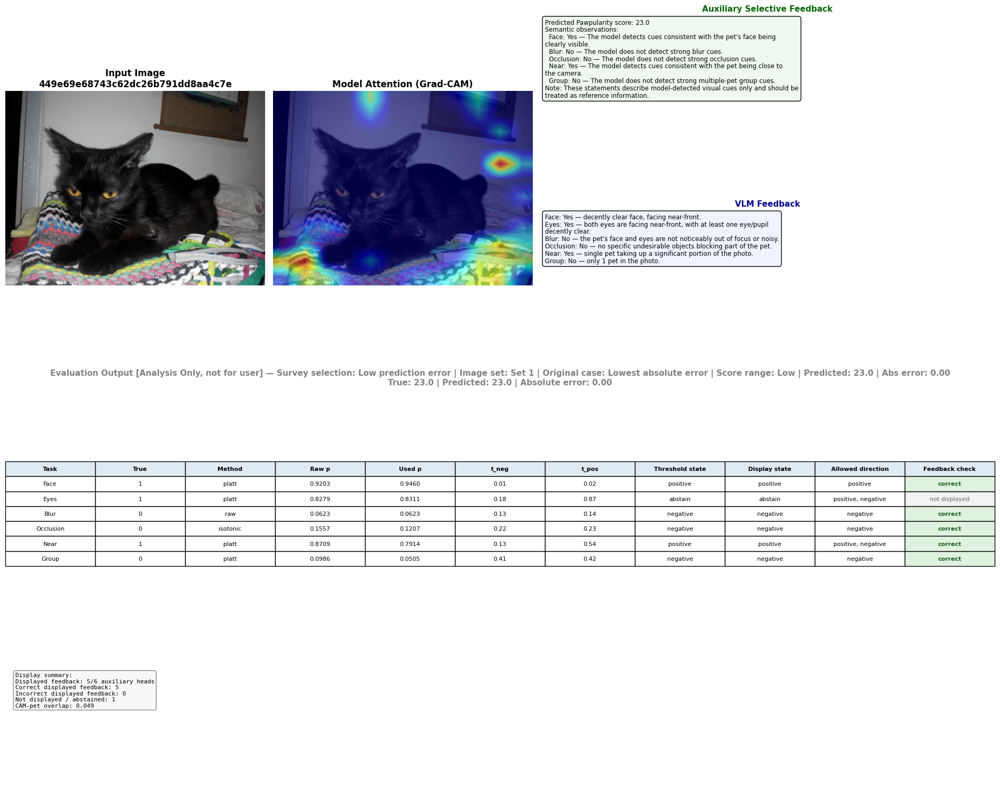

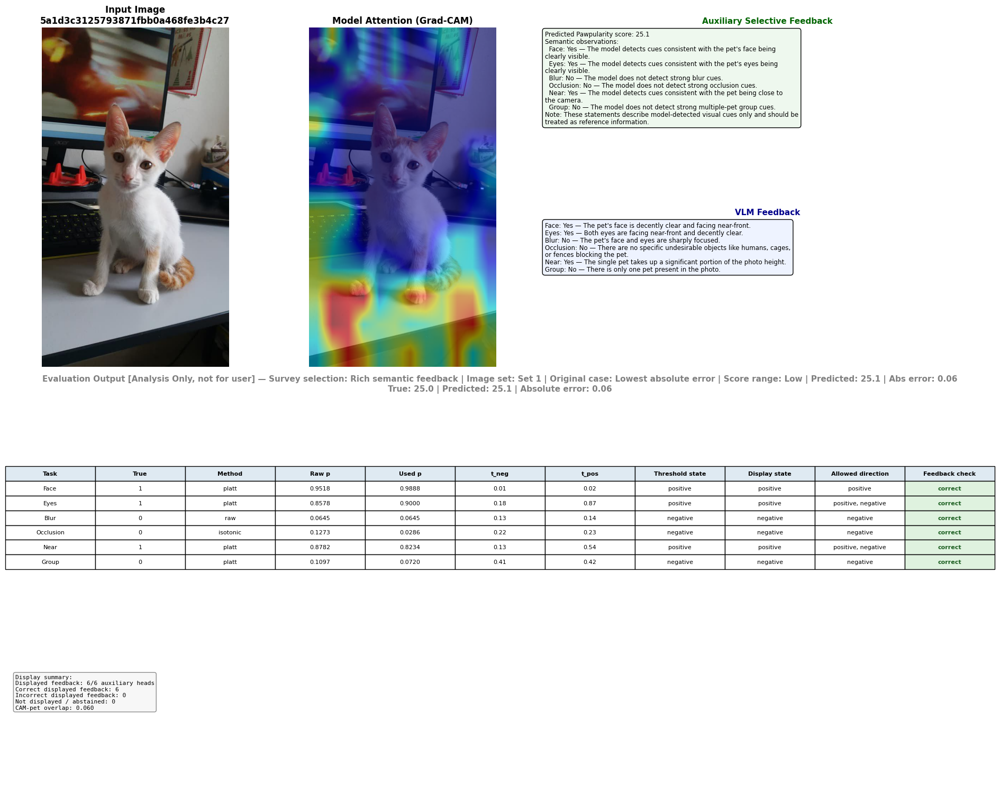

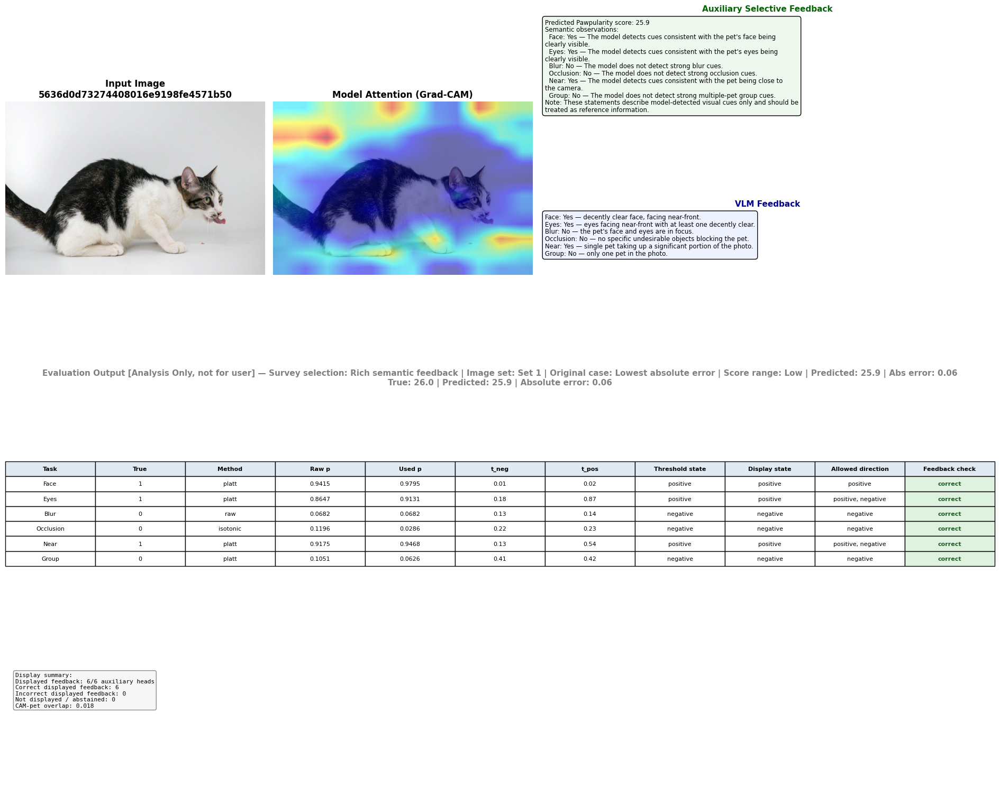

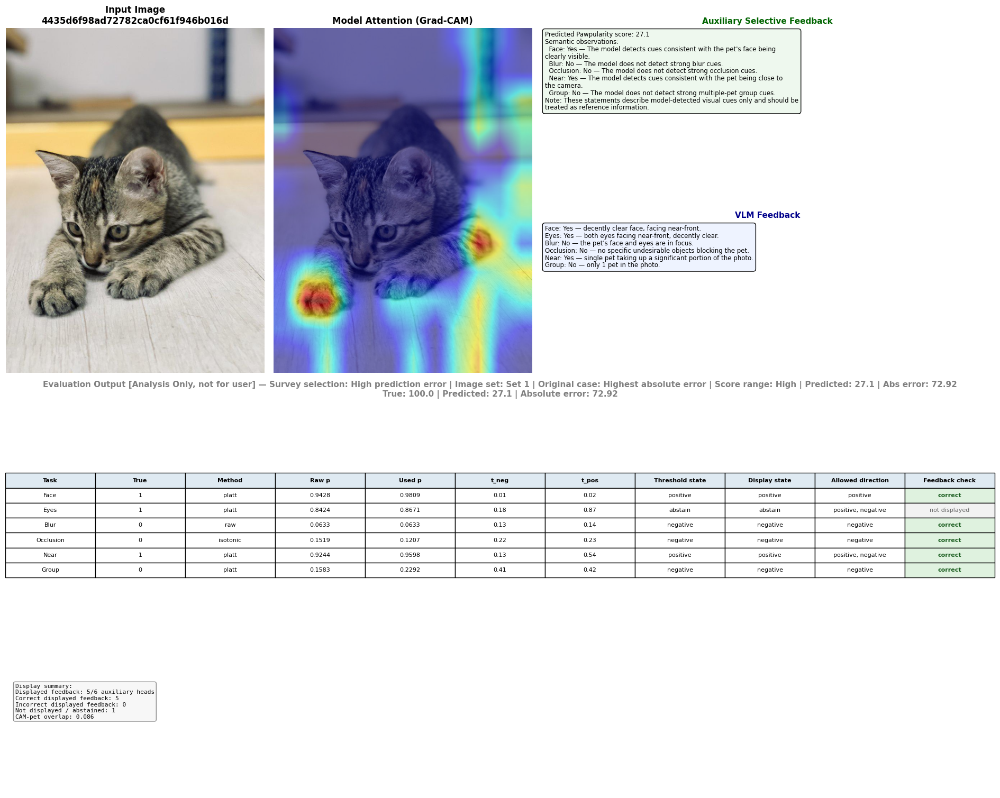

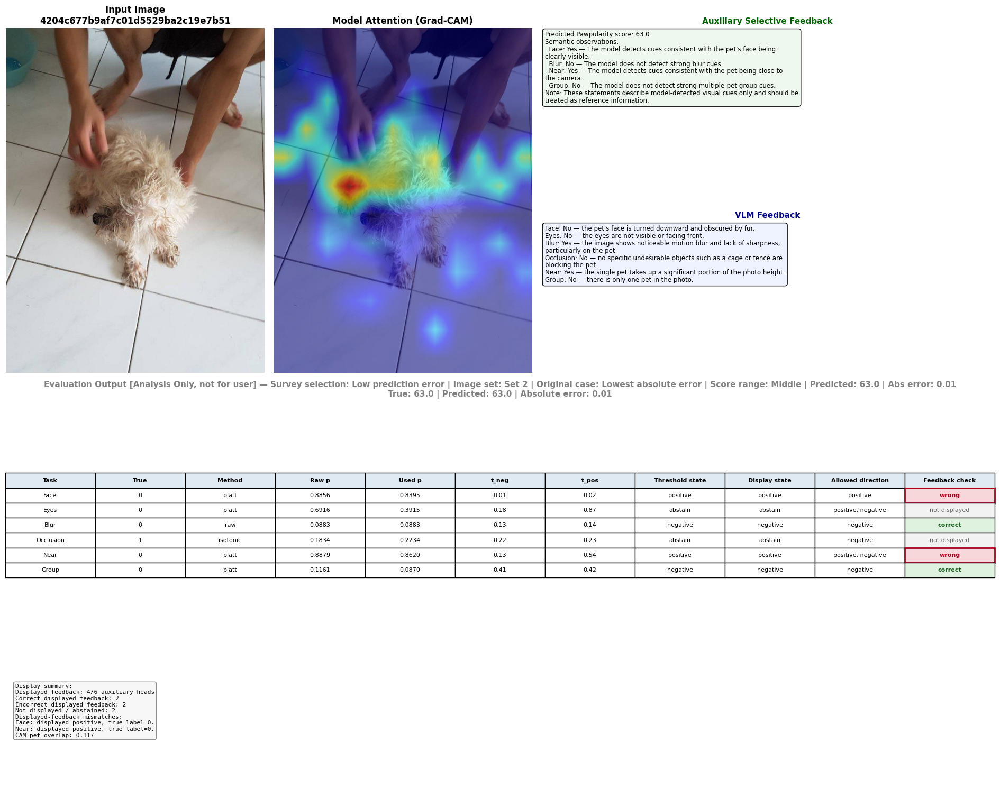

...

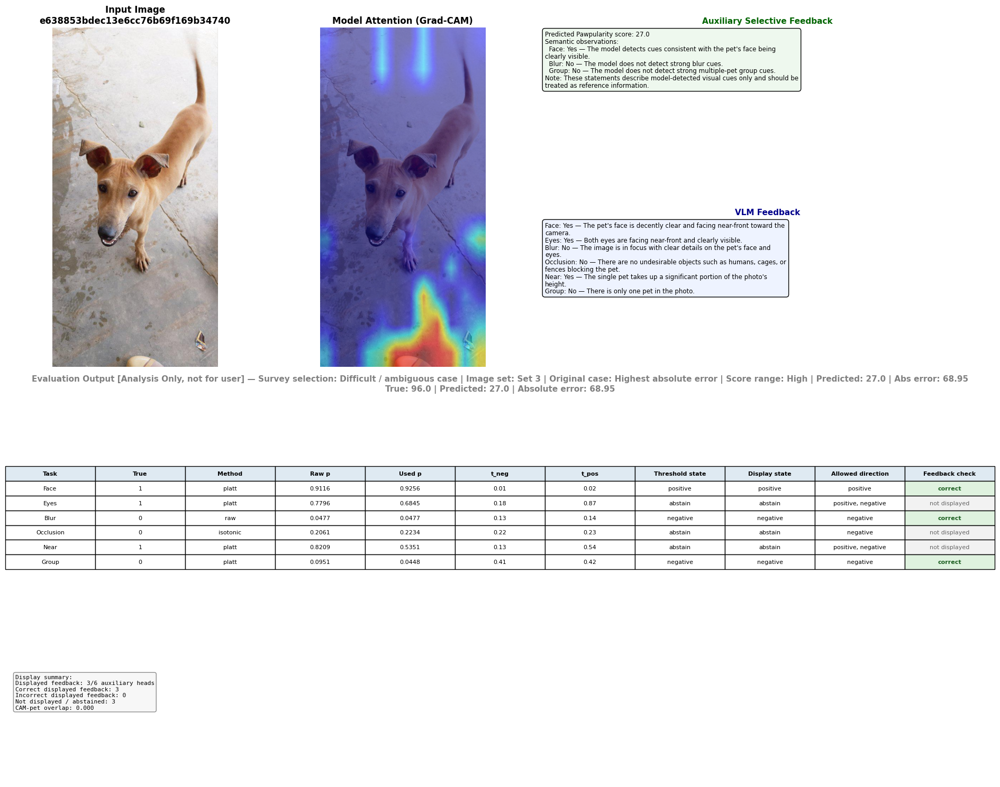

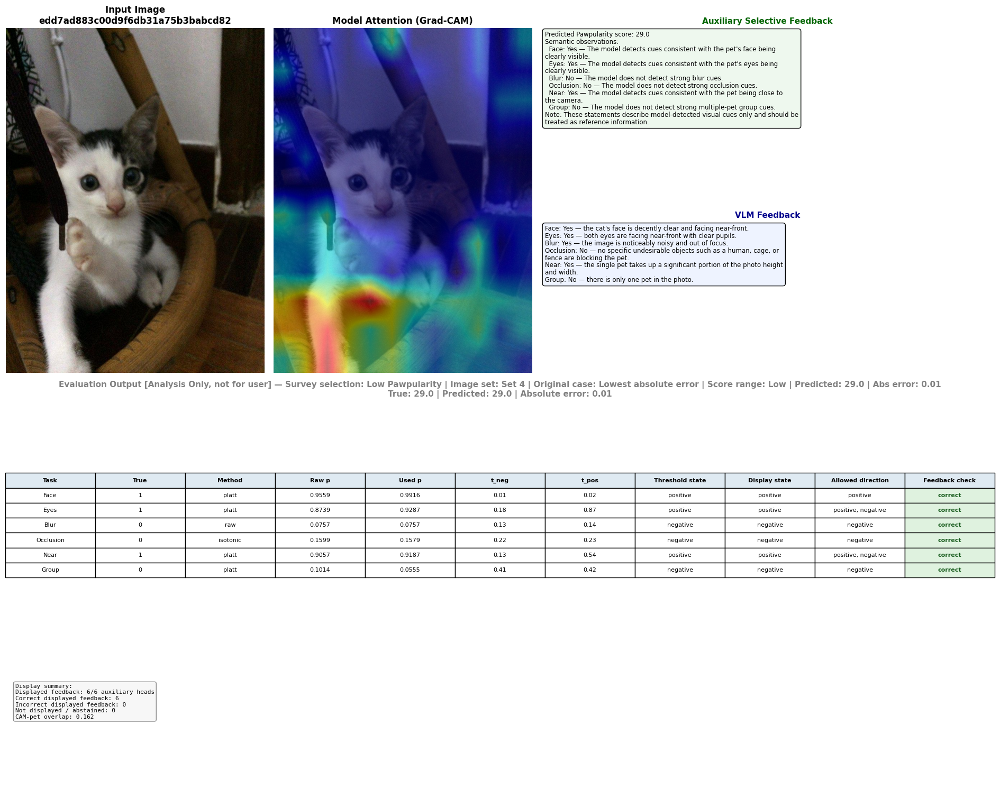

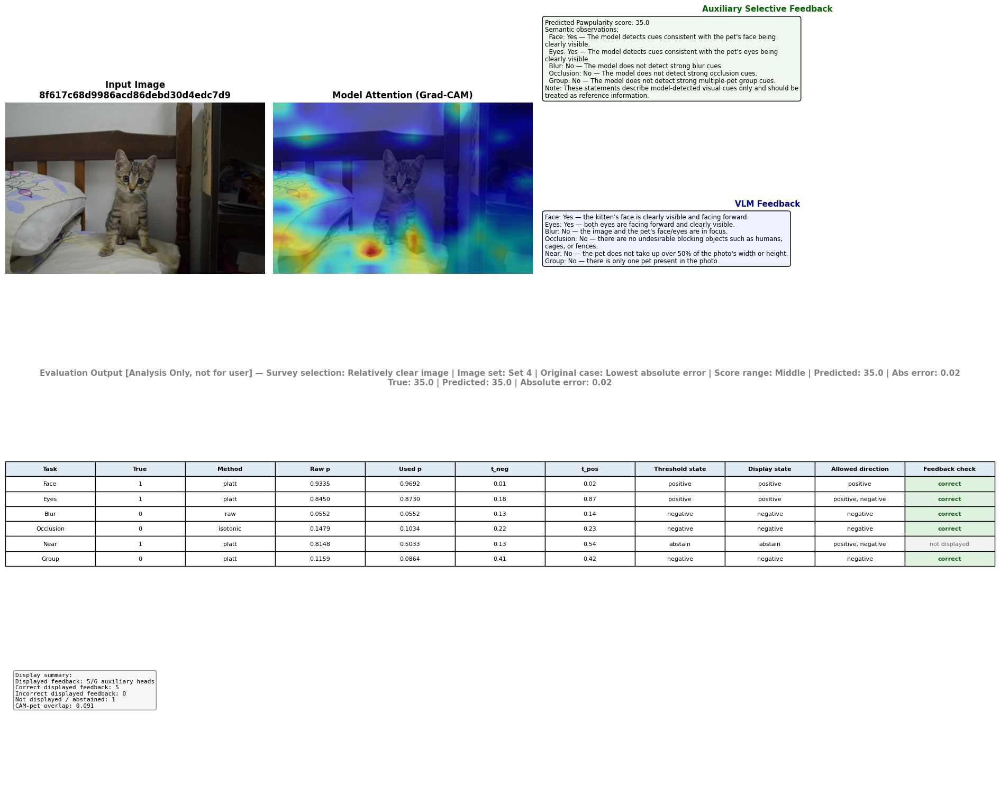

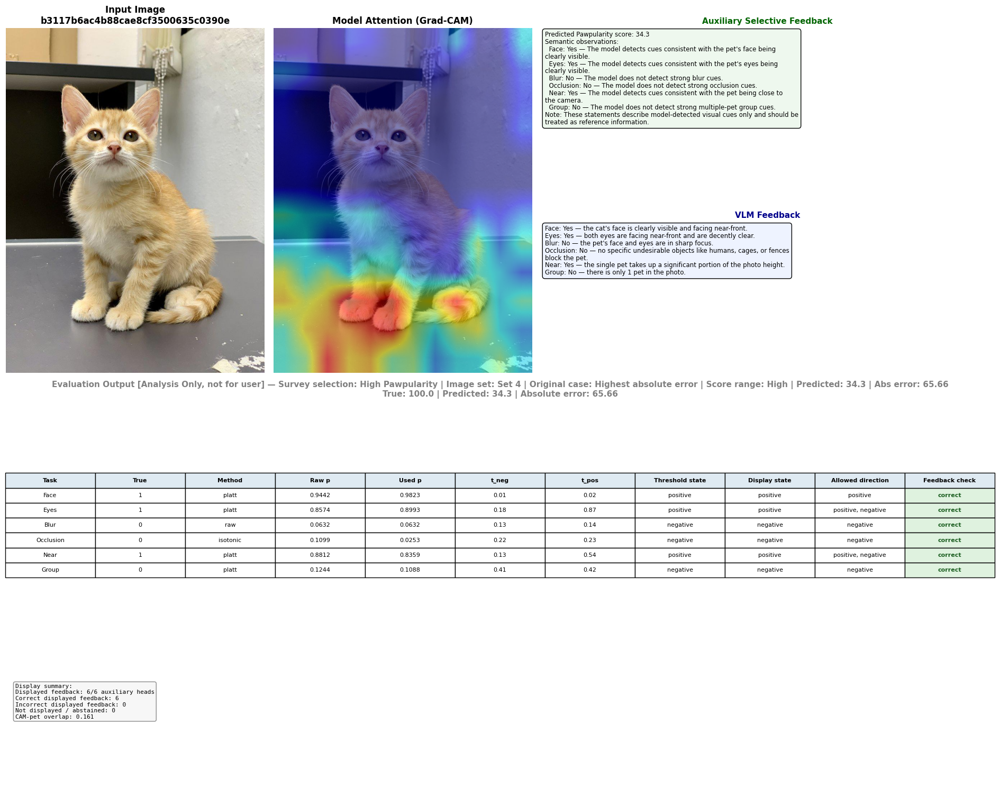

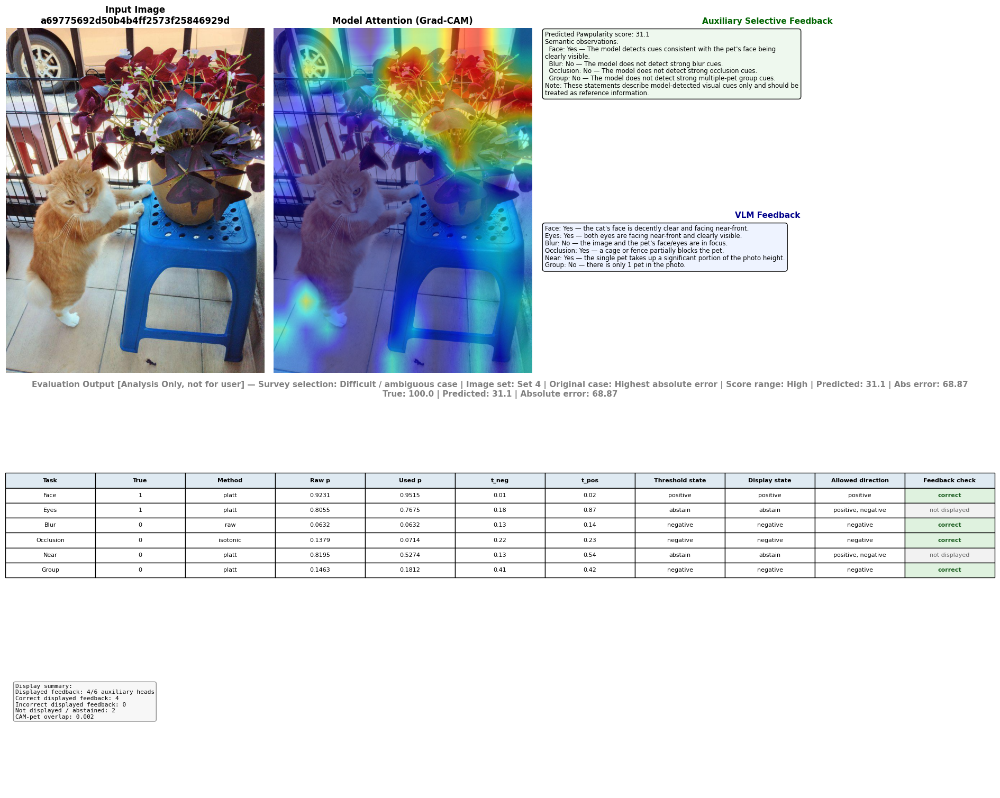

,image_set,image_order_in_set,survey_selection_reason,Id,fold,true_paw,pred_paw,cam_pet_overlap,vlm_feedback
0,Set 1,1,Low prediction error,449e69e68743c62dc26b791dd8aa4c7e,4,23.0,23.000641,0.049021,"Face: Yes — decently clear face, facing near-f..."
1,Set 1,2,Rich semantic feedback,5a1d3c3125793871fbb0a468fe3b4c27,4,25.0,25.059776,0.059552,Face: Yes — The pet's face is decently clear a...
2,Set 1,3,Rich semantic feedback,5636d0d73274408016e9198fe4571b50,4,26.0,25.935701,0.017913,"Face: Yes — decently clear face, facing near-f..."
3,Set 1,4,High prediction error,4435d6f98ad72782ca0cf61f946b016d,5,100.0,27.077641,0.086371,"Face: Yes — decently clear face, facing near-f..."
4,Set 2,1,Low prediction error,4204c677b9af7c01d5529ba2c19e7b51,5,63.0,62.992924,0.116938,Face: No — the pet's face is turned downward a...
5,Set 2,2,Abstention case,befc7aa8e68e5609a45dd5710b84dc84,5,38.0,37.970337,0.023502,Face: No — the cat's head is tilted upward and...
6,Set 2,3,Abstention case,e461020f04c3b80141ee51f659cb5d97,5,41.0,41.074966,0.059429,Face: Yes — the main puppy's face is decently ...
7,Set 2,4,High prediction error,941e532a21f7edb21766e88a15e588cb,4,100.0,30.122242,0.023294,Face: Yes — the puppy's face is clearly visibl...
8,Set 3,1,Relatively clear image,801119ab22c7fa337c1e0186ea05419f,4,62.0,61.992180,0.014441,Face: Yes — the pet's face is clearly visible ...
9,Set 3,2,Middle Pawpularity,f41025e7be39a7331ffdb3af1bd8ec7c,4,35.0,35.015305,0.040598,Face: Yes — both pets have decently clear face...


In [82]:
# ===================== Part 29C ===========================
# SECTION 6 — STEP 6C-3
# Research preview of six-attribute auxiliary and VLM feedback.
# =========================================================

import os
import textwrap
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

RESEARCH_OUTPUT_DIR = (
    Path(VLM_SIX_OUTPUT_DIR) / "research_analysis"
)

RESEARCH_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

RESEARCH_EXPORT_DPI = 1800

from src.inference_feedback import (
    load_model,
    preprocess,
    predict_pawpularity,
    get_gradcam,
    detect_pet_bbox,
    get_cam_overlap,
)

from src.vlm_feedback import FIXED_VLM_TASKS

CHECK_SWIN_GRID = (7, 7)

SURVEY_AUX_TASKS = FIXED_VLM_TASKS.copy()

assert SURVEY_AUX_TASKS == [
    "Face", "Eyes", "Blur", "Occlusion", "Near", "Group"
]

assert six_vlm_feedback_df[
    "n_displayed_aux_tasks"
].eq(6).all()

assert six_vlm_feedback_df[
    "displayed_aux_tasks"
].eq(", ".join(SURVEY_AUX_TASKS)).all()

assert set(user_eval_images_df["Id"]).issubset(
    set(six_vlm_feedback_df["Id"])
)

#
image_fold_by_id = aux_df.set_index("Id")["fold"].to_dict()

true_paw_dict = (
    user_eval_images_df.set_index("Id")["true_paw"].to_dict()
)

true_aux_dict = {
    row["Id"]: {
        task: int(row[f"{task}_true"])
        for task in SURVEY_AUX_TASKS
    }
    for _, row in aux_df[
        aux_df["Id"].isin(user_eval_images_df["Id"])
    ].iterrows()
}

if "models_by_fold" not in globals():
    models_by_fold = {}

required_folds = {
    int(image_fold_by_id[image_id])
    for image_id in user_eval_images_df["Id"]
}

for fold in sorted(required_folds):
    if fold not in models_by_fold:
        models_by_fold[fold] = load_model(
            fold=fold,
            cfg=ACTIVE_CFG,
            out_dir=ACTIVE_DIR,
            device=device,
        )

if "survey_selection_reason" not in user_eval_images_df.columns:
    user_eval_images_df = user_eval_images_df.copy()
    user_eval_images_df["survey_selection_reason"] = (
        "Not recorded in saved assignments"
    )


def _get_vlm_feedback_for_image(img_id, vlm_feedback_df):
    match = vlm_feedback_df[
        vlm_feedback_df["Id"] == img_id
    ]

    if len(match) == 0:
        return "VLM feedback is not available for this image."

    return str(match.iloc[0]["vlm_feedback"])


def _wrap_panel_text(text, width=82):
    wrapped_lines = []

    for line in str(text).splitlines():
        if not line.strip():
            wrapped_lines.append("")
        else:
            wrapped_lines.extend(
                textwrap.wrap(line, width=width)
            )

    return "\n".join(wrapped_lines)


def visualise_analysis_with_vlm(
    img_id,
    img_folder,
    cfg,
    models_by_fold,
    image_fold_by_id,
    aux_tasks,
    device,
    swin_grid,
    predict_aux_selective,
    true_paw_dict,
    true_aux_dict,
    vlm_feedback_df,
    label="",
    use_yolo=True,
):
    path = os.path.join(img_folder, img_id + ".jpg")

    if not os.path.exists(path):
        raise FileNotFoundError(path)

    fold = int(image_fold_by_id[img_id])
    models = [models_by_fold[fold]]

    img_tensor, img_pil = preprocess(path, cfg)

    paw = predict_pawpularity(
        img_tensor=img_tensor,
        allFolds_models=models,
        device=device,
        fold=0,
    )

    aux_results = predict_aux_selective(
        img_tensor=img_tensor,
        allFolds_models=models,
        cfg=cfg,
        aux_tasks=aux_tasks,
        device=device,
        heldout_fold=fold,
    )

    _validate(aux_results, aux_tasks)

    _, cam_rsz, cam_ov = get_gradcam(
        img_tensor,
        img_pil,
        models,
        device,
        swin_grid,
    )

    overlap = None

    if use_yolo:
        bbox = detect_pet_bbox(path)

        if bbox is not None:
            overlap = get_cam_overlap(
                cam_rsz,
                bbox,
                img_pil,
            )

    true_paw = (true_paw_dict or {}).get(img_id)
    true_aux = (true_aux_dict or {}).get(img_id, {})

    user_fb = generate_feedback_user(
        paw,
        aux_results,
        aux_tasks,
        overlap,
    )

    eval_out = generate_output_evaluation(
        paw,
        aux_results,
        aux_tasks,
        true_paw,
        true_aux,
        overlap,
    )

    vlm_feedback = _get_vlm_feedback_for_image(
        img_id,
        vlm_feedback_df,
    )

    fig = plt.figure(figsize=(19, 15))

    grid = fig.add_gridspec(
        3,
        3,
        height_ratios=[1.35, 0.95, 0.45],
        width_ratios=[1.0, 1.0, 1.75],
    )

    image_ax = fig.add_subplot(grid[0, 0])
    image_ax.imshow(img_pil)
    image_ax.axis("off")
    image_ax.set_title(
        f"Input Image\n{img_id}",
        fontweight="bold",
    )

    cam_ax = fig.add_subplot(grid[0, 1])
    cam_ax.imshow(cam_ov)
    cam_ax.axis("off")
    cam_ax.set_title(
        "Model Attention (Grad-CAM)",
        fontweight="bold",
    )

    feedback_grid = grid[0, 2].subgridspec(
        2,
        1,
        height_ratios=[1.05, 0.95],
        hspace=0.18,
    )

    aux_feedback_ax = fig.add_subplot(
        feedback_grid[0, 0]
    )

    vlm_feedback_ax = fig.add_subplot(
        feedback_grid[1, 0]
    )

    aux_feedback_ax.axis("off")
    vlm_feedback_ax.axis("off")

    aux_feedback_ax.set_title(
        "Auxiliary Selective Feedback",
        fontsize=11,
        fontweight="bold",
        color="darkgreen",
    )

    vlm_feedback_ax.set_title(
        "VLM Feedback",
        fontsize=11,
        fontweight="bold",
        color="darkblue",
    )

    aux_text = "\n".join(user_fb)

    aux_feedback_ax.text(
        0.01,
        0.98,
        _wrap_panel_text(aux_text, width=78),
        transform=aux_feedback_ax.transAxes,
        va="top",
        fontsize=8.5,
        linespacing=1.08,
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="#eef8ee",
            edgecolor="black",
        ),
    )

    vlm_feedback_ax.text(
        0.01,
        0.98,
        _wrap_panel_text(str(vlm_feedback), width=78),
        transform=vlm_feedback_ax.transAxes,
        va="top",
        fontsize=8.5,
        linespacing=1.08,
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="#eef3ff",
            edgecolor="black",
        ),
    )

    table_ax = fig.add_subplot(grid[1, :])
    table_ax.axis("off")

    title = "Evaluation Output [Analysis Only, not for user]"

    if label:
        title += f" — {label}"

    table_ax.set_title(
        f"{title}\n{eval_out['score_text']}",
        fontsize=11,
        fontweight="bold",
        color="gray",
        pad=10,
    )

    columns = [
        "Task",
        "True",
        "Method",
        "Raw p",
        "Used p",
        "t_neg",
        "t_pos",
        "Threshold state",
        "Display state",
        "Allowed direction",
        "Feedback check",
    ]

    table = table_ax.table(
        cellText=eval_out["rows"],
        colLabels=columns,
        loc="center",
        cellLoc="center",
    )

    table.auto_set_font_size(False)
    table.set_fontsize(8)
    table.scale(1.0, 1.3)

    for (row, col), cell in table.get_celld().items():
        if row == 0:
            cell.set_text_props(weight="bold")
            cell.set_facecolor("#dfeaf2")

    feedback_check_col = columns.index("Feedback check")

    for (row, col), cell in table.get_celld().items():
        if row == 0 or col != feedback_check_col:
            continue

        value = cell.get_text().get_text().strip().lower()

        if value == "wrong":
            cell.set_facecolor("#f8d7da")
            cell.set_edgecolor("#b00020")
            cell.set_linewidth(2.0)
            cell.set_text_props(
                color="#b00020",
                weight="bold",
            )

        elif value == "correct":
            cell.set_facecolor("#dff2df")
            cell.set_text_props(
                color="#1b5e20",
                weight="bold",
            )

        elif value == "not displayed":
            cell.set_facecolor("#f2f2f2")
            cell.set_text_props(color="#666666")

    summary_ax = fig.add_subplot(grid[2, :])
    summary_ax.axis("off")

    summary_lines = ["Display summary:"]

    if eval_out.get("summary"):
        summary_lines.extend(eval_out["summary"])

    if eval_out.get("reasons"):
        summary_lines.append(
            "Displayed-feedback mismatches:"
        )
        summary_lines.extend(eval_out["reasons"])

    if eval_out.get("overlap") is not None:
        summary_lines.append(
            f"CAM-pet overlap: {eval_out['overlap']:.3f}"
        )

    summary_ax.text(
        0.01,
        0.95,
        "\n".join(summary_lines),
        transform=summary_ax.transAxes,
        va="top",
        fontsize=8,
        family="monospace",
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor="#f7f7f7",
            edgecolor="gray",
            alpha=0.9,
        ),
    )

    # plt.tight_layout()
    # plt.show()
    # plt.close(fig)
    plt.tight_layout()

    image_info = user_eval_images_df.loc[
        user_eval_images_df["Id"] == img_id
    ].iloc[0]

    set_name = (
        str(image_info["image_set"])
        .strip()
        .lower()
        .replace(" ", "_")
    )

    image_order = int(image_info["image_order_in_set"])

    output_stem = (
        f"{set_name}_image_{image_order:02d}_{img_id}"
    )

    fig.savefig(
        RESEARCH_OUTPUT_DIR / f"{output_stem}.png",
        dpi=RESEARCH_EXPORT_DPI,
        bbox_inches="tight",
        facecolor="white",
    )

    fig.savefig(
        RESEARCH_OUTPUT_DIR / f"{output_stem}.pdf",
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()
    plt.close(fig)

    row = {
        "Id": img_id,
        "fold": fold,
        "true_paw": true_paw,
        "pred_paw": paw,
        "cam_pet_overlap": overlap,
        "vlm_feedback": vlm_feedback,
    }

    for task in aux_tasks:
        result = aux_results[task]
        prefix = task.lower()

        row[f"{prefix}_true"] = true_aux.get(task)

        for field, value in result.items():
            row[f"{prefix}_{field}"] = value

        row[f"{prefix}_prob"] = (
            result["calibrated_probability"]
        )

        row[f"{prefix}_pred"] = {
            "positive": 1,
            "negative": 0,
            "abstain": None,
        }[result["prototype_state"]]

    return row


survey_case_info = user_eval_images_df.set_index("Id")

survey_case_labels = {}

for row in user_eval_images_df.itertuples(index=False):
    label_parts = [
        f"Survey selection: {row.survey_selection_reason}",
        f"Image set: {row.image_set}",
        f"Original case: {row.case_type}",
        f"Score range: {row.score_range}",
        f"Predicted: {float(row.pred_paw):.1f}",
        f"Abs error: {float(row.absolute_error):.2f}",
    ]

    survey_case_labels[row.Id] = " | ".join(label_parts)


survey_case_batch_rows = []

for img_id in user_eval_images_df["Id"].tolist():
    row = visualise_analysis_with_vlm(
        img_id=img_id,
        img_folder=IMG_FOLDER,
        cfg=ACTIVE_CFG,
        models_by_fold=models_by_fold,
        image_fold_by_id=image_fold_by_id,
        aux_tasks=SURVEY_AUX_TASKS,
        device=device,
        swin_grid=CHECK_SWIN_GRID,
        predict_aux_selective=predict_aux_selective,
        true_paw_dict=true_paw_dict,
        true_aux_dict=true_aux_dict,
        vlm_feedback_df=six_vlm_feedback_df,
        label=survey_case_labels.get(img_id, ""),
        use_yolo=True,
    )

    row["survey_selection_reason"] = survey_case_info.loc[
        img_id,
        "survey_selection_reason",
    ]

    row["image_set"] = survey_case_info.loc[
        img_id,
        "image_set",
    ]

    row["image_order_in_set"] = survey_case_info.loc[
        img_id,
        "image_order_in_set",
    ]

    survey_case_batch_rows.append(row)


survey_case_batch_results = pd.DataFrame(
    survey_case_batch_rows
)

display(
    survey_case_batch_results[
        [
            "image_set",
            "image_order_in_set",
            "survey_selection_reason",
            "Id",
            "fold",
            "true_paw",
            "pred_paw",
            "cam_pet_overlap",
            "vlm_feedback",
        ]
    ]
)

In [75]:
# ===================== Part 30 ============================
# SECTION 6 — STEP 6D
# Build and save six-attribute user-evaluation materials.
# Preserve the existing image assignments and counterbalancing.
# =========================================================

from pathlib import Path
import pandas as pd

from src.user_evaluation import (
    build_condition_materials,
    build_counterbalanced_versions,
    build_questionnaire_items,
    build_survey_export,
    build_design_summary,
    save_user_eval_outputs,
)

SURVEY_AUX_TASKS = [
    "Face", "Eyes", "Blur", "Occlusion", "Near", "Group"
]

MATERIALS_LABEL = "survey_materials"

USER_EVAL_OUTPUT_DIR = (
    Path(VLM_SIX_OUTPUT_DIR)
    / MATERIALS_LABEL
)



# ---------------------------------------------------------
# 1. Load the six-attribute VLM results
# ---------------------------------------------------------

vlm_feedback_df = pd.read_csv(
    VLM_SIX_FEEDBACK_PATH,
    dtype={"Id": str},
)

assert vlm_feedback_df["Id"].is_unique

assert set(user_eval_images_df["Id"]) == set(
    vlm_feedback_df["Id"]
)

assert vlm_feedback_df[
    "n_displayed_aux_tasks"
].eq(6).all()

assert vlm_feedback_df[
    "displayed_aux_tasks"
].eq(", ".join(SURVEY_AUX_TASKS)).all()

assert vlm_feedback_df["vlm_feedback"].notna().all()

# ---------------------------------------------------------
# 2. Prepare one auxiliary text per image for both B and D
# ---------------------------------------------------------

auxiliary_result_lookup = (
    survey_case_batch_results.set_index(
        "Id",
        verify_integrity=True,
    )
)

auxiliary_feedback_by_id = {}

for _, image in user_eval_images_df.iterrows():

    image_id = image["Id"]
    result_row = auxiliary_result_lookup.loc[image_id]

    aux_results = {}

    for task in SURVEY_AUX_TASKS:
        prefix = task.lower()

        aux_results[task] = {
            "raw_probability": result_row[
                f"{prefix}_raw_probability"
            ],
            "calibrated_probability": result_row[
                f"{prefix}_calibrated_probability"
            ],
            "threshold_state": result_row[
                f"{prefix}_threshold_state"
            ],
            "prototype_state": result_row[
                f"{prefix}_prototype_state"
            ],
        }

    auxiliary_feedback_by_id[image_id] = "\n".join(
        generate_feedback_user(
            paw_score=float(image["pred_paw"]),
            aux_results=aux_results,
            aux_tasks=SURVEY_AUX_TASKS,
        )
    )


def attach_participant_feedback(materials_df):
    """Attach actual feedback without changing assignments."""

    result = materials_df.copy()

    result["aux_feedback"] = result.apply(
        lambda row: auxiliary_feedback_by_id[row["Id"]]
        if row["condition"] in ["B", "D"]
        else "",
        axis=1,
    )

    def participant_text(row):
        score_text = (
            f"Predicted Pawpularity score: "
            f"{float(row['pred_paw']):.1f}"
        )

        if row["condition"] in ["B", "D"]:
            return row["aux_feedback"]

        if row["condition"] == "C":
            return (
                score_text
                + "\n\nVLM feedback:\n"
                + str(row["vlm_feedback"])
            )

        return (
            score_text
            + "\n\nNo additional explanation is shown "
            "in this condition."
        )

    result["participant_text"] = result.apply(
        participant_text,
        axis=1,
    )

    # Replace legacy placeholder instructions in the export.
    if "display_instruction" in result.columns:
        result["display_instruction"] = (
            result["participant_text"]
        )

    return result


# ---------------------------------------------------------
# 3. Build condition materials and counterbalanced versions
# ---------------------------------------------------------

condition_materials_df = build_condition_materials(
    user_eval_images_df=user_eval_images_df,
    vlm_feedback_df=vlm_feedback_df,
    img_folder=IMG_FOLDER,
)

CONDITION_ORDER = ["A", "B", "C", "D"]

user_eval_versions_df = build_counterbalanced_versions(
    user_eval_images_df=user_eval_images_df,
    condition_materials_df=condition_materials_df,
    condition_order=CONDITION_ORDER,
)

condition_materials_df = attach_participant_feedback(
    condition_materials_df
)

user_eval_versions_df = attach_participant_feedback(
    user_eval_versions_df
)

assert len(user_eval_versions_df) == 64

# Verify identical B/D semantic feedback for each image.
for image_id, group in user_eval_versions_df.groupby("Id"):

    b_text = group.loc[
        group["condition"] == "B",
        "participant_text",
    ].iloc[0]

    d_text = group.loc[
        group["condition"] == "D",
        "participant_text",
    ].iloc[0]

    assert b_text == d_text, (
        f"B/D feedback mismatch for {image_id}"
    )

# ---------------------------------------------------------
# 4. Build the survey export
# ---------------------------------------------------------

questionnaire_df = build_questionnaire_items()

survey_export_df = build_survey_export(
    user_eval_versions_df=user_eval_versions_df,
    questionnaire_df=questionnaire_df,
)

survey_export_df = attach_participant_feedback(
    survey_export_df
)

# Retain set metadata omitted by the original export helper.
survey_export_df = survey_export_df.merge(
    user_eval_versions_df[
        [
            "version",
            "Id",
            "image_set",
            "image_order_in_set",
        ]
    ],
    on=["version", "Id"],
    how="left",
    validate="one_to_one",
)

# ---------------------------------------------------------
# 5. Record the current study design
# ---------------------------------------------------------

study_vlm_models = vlm_feedback_df[
    "vlm_model"
].dropna().unique()

assert len(study_vlm_models) == 1

user_eval_design_summary_df = build_design_summary(
    user_eval_images_df=user_eval_images_df,
    user_eval_versions_df=user_eval_versions_df,
    condition_order=CONDITION_ORDER,
    vlm_model=study_vlm_models[0],
)

user_eval_design_summary_df.loc[
    user_eval_design_summary_df["item"] == "VLM prompt type",
    "value",
] = (
    "Fixed six-attribute prompt applied independently "
    "to every selected image"
)

user_eval_design_note = """
The study uses 16 images divided into four sets of four.
The existing set membership and within-set order are preserved.
Conditions A–D are counterbalanced across four participant versions.
B and D use identical selective auxiliary feedback.
D additionally includes Grad-CAM.
""".strip()

vlm_user_eval_methods_text = """
Conditions B, C and D use the same six semantic attributes:
Face, Eyes, Blur, Occlusion, Near and Group.

B and D apply the existing calibration and selective-feedback
policy. Statements are withheld when the policy requires abstention.

C independently evaluates all six attributes from each image.
Auxiliary predictions, thresholds, labels and Pawpularity scores
are not supplied to the VLM.

The actual number of displayed statements may differ between
the auxiliary and VLM conditions.
""".strip()

# ---------------------------------------------------------
# 6. Save to directory
# ---------------------------------------------------------

USER_EVAL_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

saved_paths = save_user_eval_outputs(
    active_dir=str(USER_EVAL_OUTPUT_DIR),
    condition_materials_df=condition_materials_df,
    user_eval_versions_df=user_eval_versions_df,
    questionnaire_df=questionnaire_df,
    survey_export_df=survey_export_df,
    design_summary_df=user_eval_design_summary_df,
    design_note=user_eval_design_note,
    methods_text=vlm_user_eval_methods_text,
)

print("Saved user-evaluation materials:")

for name, path in saved_paths.items():
    print(name, ":", path)

print("Current materials saved; matching existing files updated.")

Saved user-evaluation materials:
condition_materials : ../../outputs/extra/exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion/VLM_Six_Heads/six_review/vlm_full_six/survey_materials/user_eval_condition_materials.csv
counterbalanced_versions : ../../outputs/extra/exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion/VLM_Six_Heads/six_review/vlm_full_six/survey_materials/user_eval_counterbalanced_versions.csv
questionnaire : ../../outputs/extra/exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion/VLM_Six_Heads/six_review/vlm_full_six/survey_materials/user_eval_questionnaire_items.csv
survey_export : ../../outputs/extra/exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion/VLM_Six_Heads/six_review/vlm_full_six/survey_materials/user_eval_survey_export.csv
design_summary : ../../outputs/extra/exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion/VLM_Six_Heads/six_review/vlm_full_six/survey_materials/user_eval_design_summary

In [76]:
# ===================== Part 30B ===========================
# SECTION 6 — STEP 6J
# Export six-attribute participant-facing survey images.
# Research labels, errors and thresholds are not displayed.
# =========================================================

from pathlib import Path
import textwrap
import matplotlib.pyplot as plt

from PIL import Image
from matplotlib.patches import FancyBboxPatch

SURVEY_VERSIONS_TO_EXPORT = [
    "Version 1",
    "Version 2",
    "Version 3",
    "Version 4",
]

EXPORT_DPI = 300
SHOW_PREVIEW_PLOTS = False

SURVEY_PREVIEW_ROOT = (
    Path(USER_EVAL_OUTPUT_DIR)
    / "survey_preview_images"
)

SURVEY_PREVIEW_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

def _wrap_lines(text, width=82):
    wrapped = []

    for line in str(text).splitlines():
        if not line.strip():
            wrapped.append("")
        else:
            wrapped.extend(
                textwrap.wrap(
                    line,
                    width=width,
                )
            )

    return "\n".join(wrapped)


def _get_gradcam_overlay_for_image(img_id):
    fold = int(image_fold_by_id[img_id])
    models = [models_by_fold[fold]]

    image_path = (
        Path(IMG_FOLDER) / f"{img_id}.jpg"
    )

    img_tensor, img_pil = preprocess(
        str(image_path),
        ACTIVE_CFG,
    )

    _, _, cam_overlay = get_gradcam(
        img_tensor,
        img_pil,
        models,
        device,
        CHECK_SWIN_GRID,
    )

    return cam_overlay


def save_user_eval_condition_image(
    row,
    output_path,
    show_plot=False,
):
    condition = row["condition"]

    with Image.open(row["image_path"]) as opened_image:
        image = opened_image.convert("RGB")

    # Part 30 already prepared the correct condition text.
    feedback_text = _wrap_lines(
        row["participant_text"],
        width=82,
    )

    show_gradcam = bool(row["show_gradcam"])

    if show_gradcam:
        fig = plt.figure(figsize=(9.5, 12.8))

        grid = fig.add_gridspec(
            3,
            1,
            height_ratios=[0.95, 0.10, 1.95],
            hspace=0.16,
        )
    else:
        fig = plt.figure(figsize=(9.5, 8.5))

        grid = fig.add_gridspec(
            3,
            1,
            height_ratios=[1.0, 0.12, 0.62],
            hspace=0.16,
        )

    image_ax = fig.add_subplot(grid[0, 0])
    title_ax = fig.add_subplot(grid[1, 0])
    info_ax = fig.add_subplot(grid[2, 0])

    image_ax.imshow(image)
    image_ax.axis("off")
    image_ax.set_title(
        "Pet image",
        fontweight="bold",
        fontsize=14,
    )

    title_ax.axis("off")
    title_ax.text(
        0.5,
        0.5,
        f"Condition {condition}: {row['condition_name']}",
        ha="center",
        va="center",
        fontweight="bold",
        color="darkgreen",
        fontsize=14,
    )

    info_ax.axis("off")

    if show_gradcam:
        info_box = FancyBboxPatch(
            (0.01, 0.02),
            0.98,
            0.96,
            boxstyle="round,pad=0.01",
            transform=info_ax.transAxes,
            facecolor="#eef8ee",
            edgecolor="#333333",
            linewidth=1.0,
        )

        info_ax.add_patch(info_box)

        cam_overlay = _get_gradcam_overlay_for_image(
            row["Id"]
        )

        cam_ax = info_ax.inset_axes(
            [0.27, 0.55, 0.46, 0.36]
        )

        cam_ax.imshow(cam_overlay)
        cam_ax.axis("off")
        cam_ax.set_title(
            "Model attention",
            fontweight="bold",
            fontsize=12,
            pad=4,
        )

        info_ax.text(
            0.035,
            0.45,
            feedback_text,
            transform=info_ax.transAxes,
            va="top",
            ha="left",
            fontsize=9.4,
            linespacing=1.05,
        )

    else:
        info_ax.text(
            0.02,
            0.95,
            feedback_text,
            transform=info_ax.transAxes,
            va="top",
            ha="left",
            fontsize=11,
            linespacing=1.15,
            bbox=dict(
                boxstyle="round,pad=0.5",
                facecolor="#eef8ee",
                edgecolor="#333333",
            ),
        )

    plt.tight_layout()

    try:
        # Replace the existing image using the same filename.
        with Path(output_path).open("wb") as handle:
            fig.savefig(
                handle,
                format="png",
                dpi=EXPORT_DPI,
                bbox_inches="tight",
                facecolor="white",
            )

        if show_plot:
            plt.show()

    finally:
        plt.close(fig)

    return str(output_path)


# ---------------------------------------------------------
# Validate the four versions before creating output files
# ---------------------------------------------------------

for version in SURVEY_VERSIONS_TO_EXPORT:
    version_rows = survey_export_df[
        survey_export_df["version"] == version
    ]

    assert len(version_rows) == 16
    assert version_rows["Id"].nunique() == 16

    for condition in CONDITION_ORDER:
        assert len(
            version_rows[
                version_rows["condition"] == condition
            ]
        ) == 4



# ---------------------------------------------------------
# Export all four counterbalanced versions
# ---------------------------------------------------------

saved_preview_paths = []
preview_manifest_rows = []

for version in SURVEY_VERSIONS_TO_EXPORT:

    version_folder = (
        SURVEY_PREVIEW_ROOT
        / version.replace(" ", "_").lower()
    )

    version_folder.mkdir(
        parents=True,
        exist_ok=True,
    )

  

    for condition in CONDITION_ORDER:

        condition_rows = (
            survey_export_df[
                (survey_export_df["version"] == version)
                & (
                    survey_export_df["condition"]
                    == condition
                )
            ]
            .sort_values("trial_order")
            .reset_index(drop=True)
        )

        for row_index, row in condition_rows.iterrows():

            output_path = (
                version_folder
                / (
                    f"condition_{condition}_"
                    f"trial_{row_index + 1:02d}.png"
                )
            )

            saved_path = save_user_eval_condition_image(
                row=row,
                output_path=output_path,
                show_plot=SHOW_PREVIEW_PLOTS,
            )

            saved_preview_paths.append(saved_path)

            preview_manifest_rows.append({
                "version": version,
                "condition": condition,
                "trial_order": row["trial_order"],
                "image_set": row["image_set"],
                "image_order_in_set": (
                    row["image_order_in_set"]
                ),
                "Id": row["Id"],
                "pred_paw": row["pred_paw"],
                "image_path": saved_path,
            })

preview_manifest_df = pd.DataFrame(
    preview_manifest_rows
)

assert len(saved_preview_paths) == 64

preview_manifest_df.to_csv(
    SURVEY_PREVIEW_ROOT / "survey_image_manifest.csv",
    index=False,
    encoding="utf-8-sig",
    mode="w",
)

print("Saved 64 survey images:")
print(SURVEY_PREVIEW_ROOT)

display(preview_manifest_df)

print("Existing survey images and manifest updated.")

/tmp/ipykernel_316056/771422189.py:197: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved 64 survey images:
../../outputs/extra/exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion/VLM_Six_Heads/six_review/vlm_full_six/survey_materials/survey_preview_images


,version,condition,trial_order,image_set,image_order_in_set,Id,pred_paw,image_path
0,Version 1,A,1,Set 1,1,449e69e68743c62dc26b791dd8aa4c7e,23.000641,../../outputs/extra/exp19_swin_384_strong_MSEL...
1,Version 1,A,2,Set 1,2,5a1d3c3125793871fbb0a468fe3b4c27,25.059776,../../outputs/extra/exp19_swin_384_strong_MSEL...
2,Version 1,A,3,Set 1,3,5636d0d73274408016e9198fe4571b50,25.935701,../../outputs/extra/exp19_swin_384_strong_MSEL...
3,Version 1,A,4,Set 1,4,4435d6f98ad72782ca0cf61f946b016d,27.077641,../../outputs/extra/exp19_swin_384_strong_MSEL...
4,Version 1,B,5,Set 2,1,4204c677b9af7c01d5529ba2c19e7b51,62.992924,../../outputs/extra/exp19_swin_384_strong_MSEL...
...,...,...,...,...,...,...,...,...
59,Version 4,C,16,Set 4,4,a69775692d50b4b4ff2573f25846929d,31.129736,../../outputs/extra/exp19_swin_384_strong_MSEL...
60,Version 4,D,1,Set 1,1,449e69e68743c62dc26b791dd8aa4c7e,23.000641,../../outputs/extra/exp19_swin_384_strong_MSEL...
61,Version 4,D,2,Set 1,2,5a1d3c3125793871fbb0a468fe3b4c27,25.059776,../../outputs/extra/exp19_swin_384_strong_MSEL...
62,Version 4,D,3,Set 1,3,5636d0d73274408016e9198fe4571b50,25.935701,../../outputs/extra/exp19_swin_384_strong_MSEL...


Existing survey images and manifest updated.


../../outputs/extra/exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion/VLM_Six_Heads/six_review/vlm_full_six/survey_materials/survey_preview_images/version_1/condition_A_trial_01.png


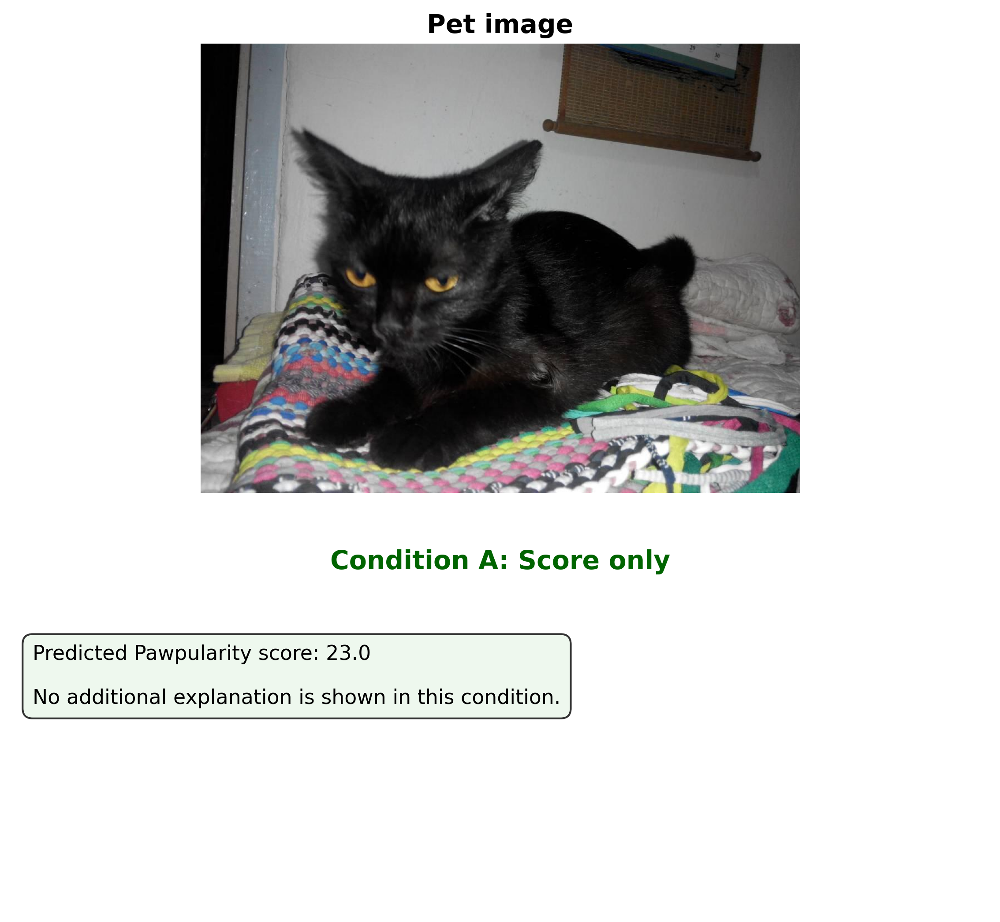

../../outputs/extra/exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion/VLM_Six_Heads/six_review/vlm_full_six/survey_materials/survey_preview_images/version_1/condition_A_trial_02.png


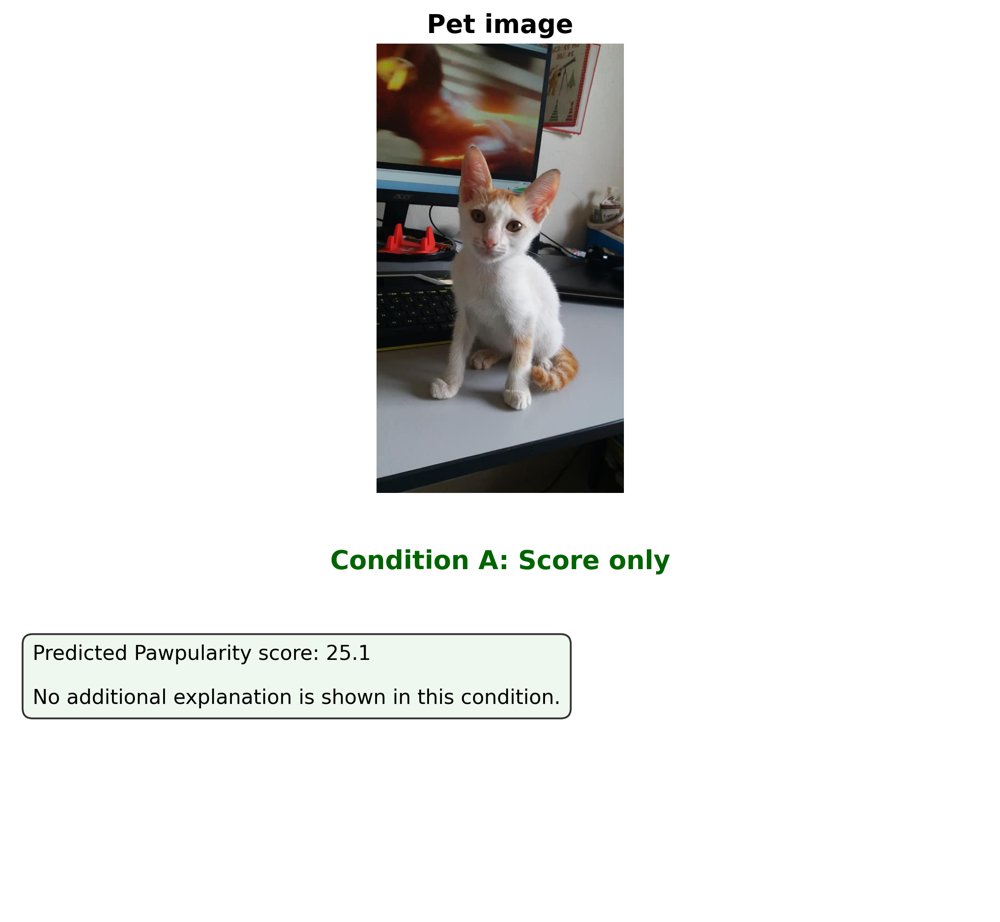

../../outputs/extra/exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion/VLM_Six_Heads/six_review/vlm_full_six/survey_materials/survey_preview_images/version_1/condition_A_trial_03.png


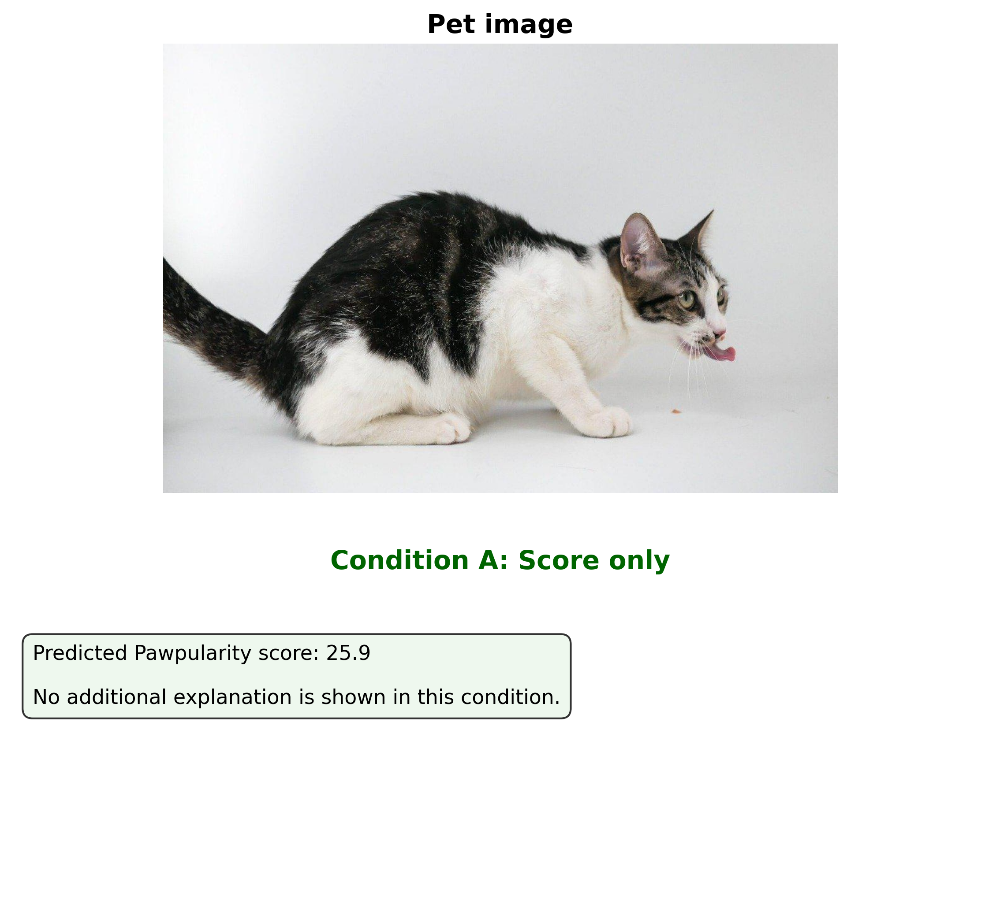

../../outputs/extra/exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion/VLM_Six_Heads/six_review/vlm_full_six/survey_materials/survey_preview_images/version_1/condition_A_trial_04.png


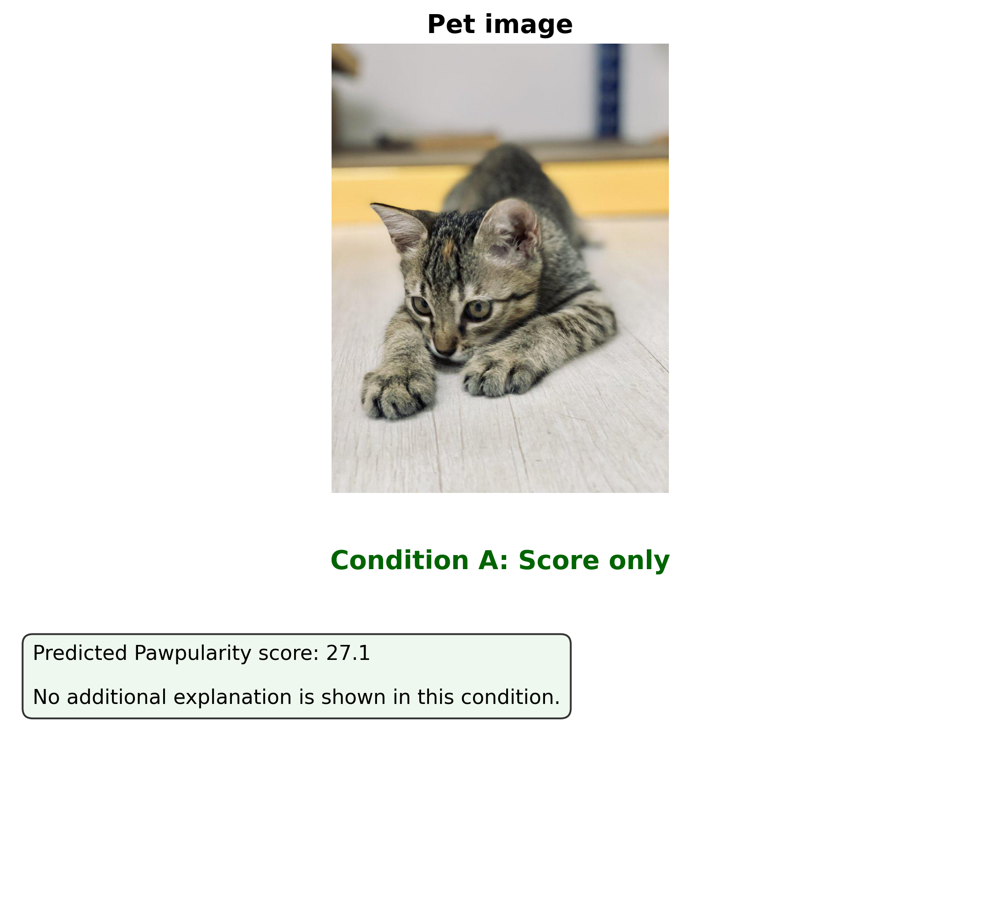

../../outputs/extra/exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion/VLM_Six_Heads/six_review/vlm_full_six/survey_materials/survey_preview_images/version_1/condition_B_trial_01.png


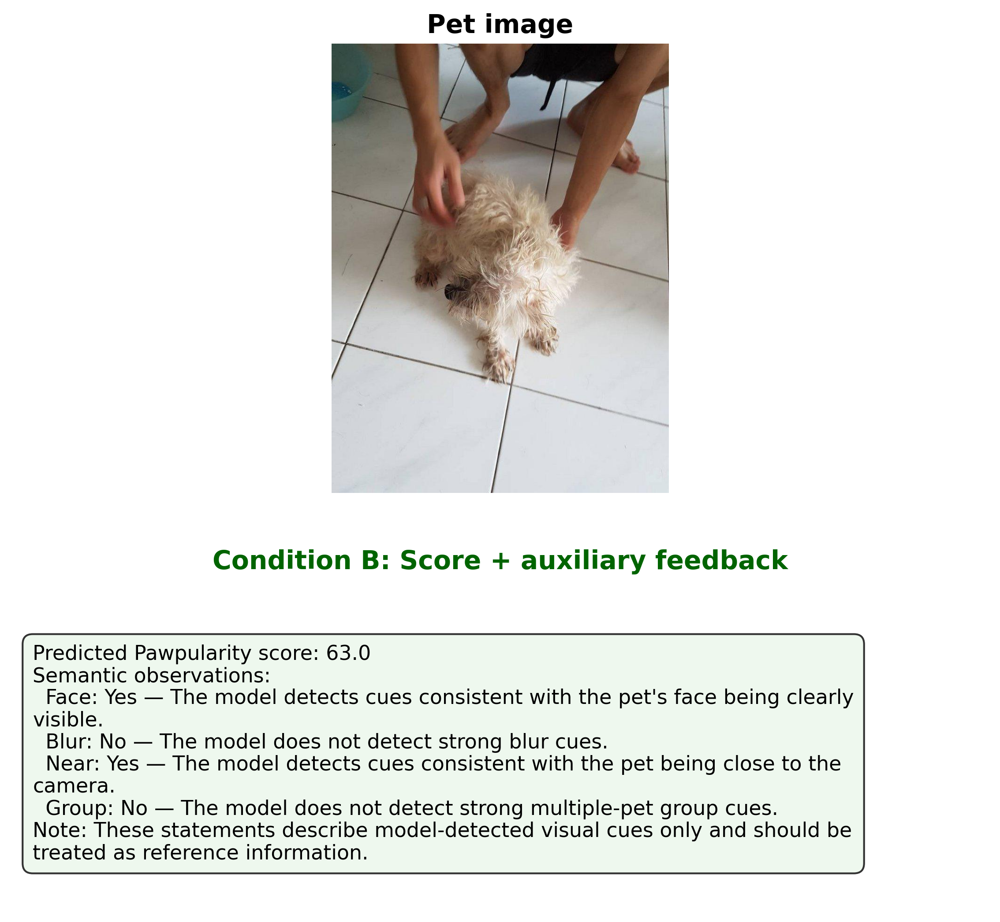

../../outputs/extra/exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion/VLM_Six_Heads/six_review/vlm_full_six/survey_materials/survey_preview_images/version_1/condition_B_trial_02.png


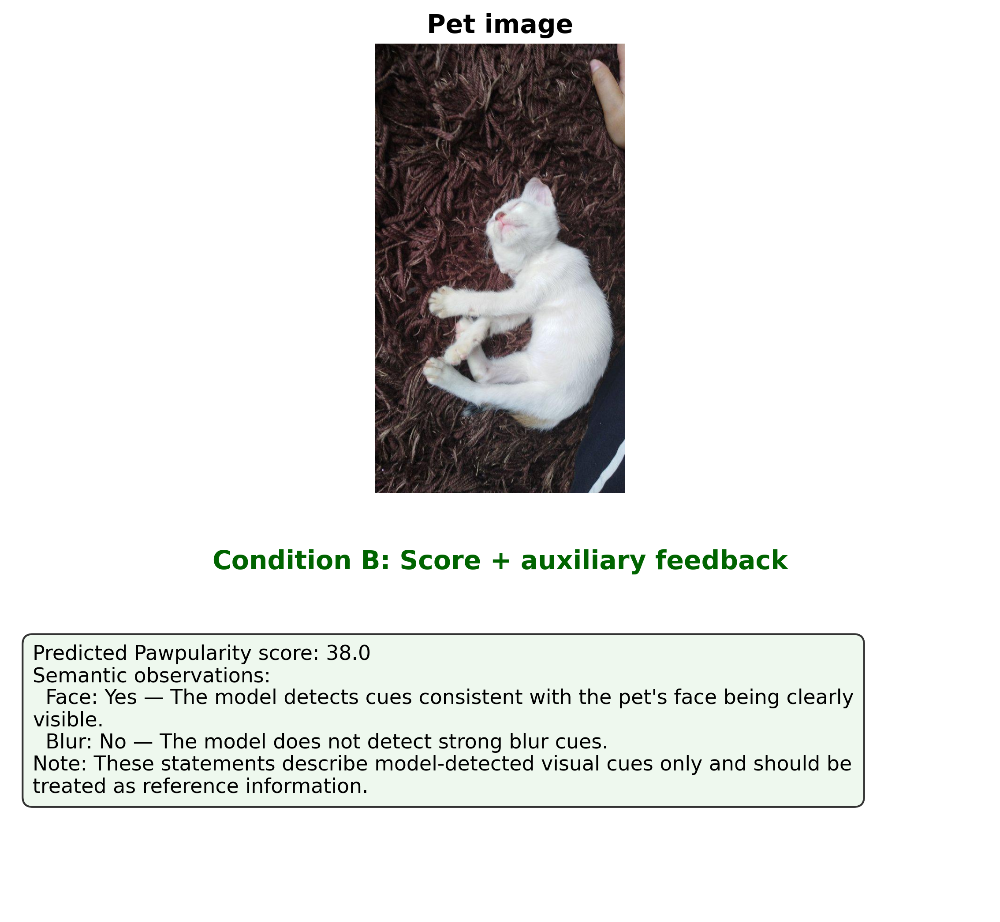

../../outputs/extra/exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion/VLM_Six_Heads/six_review/vlm_full_six/survey_materials/survey_preview_images/version_1/condition_B_trial_03.png


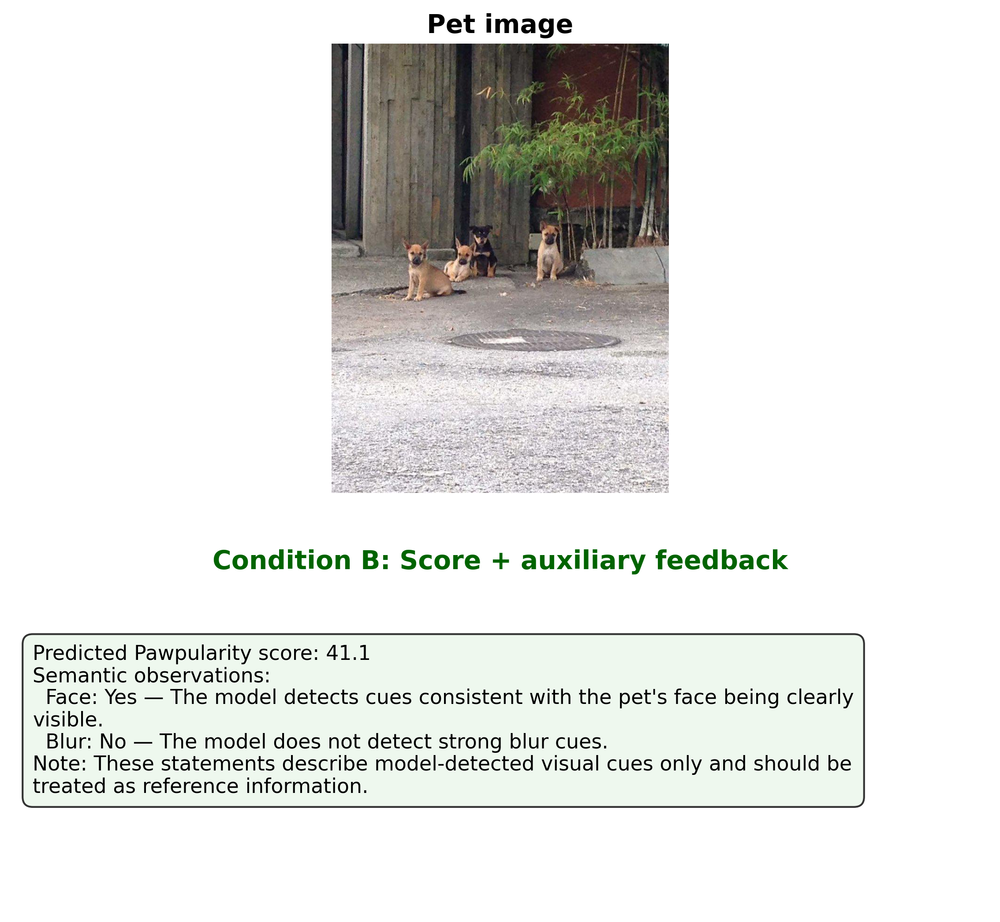

../../outputs/extra/exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion/VLM_Six_Heads/six_review/vlm_full_six/survey_materials/survey_preview_images/version_1/condition_B_trial_04.png


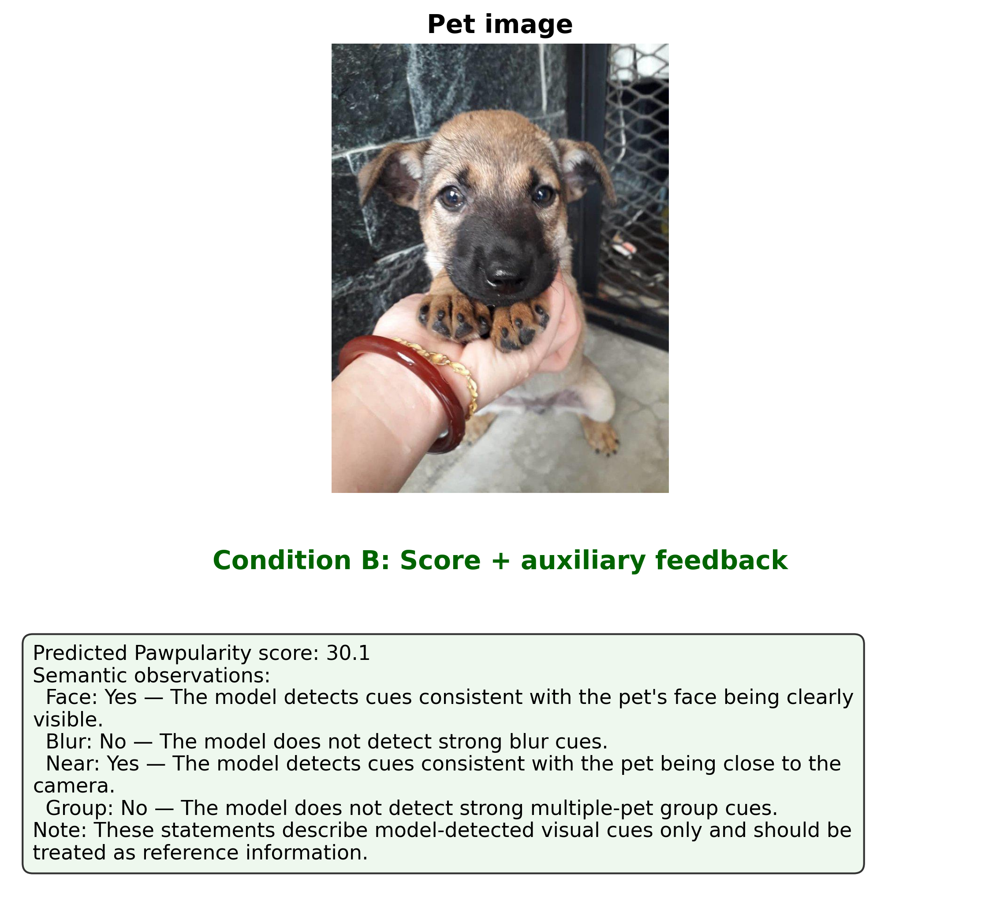

../../outputs/extra/exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion/VLM_Six_Heads/six_review/vlm_full_six/survey_materials/survey_preview_images/version_1/condition_C_trial_01.png


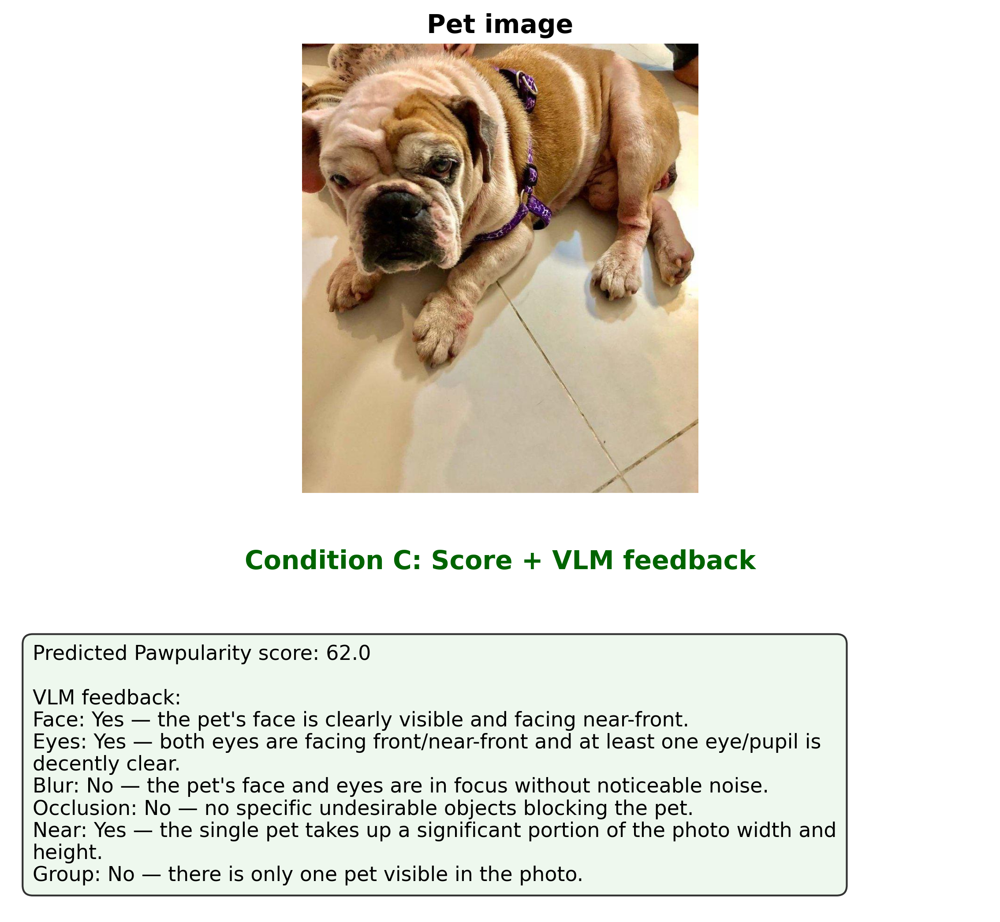

../../outputs/extra/exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion/VLM_Six_Heads/six_review/vlm_full_six/survey_materials/survey_preview_images/version_1/condition_C_trial_02.png


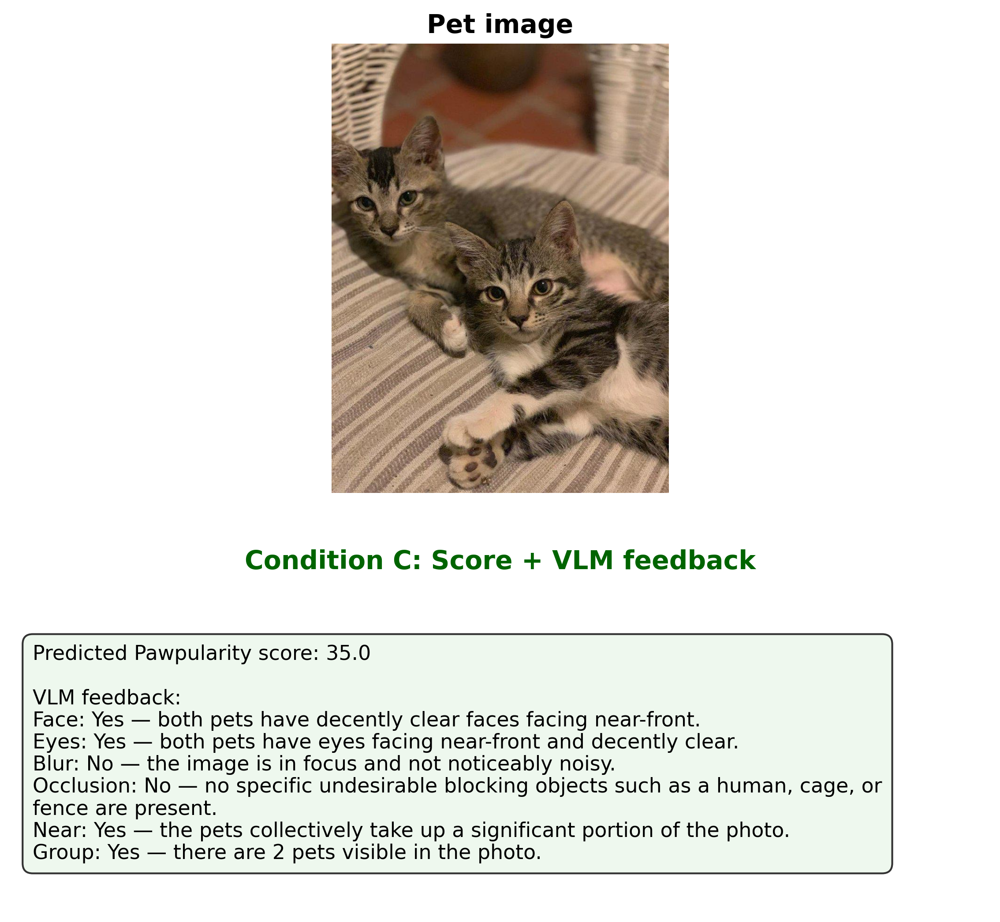

../../outputs/extra/exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion/VLM_Six_Heads/six_review/vlm_full_six/survey_materials/survey_preview_images/version_1/condition_C_trial_03.png


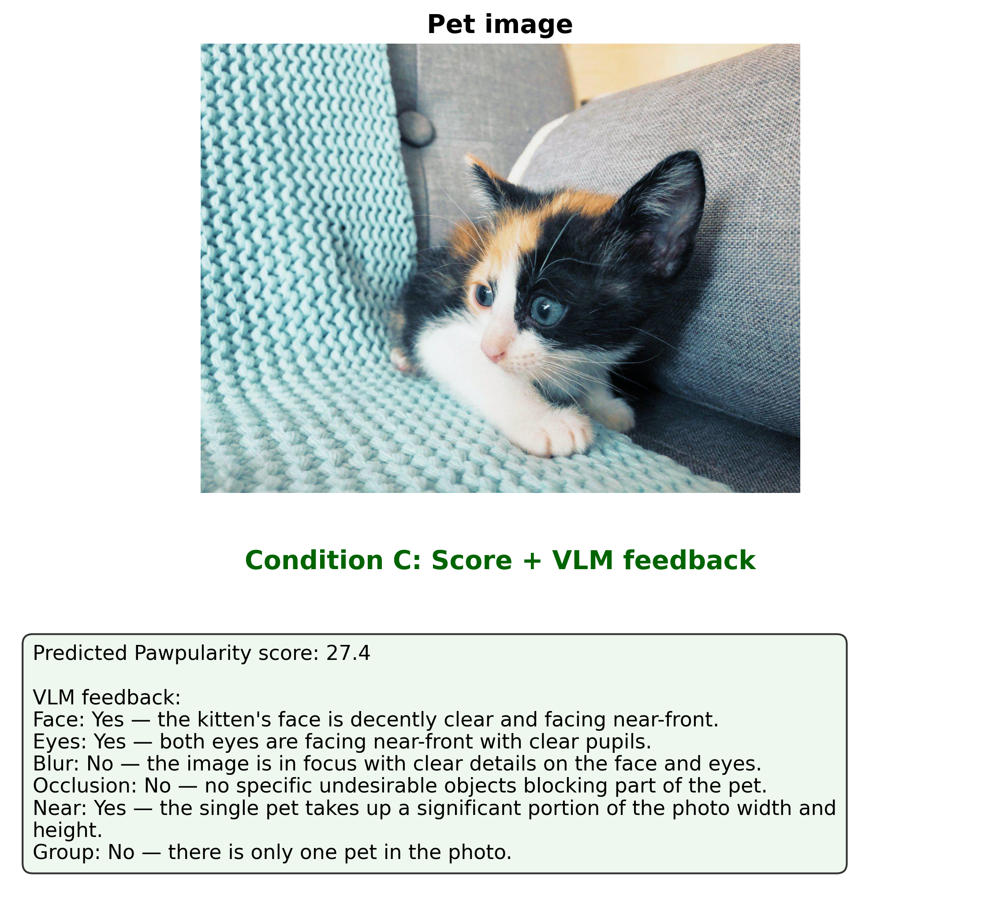

../../outputs/extra/exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion/VLM_Six_Heads/six_review/vlm_full_six/survey_materials/survey_preview_images/version_1/condition_C_trial_04.png


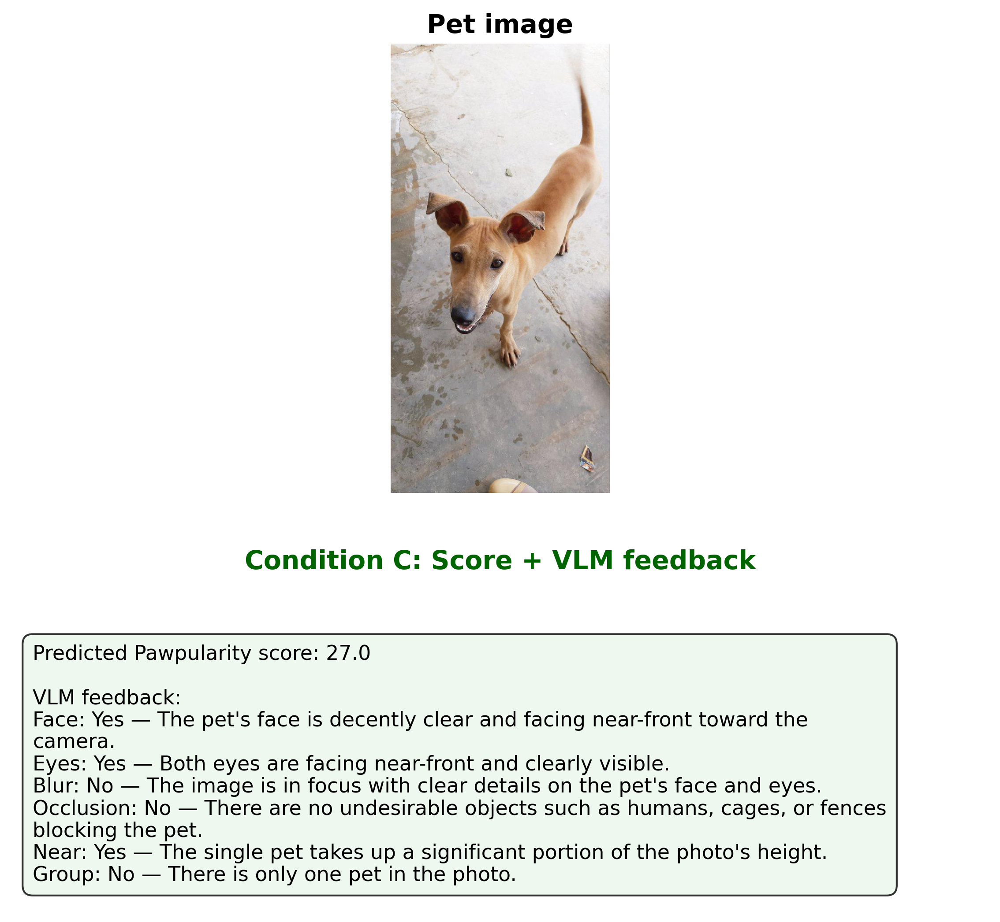

../../outputs/extra/exp19_swin_384_strong_MSELoss_All12_Aux_StrongHead_fixDupOcclusion/VLM_Six_Heads/six_review/vlm_full_six/survey_materials/survey_preview_images/version_1/condition_D_trial_01.png


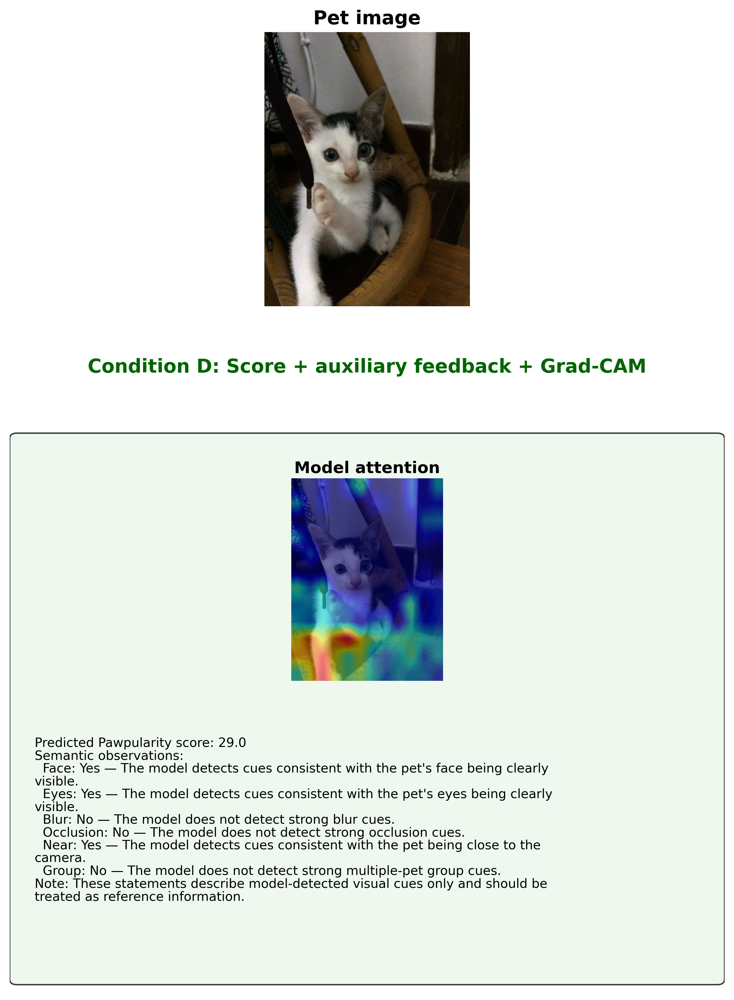

In [77]:
from IPython.display import display, Image

for i, image_path in enumerate(saved_preview_paths):
    if i == 13:
        break
    print(image_path)
    display(Image(filename=str(image_path), width=700))